# Product Analytics & Customer Intelligence Platform

## Project Overview

This end-to-end analytics project transforms retail transaction data into customer, product, retention, and predictive business insights.

The project combines **Python, SQL, statistical analysis, RFM segmentation, cohort analysis, machine learning, market-basket analysis, and interactive Plotly dashboards**.

### Business Questions

- Which customers generate the most value?
- How important are repeat customers to revenue?
- Which customer segments should receive different engagement strategies?
- How does retention evolve across acquisition cohorts?
- Which products contribute most to revenue?
- How concentrated is product revenue?
- Which products are commonly purchased together?
- Can historical customer behavior help predict future purchasing activity?
- Can historical behavior help estimate future customer revenue?

### Dataset Scope

The analysis uses the **UCI Online Retail II** transactional dataset and focuses on the cleaned positive-sales transaction history used throughout the project.

The observed period runs from **December 2009 through December 9, 2010**. December 2010 is therefore a partial month and is not treated as a complete month in monthly trend comparisons.

### Analytical Workflow

**Data Quality → Cleaning → Business Analytics → RFM Segmentation → Cohort Retention → Product Analytics → Statistical Testing → Retention Modeling → Future Revenue Modeling → Product × Customer Analysis → SQL Analytics → Executive Dashboards**

### Interpretation

This is an observational analytics project. Customer segments and predictive scores are decision-support tools rather than ground-truth labels, and observed relationships should not be interpreted as causal effects without further experimental validation.


## Phase 1 — Data Loading & Initial Quality Assessment

Load the retail transactions and establish the basic data profile: dimensions, schema, missing values, cancellations, duplicates, date coverage, countries, customers, invoices, products, quantities, prices, and raw revenue.

This phase establishes the quality issues that must be addressed before business analysis.


In [ ]:
from google.colab import files

uploaded = files.upload()

# ------------------------------------------------------------

import pandas as pd

df = pd.read_excel("online_retail_II.xlsx")

df.head()

# ------------------------------------------------------------

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

# ------------------------------------------------------------

print("Duplicate rows:", df.duplicated().sum())

print("\nUnique customers:", df["Customer ID"].nunique())

print("\nUnique invoices:", df["Invoice"].nunique())

print("\nUnique products:", df["StockCode"].nunique())

print("\nCountries:", df["Country"].nunique())

print("\nQuantity summary:")
print(df["Quantity"].describe())

print("\nUnit price summary:")
print(df["Price"].describe())

# ------------------------------------------------------------

df["Invoice"] = df["Invoice"].astype(str)

print("Total transactions:", len(df))

print("Cancellations:", df["Invoice"].str.startswith("C").sum())

print("Cancellation percentage:",
      round(df["Invoice"].str.startswith("C").mean() * 100, 2), "%")

# ------------------------------------------------------------

df["Revenue"] = df["Quantity"] * df["Price"]

df[["Quantity", "Price", "Revenue"]].head()

# ------------------------------------------------------------

print(df["Revenue"].describe())

# ------------------------------------------------------------

print("Minimum date:", df["InvoiceDate"].min())
print("Maximum date:", df["InvoiceDate"].max())

# ------------------------------------------------------------

print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

# ------------------------------------------------------------

print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())

# ------------------------------------------------------------

cancelled = df[df["Invoice"].str.startswith("C")]

print("Cancelled rows:", len(cancelled))
display(cancelled.head())

# ------------------------------------------------------------

country_counts = df["Country"].value_counts()

display(country_counts.head(20))

# ------------------------------------------------------------

customer_missing_pct = df["Customer ID"].isna().mean() * 100

print(f"Rows missing Customer ID: {df['Customer ID'].isna().sum():,}")
print(f"Percentage missing: {customer_missing_pct:.2f}%")

# ------------------------------------------------------------

duplicates = df.duplicated().sum()

print(f"Duplicate rows: {duplicates:,}")

# ------------------------------------------------------------

print("Unique invoices:", df["Invoice"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique descriptions:", df["Description"].nunique())
print("Unique customers:", df["Customer ID"].nunique())
print("Unique countries:", df["Country"].nunique())

# ------------------------------------------------------------

display(
    df["Description"]
    .value_counts()
    .head(20)
)


Saving online_retail_II.xlsx to online_retail_II.xlsx


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Shape: (525461, 8)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Duplicate rows: 6865

Unique customers: 4383

Unique invoices: 28816

Unique products: 4632

Countries: 40

Quantity summary:
count    525461.000000
mean         10.337667
std         107.424110
min       -9600.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       19152.000000
Name: Quantity, dtype: float64

Unit price summary:
count    525461.000000
mean          4.688834
std         146.126914
min      -53594.360000
25%           1.250000
50%           2.100000
75%           4.210000
max       25111.090000
Name: Price, dtype: float64


...

,count
Country,
United Kingdom,485852
EIRE,9670
Germany,8129
France,5772
Netherlands,2769
Spain,1278
Switzerland,1187
Portugal,1101
Belgium,1054


Rows missing Customer ID: 107,927
Percentage missing: 20.54%


Duplicate rows: 6,865


Unique invoices: 28816
Unique products: 4632
Unique descriptions: 4681
Unique customers: 4383
Unique countries: 40


,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,3549
REGENCY CAKESTAND 3 TIER,2212
STRAWBERRY CERAMIC TRINKET BOX,1843
PACK OF 72 RETRO SPOT CAKE CASES,1466
ASSORTED COLOUR BIRD ORNAMENT,1457
60 TEATIME FAIRY CAKE CASES,1400
HOME BUILDING BLOCK WORD,1386
JUMBO BAG RED RETROSPOT,1310
LUNCH BAG RED SPOTTY,1274


## Phase 2 — Data Cleaning & Analytical Dataset

Create the positive-sales analytical dataset by removing duplicates, transactions without customer identifiers, cancellations, non-positive quantities, and non-positive prices. Revenue is then recalculated and the cleaned dataset is validated and saved.

The cleaned transaction table becomes the common foundation for the remaining analyses.


In [ ]:
df_clean = df.copy()

print("Raw dataset:", df.shape)
print("Working dataset:", df_clean.shape)

# ------------------------------------------------------------

before = len(df_clean)

df_clean = df_clean.drop_duplicates()

after = len(df_clean)

print("Rows before:", f"{before:,}")
print("Rows after:", f"{after:,}")
print("Duplicates removed:", f"{before - after:,}")

# ------------------------------------------------------------

before = len(df_clean)

df_clean = df_clean.dropna(subset=["Customer ID"])

after = len(df_clean)

print("Rows before:", f"{before:,}")
print("Rows after:", f"{after:,}")
print("Rows removed:", f"{before - after:,}")

# ------------------------------------------------------------

df_clean["Customer ID"] = df_clean["Customer ID"].astype(int)

df_clean["Customer ID"].head()

# ------------------------------------------------------------

before = len(df_clean)

df_clean = df_clean[
    ~df_clean["Invoice"].str.startswith("C")
].copy()

after = len(df_clean)

print("Rows before:", f"{before:,}")
print("Rows after:", f"{after:,}")
print("Cancelled rows removed:", f"{before - after:,}")

# ------------------------------------------------------------

before = len(df_clean)

df_clean = df_clean[df_clean["Quantity"] > 0].copy()

after = len(df_clean)

print("Rows before:", f"{before:,}")
print("Rows after:", f"{after:,}")
print("Invalid quantity rows removed:", f"{before - after:,}")

# ------------------------------------------------------------

before = len(df_clean)

df_clean = df_clean[df_clean["Price"] > 0].copy()

after = len(df_clean)

print("Rows before:", f"{before:,}")
print("Rows after:", f"{after:,}")
print("Invalid price rows removed:", f"{before - after:,}")

# ------------------------------------------------------------

df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

display(
    df_clean[
        ["Invoice", "StockCode", "Quantity", "Price", "Revenue"]
    ].head()
)

# ------------------------------------------------------------

print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
display(df_clean.isnull().sum())

# ------------------------------------------------------------

print("Revenue statistics:")
display(df_clean["Revenue"].describe())

# ------------------------------------------------------------

df_clean.to_csv(
    "/content/online_retail_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully.")


Raw dataset: (525461, 9)
Working dataset: (525461, 9)


Rows before: 525,461
Rows after: 518,596
Duplicates removed: 6,865


Rows before: 518,596
Rows after: 410,763
Rows removed: 107,833


,Customer ID
0,13085
1,13085
2,13085
3,13085
4,13085


Rows before: 410,763
Rows after: 400,947
Cancelled rows removed: 9,816


...

Cleaned dataset shape: (400916, 9)

Missing values:


,0
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,0
Country,0
Revenue,0


Revenue statistics:


,Revenue
count,400916.000000
mean,21.945330
std,77.758075
min,0.001000
25%,5.000000
50%,12.500000
75%,19.500000
max,15818.400000


Cleaned dataset saved successfully.


## Phase 3 — Core Business & Exploratory Analytics

Build reusable customer, product, country, and monthly summaries. This phase examines customer value, order behavior, product performance, geographic performance, revenue trends, and the prevalence of repeat purchasing.

These summaries provide the descriptive business context used by later segmentation and predictive analyses.


In [ ]:
transactions = df_clean.copy()

print("Transactions:", transactions.shape)
display(transactions.head())

# ------------------------------------------------------------

customer_summary = (
    transactions
    .groupby("Customer ID")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_orders=("Invoice", "nunique"),
        total_items=("Quantity", "sum"),
        unique_products=("StockCode", "nunique"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

display(customer_summary.head())

# ------------------------------------------------------------

customer_summary["avg_order_value"] = (
    customer_summary["total_revenue"] /
    customer_summary["total_orders"]
)

display(customer_summary.head())

# ------------------------------------------------------------

print("Number of customers:", len(customer_summary))
print("Columns:", customer_summary.columns.tolist())

# ------------------------------------------------------------

product_summary = (
    transactions
    .groupby(["StockCode", "Description"])
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        total_orders=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique")
    )
    .reset_index()
)

display(product_summary.head())

# ------------------------------------------------------------

product_summary["avg_price"] = (
    product_summary["total_revenue"] /
    product_summary["total_quantity"]
)

display(product_summary.head())

# ------------------------------------------------------------

top_products_revenue = (
    product_summary
    .sort_values("total_revenue", ascending=False)
    .head(20)
)

display(top_products_revenue)

# ------------------------------------------------------------

top_products_quantity = (
    product_summary
    .sort_values("total_quantity", ascending=False)
    .head(20)
)

display(top_products_quantity)

# ------------------------------------------------------------

country_summary = (
    transactions
    .groupby("Country")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_orders=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        total_items=("Quantity", "sum")
    )
    .reset_index()
)

display(country_summary.sort_values(
    "total_revenue",
    ascending=False
).head(20))

# ------------------------------------------------------------

country_summary["avg_order_value"] = (
    country_summary["total_revenue"] /
    country_summary["total_orders"]
)

display(
    country_summary.sort_values(
        "total_revenue",
        ascending=False
    ).head(20)
)

# ------------------------------------------------------------

transactions["YearMonth"] = (
    transactions["InvoiceDate"]
    .dt.to_period("M")
)

monthly_revenue = (
    transactions
    .groupby("YearMonth")
    .agg(
        revenue=("Revenue", "sum"),
        orders=("Invoice", "nunique"),
        customers=("Customer ID", "nunique")
    )
    .reset_index()
)

display(monthly_revenue)

# ------------------------------------------------------------

monthly_revenue["avg_order_value"] = (
    monthly_revenue["revenue"] /
    monthly_revenue["orders"]
)

display(monthly_revenue)

# ------------------------------------------------------------

highest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmax()
]

display(highest_month)

# ------------------------------------------------------------

lowest_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmin()
]

display(lowest_month)

# ------------------------------------------------------------

monthly_revenue["revenue_growth_pct"] = (
    monthly_revenue["revenue"]
    .pct_change() * 100
)

display(monthly_revenue)

# ------------------------------------------------------------

customer_summary["orders_per_customer"] = (
    customer_summary["total_orders"]
)

print(
    customer_summary["orders_per_customer"]
    .describe()
)

# ------------------------------------------------------------

customer_summary["is_repeat_customer"] = (
    customer_summary["total_orders"] > 1
)

repeat_rate = (
    customer_summary["is_repeat_customer"].mean() * 100
)

print(f"Repeat customer rate: {repeat_rate:.2f}%")

# ------------------------------------------------------------

print(
    customer_summary["total_revenue"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# ------------------------------------------------------------

customer_summary.to_csv(
    "/content/customer_summary.csv",
    index=False
)

product_summary.to_csv(
    "/content/product_summary.csv",
    index=False
)

country_summary.to_csv(
    "/content/country_summary.csv",
    index=False
)

monthly_revenue.to_csv(
    "/content/monthly_revenue.csv",
    index=False
)

print("All analytical tables saved successfully.")


Transactions: (400916, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


,Customer ID,total_revenue,total_orders,total_items,unique_products,first_purchase,last_purchase
0,12346,372.86,11,70,26,2009-12-14 08:34:00,2010-06-28 13:53:00
1,12347,1323.32,2,828,70,2010-10-31 14:20:00,2010-12-07 14:57:00
2,12348,222.16,1,373,20,2010-09-27 14:59:00,2010-09-27 14:59:00
3,12349,2671.14,3,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00
4,12351,300.93,1,261,21,2010-11-29 15:23:00,2010-11-29 15:23:00


,Customer ID,total_revenue,total_orders,total_items,unique_products,first_purchase,last_purchase,avg_order_value
0,12346,372.86,11,70,26,2009-12-14 08:34:00,2010-06-28 13:53:00,33.896364
1,12347,1323.32,2,828,70,2010-10-31 14:20:00,2010-12-07 14:57:00,661.660000
2,12348,222.16,1,373,20,2010-09-27 14:59:00,2010-09-27 14:59:00,222.160000
3,12349,2671.14,3,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,890.380000
4,12351,300.93,1,261,21,2010-11-29 15:23:00,2010-11-29 15:23:00,300.930000


Number of customers: 4312
Columns: ['Customer ID', 'total_revenue', 'total_orders', 'total_items', 'unique_products', 'first_purchase', 'last_purchase', 'avg_order_value']


...

,YearMonth,revenue,orders,customers,avg_order_value,revenue_growth_pct
0,2009-12,683504.010,1512,955,452.052917,NaN
1,2010-01,555802.672,1011,720,549.755363,-18.683334
2,2010-02,504558.956,1104,772,457.028040,-9.219768
3,2010-03,696978.471,1524,1057,457.334955,38.136181
4,2010-04,591982.002,1329,942,445.434163,-15.064521
5,2010-05,597833.380,1377,966,434.156412,0.988438
6,2010-06,636371.130,1497,1041,425.097615,6.446236
7,2010-07,589736.170,1381,928,427.035605,-7.328265
8,2010-08,602224.600,1293,911,465.757618,2.117630
9,2010-09,829013.951,1689,1145,490.831232,37.658600


count    4312.000000
mean        4.455705
std         8.170213
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       205.000000
Name: orders_per_customer, dtype: float64


Repeat customer rate: 67.09%


count      4312.000000
mean       2040.406712
std        8911.755977
min           2.950000
25%         307.187500
50%         701.615000
75%        1714.932500
90%        3776.791000
95%        6191.097500
99%       20004.390600
max      349164.350000
Name: total_revenue, dtype: float64


All analytical tables saved successfully.


## Phase 4 — RFM Customer Segmentation

Segment customers using **Recency, Frequency, and Monetary value**. The reference date is derived from the latest observed transaction date plus one day, avoiding an arbitrary fixed cutoff.

Customers are grouped into business-oriented segments such as **Champions, Loyal Customers, Potential Loyalists, Needs Attention, and At Risk**. These are rule-based analytical segments, not ground-truth labels.


In [ ]:
customer_transactions = transactions.copy()

customer_transactions["Invoice"] = (
    customer_transactions["Invoice"].astype(str)
)

print(customer_transactions.shape)

# ------------------------------------------------------------

non_product_codes = ["POST", "M"]

product_transactions = customer_transactions[
    ~customer_transactions["StockCode"].isin(non_product_codes)
].copy()

print("Original transactions:", len(customer_transactions))
print("Product transactions:", len(product_transactions))
print("Removed non-product rows:",
      len(customer_transactions) - len(product_transactions))

# ------------------------------------------------------------

print(
    product_transactions[
        ["StockCode", "Description", "Quantity", "Price", "Revenue"]
    ].head()
)

# ------------------------------------------------------------

latest_date = customer_transactions["InvoiceDate"].max()

print("Latest transaction:", latest_date)

# ------------------------------------------------------------

reference_date = latest_date + pd.Timedelta(days=1)

print("RFM reference date:", reference_date)

# ------------------------------------------------------------

rfm = (
    customer_transactions
    .groupby("Customer ID")
    .agg(
        last_purchase=("InvoiceDate", "max"),
        frequency=("Invoice", "nunique"),
        monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm["recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days

display(rfm.head())

# ------------------------------------------------------------

print(rfm["recency"].describe())

# ------------------------------------------------------------

negative_recency = (
    rfm["recency"] < 0
).sum()

print("Negative recency values:", negative_recency)

# ------------------------------------------------------------

rfm = rfm[
    [
        "Customer ID",
        "recency",
        "frequency",
        "monetary",
        "last_purchase"
    ]
]

display(rfm.head())

# ------------------------------------------------------------

rfm["R_score"] = pd.qcut(
    rfm["recency"],
    q=5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

display(
    rfm[
        ["Customer ID", "recency", "R_score"]
    ].head()
)

# ------------------------------------------------------------

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

display(
    rfm[
        ["Customer ID", "frequency", "F_score"]
    ].head()
)

# ------------------------------------------------------------

rfm["M_score"] = pd.qcut(
    rfm["monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

display(
    rfm[
        ["Customer ID", "monetary", "M_score"]
    ].head()
)

# ------------------------------------------------------------

rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

display(rfm.head())

# ------------------------------------------------------------

rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

display(
    rfm[
        [
            "Customer ID",
            "recency",
            "frequency",
            "monetary",
            "RFM_score"
        ]
    ].head()
)

# ------------------------------------------------------------

rfm["RFM_total"] = (
    rfm["R_score"] +
    rfm["F_score"] +
    rfm["M_score"]
)

display(
    rfm.sort_values(
        "RFM_total",
        ascending=False
    ).head(20)
)

# ------------------------------------------------------------

def segment_customer(row):
    if row["RFM_total"] >= 13:
        return "Champions"
    elif row["RFM_total"] >= 10:
        return "Loyal Customers"
    elif row["RFM_total"] >= 8:
        return "Potential Loyalists"
    elif row["RFM_total"] >= 6:
        return "Needs Attention"
    else:
        return "At Risk"

rfm["segment"] = rfm.apply(
    segment_customer,
    axis=1
)

display(rfm.head(20))

# ------------------------------------------------------------

segment_counts = (
    rfm["segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = [
    "segment",
    "customers"
]

display(segment_counts)

# ------------------------------------------------------------

segment_counts["percentage"] = (
    segment_counts["customers"] /
    segment_counts["customers"].sum()
    * 100
)

display(segment_counts)

# ------------------------------------------------------------

segment_revenue = (
    rfm
    .groupby("segment")
    .agg(
        customers=("Customer ID", "count"),
        revenue=("monetary", "sum"),
        avg_customer_revenue=("monetary", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_recency=("recency", "mean")
    )
    .reset_index()
)

display(segment_revenue)

# ------------------------------------------------------------

segment_revenue["revenue_share_pct"] = (
    segment_revenue["revenue"] /
    segment_revenue["revenue"].sum()
    * 100
)

display(segment_revenue)

# ------------------------------------------------------------

largest_segment = segment_counts.loc[
    segment_counts["customers"].idxmax()
]

display(largest_segment)

# ------------------------------------------------------------

largest_revenue_segment = segment_revenue.loc[
    segment_revenue["revenue"].idxmax()
]

display(largest_revenue_segment)

# ------------------------------------------------------------

rfm.to_csv(
    "/content/customer_rfm_corrected.csv",
    index=False
)

segment_counts.to_csv(
    "/content/rfm_segment_counts.csv",
    index=False
)

segment_revenue.to_csv(
    "/content/rfm_segment_revenue.csv",
    index=False
)

print("Corrected RFM analysis saved successfully.")


(400916, 10)


Original transactions: 400916
Product transactions: 399758
Removed non-product rows: 1158


  StockCode                          Description  Quantity  Price  Revenue
0     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   6.95     83.4
1    79323P                   PINK CHERRY LIGHTS        12   6.75     81.0
2    79323W                  WHITE CHERRY LIGHTS        12   6.75     81.0
3     22041         RECORD FRAME 7" SINGLE SIZE         48   2.10    100.8
4     21232       STRAWBERRY CERAMIC TRINKET BOX        24   1.25     30.0


Latest transaction: 2010-12-09 20:01:00


RFM reference date: 2010-12-10 20:01:00


...

,segment,customers,revenue,avg_customer_revenue,avg_frequency,avg_recency
0,At Risk,912,207531.812,227.556811,1.070175,215.591009
1,Champions,920,5950360.088,6467.782704,12.225000,15.717391
2,Loyal Customers,1025,1721931.782,1679.933446,4.103415,47.762927
3,Needs Attention,724,325401.372,449.449409,1.513812,105.825967
4,Potential Loyalists,731,593008.690,811.229398,2.309166,77.262654


,segment,customers,revenue,avg_customer_revenue,avg_frequency,avg_recency,revenue_share_pct
0,At Risk,912,207531.812,227.556811,1.070175,215.591009,2.358789
1,Champions,920,5950360.088,6467.782704,12.225000,15.717391,67.631303
2,Loyal Customers,1025,1721931.782,1679.933446,4.103415,47.762927,19.571335
3,Needs Attention,724,325401.372,449.449409,1.513812,105.825967,3.698485
4,Potential Loyalists,731,593008.690,811.229398,2.309166,77.262654,6.740088


,0
segment,Loyal Customers
customers,1025
percentage,23.770872


,1
segment,Champions
customers,920
revenue,5950360.088
avg_customer_revenue,6467.782704
avg_frequency,12.225
avg_recency,15.717391
revenue_share_pct,67.631303


Corrected RFM analysis saved successfully.


## Phase 5 — Cohort Retention Analysis

Group customers by first-purchase month and measure the percentage returning in subsequent months.

Cohort analysis complements the overall repeat-customer rate by showing retention longitudinally. Later cohorts have shorter observation windows, so their later-month retention values are naturally right-censored.


(400916, 10)


,Customer ID,InvoiceDate,PurchaseMonth
0,13085,2009-12-01 07:45:00,2009-12
1,13085,2009-12-01 07:45:00,2009-12
2,13085,2009-12-01 07:45:00,2009-12
3,13085,2009-12-01 07:45:00,2009-12
4,13085,2009-12-01 07:45:00,2009-12


,Customer ID,PurchaseMonth,CohortMonth
0,13085,2009-12,2009-12
1,13085,2009-12,2009-12
2,13085,2009-12,2009-12
3,13085,2009-12,2009-12
4,13085,2009-12,2009-12
5,13085,2009-12,2009-12
6,13085,2009-12,2009-12
7,13085,2009-12,2009-12
8,13085,2009-12,2009-12
9,13085,2009-12,2009-12


,Customer ID,PurchaseMonth,CohortMonth,CohortIndex
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0
5,13085,2009-12,2009-12,0
6,13085,2009-12,2009-12,0
7,13085,2009-12,2009-12,0
8,13085,2009-12,2009-12,0
9,13085,2009-12,2009-12,0


count    400916.000000
mean          4.022718
std           3.802765
min           0.000000
25%           0.000000
50%           3.000000
75%           7.000000
max          12.000000
Name: CohortIndex, dtype: float64
Negative cohort indexes: 0


...

Average Month 3 retention: 25.19%


Average Month 6 retention: 23.27%


Number of customer cohorts: 13


,CohortMonth,Customers
0,2009-12,955.0
3,2010-03,443.0
1,2010-01,383.0
10,2010-10,377.0
2,2010-02,374.0
11,2010-11,325.0
4,2010-04,294.0
6,2010-06,270.0
5,2010-05,254.0
9,2010-09,243.0


Cohort analysis saved.


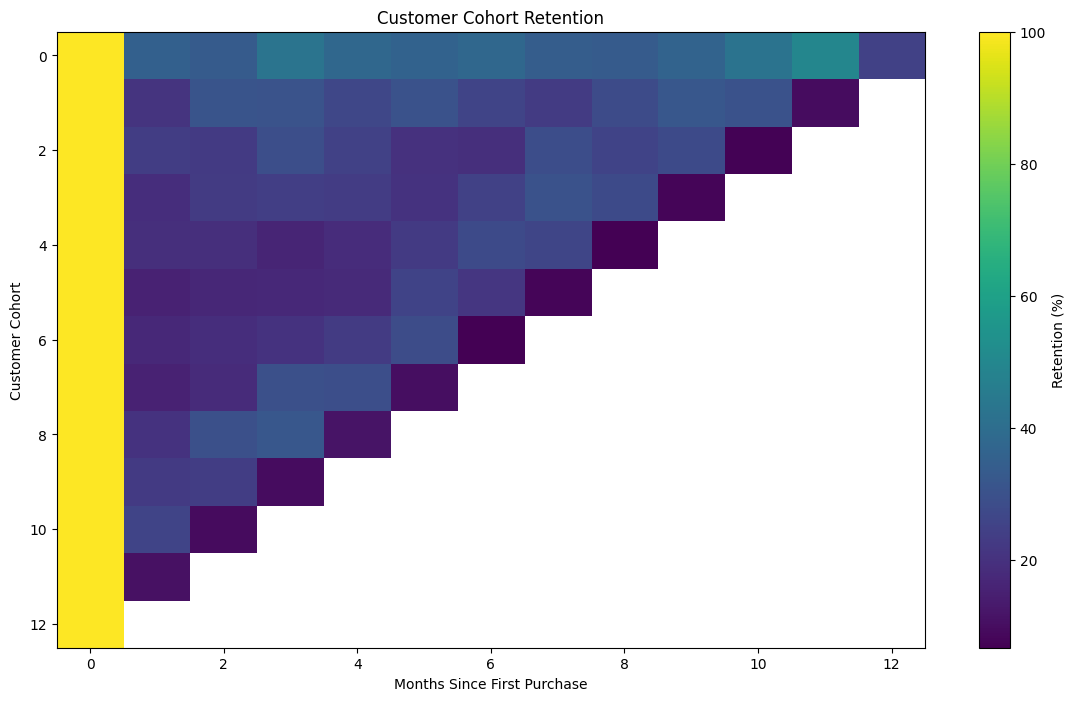

In [ ]:
cohort_df = customer_transactions.copy()

print(cohort_df.shape)

# ------------------------------------------------------------

cohort_df["PurchaseMonth"] = (
    cohort_df["InvoiceDate"]
    .dt.to_period("M")
)

display(
    cohort_df[
        ["Customer ID", "InvoiceDate", "PurchaseMonth"]
    ].head()
)

# ------------------------------------------------------------

cohort_df["CohortMonth"] = (
    cohort_df
    .groupby("Customer ID")["PurchaseMonth"]
    .transform("min")
)

display(
    cohort_df[
        ["Customer ID", "PurchaseMonth", "CohortMonth"]
    ].head(20)
)

# ------------------------------------------------------------

cohort_df["CohortIndex"] = (
    (cohort_df["PurchaseMonth"].dt.year -
     cohort_df["CohortMonth"].dt.year) * 12
    +
    (cohort_df["PurchaseMonth"].dt.month -
     cohort_df["CohortMonth"].dt.month)
)

display(
    cohort_df[
        [
            "Customer ID",
            "PurchaseMonth",
            "CohortMonth",
            "CohortIndex"
        ]
    ].head(20)
)

# ------------------------------------------------------------

print(
    cohort_df["CohortIndex"].describe()
)

print(
    "Negative cohort indexes:",
    (cohort_df["CohortIndex"] < 0).sum()
)

# ------------------------------------------------------------

cohort_counts = (
    cohort_df
    .groupby(
        ["CohortMonth", "CohortIndex"]
    )["Customer ID"]
    .nunique()
    .reset_index()
)

display(cohort_counts.head(20))

# ------------------------------------------------------------

cohort_matrix = (
    cohort_counts
    .pivot(
        index="CohortMonth",
        columns="CohortIndex",
        values="Customer ID"
    )
)

display(cohort_matrix)

# ------------------------------------------------------------

cohort_sizes = cohort_matrix.iloc[:, 0]

retention_matrix = (
    cohort_matrix
    .divide(cohort_sizes, axis=0)
    * 100
)

display(retention_matrix)

# ------------------------------------------------------------

retention_matrix = retention_matrix.round(2)

display(retention_matrix)

# ------------------------------------------------------------

print(
    retention_matrix.iloc[:, 0]
)

# ------------------------------------------------------------

average_retention = (
    retention_matrix.mean(axis=0)
)

display(average_retention)

# ------------------------------------------------------------

median_retention = (
    retention_matrix.median(axis=0)
)

display(median_retention)

# ------------------------------------------------------------

month_1_retention = (
    retention_matrix[1].mean()
)

print(
    f"Average Month 1 retention: "
    f"{month_1_retention:.2f}%"
)

# ------------------------------------------------------------

month_3_retention = (
    retention_matrix[3].mean()
)

print(
    f"Average Month 3 retention: "
    f"{month_3_retention:.2f}%"
)

# ------------------------------------------------------------

month_6_retention = (
    retention_matrix[6].mean()
)

print(
    f"Average Month 6 retention: "
    f"{month_6_retention:.2f}%"
)

# ------------------------------------------------------------

print(
    "Number of customer cohorts:",
    retention_matrix.shape[0]
)

# ------------------------------------------------------------

cohort_sizes_df = (
    cohort_sizes
    .reset_index()
)

cohort_sizes_df.columns = [
    "CohortMonth",
    "Customers"
]

largest_cohort = (
    cohort_sizes_df
    .sort_values(
        "Customers",
        ascending=False
    )
    .head(10)
)

display(largest_cohort)

# ------------------------------------------------------------

retention_matrix.to_csv(
    "/content/cohort_retention_matrix.csv"
)

cohort_sizes_df.to_csv(
    "/content/cohort_sizes.csv",
    index=False
)

print("Cohort analysis saved.")

# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

plt.imshow(
    retention_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Retention (%)"
)

plt.title(
    "Customer Cohort Retention"
)

plt.xlabel(
    "Months Since First Purchase"
)

plt.ylabel(
    "Customer Cohort"
)

plt.show()


## Phase 6 — Product Performance Analytics

Analyze product revenue, quantity, orders, and customer reach using normalized StockCode-level aggregation. Where a StockCode has multiple descriptions, a representative description is selected separately so the same product is not incorrectly split across descriptions.

The phase also measures product revenue concentration and identifies high-revenue/high-reach product groups.


Product analysis shape: (399758, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12


Unique products: 4015
Unique customers: 4296
Unique orders: 19039
Total revenue: 8650960.674000002


Products with multiple descriptions: 424


,Description
StockCode,
22344,4
22345,4
22346,4
20685,4
22384,4
21955,4
22852,3
22853,3
20750,3


...

,StockCode,total_revenue,total_quantity,total_orders,unique_customers,avg_price,Description,revenue_share_pct,cumulative_revenue_pct,revenue_per_customer
40,84078A,23252.50,650,128,86,38.192188,SET/4 WHITE RETRO STORAGE CUBES,0.268785,17.785200,270.377907
21,21137,28129.89,8219,237,108,3.586639,BLACK RECORD COVER FRAME,0.325165,12.218861,260.461944
6,84347,40156.05,21579,244,177,2.505333,ROTATING SILVER ANGELS T-LIGHT HLDR,0.464180,6.628772,226.870339
1,22423,143727.60,12484,1687,818,12.436667,REGENCY CAKESTAND 3 TIER,1.661406,3.410798,175.706112
146,15044A,11573.20,4472,116,81,2.915517,PINK PAPER PARASOL,0.133779,37.459461,142.879012
10,15056N,34044.75,7201,496,245,5.729175,EDWARDIAN PARASOL NATURAL,0.393537,8.274262,138.958163
20,21623,28746.54,3902,310,213,9.767194,VINTAGE UNION JACK MEMOBOARD,0.332293,11.893697,134.960282
27,79321,26262.68,6012,434,197,4.769447,CHILLI LIGHTS,0.303581,14.101944,133.313096
0,85123A,151339.16,56814,3021,1141,2.854422,WHITE HANGING HEART T-LIGHT HOLDER,1.749391,1.749391,132.637301
276,22041,7338.30,3350,136,56,2.398905,"RECORD FRAME 7"" SINGLE SIZE",0.084826,51.079003,131.041071


,StockCode,total_revenue,total_quantity,total_orders,unique_customers,avg_price,Description,revenue_share_pct,cumulative_revenue_pct,revenue_per_customer,revenue_per_order
562,22790,3884.00,200,1,1,19.420000,"MIRROR, ARCHED GEORGIAN",0.044897,68.815577,3884.000000,3884.000000
1181,15059A,1515.00,505,1,1,3.000000,ENGLISH ROSE EDWARDIAN PARASOL,0.017513,86.360479,1515.000000,1515.000000
293,85220,6875.00,12236,5,4,1.300000,SMALL FAIRY CAKE FRIDGE MAGNETS,0.079471,52.476219,1718.750000,1375.000000
1629,84760L,896.00,560,1,1,1.600000,LARGE HANGING GLASS+ZINC LANTERN,0.010357,92.444512,896.000000,896.000000
1534,84964B,990.00,17,2,2,45.000000,BLUE PAINTED KASHMIRI TABLE,0.011444,91.407015,495.000000,495.000000
555,22833,3913.69,116,9,7,41.786667,HALL CABINET WITH 3 DRAWERS,0.045240,68.500451,559.098571,434.854444
2263,20715,424.00,400,1,1,1.060000,LITTLE FLOWER SHOPPER BAG,0.004901,97.066142,424.000000,424.000000
2313,16243B,399.75,205,1,1,1.950000,BROWN COZY SQUARE PHOTO ALBUM,0.004621,97.304747,399.750000,399.750000
2390,35915A,365.76,288,1,1,1.270000,CREAM KNITTED HEN,0.004228,97.644561,365.760000,365.760000
1480,84965A,1050.00,20,3,2,40.000000,PINK KASHMIRI COFFEE TABLE,0.012137,90.771713,525.000000,350.000000


,count
product_type,
High Revenue / High Reach,1753
Other,1745
Low Revenue / High Reach,262
High Revenue / Low Reach,255


,StockCode,Description,total_revenue,unique_customers,total_orders,total_quantity
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,151339.16,1141,3021,56814
1,22423,REGENCY CAKESTAND 3 TIER,143727.60,818,1687,12484
2,85099B,JUMBO BAG RED RETROSPOT,85257.45,692,1708,48731
3,84879,ASSORTED COLOUR BIRD ORNAMENT,70291.03,627,1333,44431
4,21843,RED RETROSPOT CAKE STAND,41457.64,467,895,4056
5,48138,DOOR MAT UNION FLAG,41223.56,528,1016,6342
6,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,40156.05,177,244,21579
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,36871.55,505,796,13839
8,20685,DOOR MAT RED SPOT,36417.04,472,934,5642
9,47566,PARTY BUNTING,35017.30,391,710,8312


Corrected product analytics saved successfully.


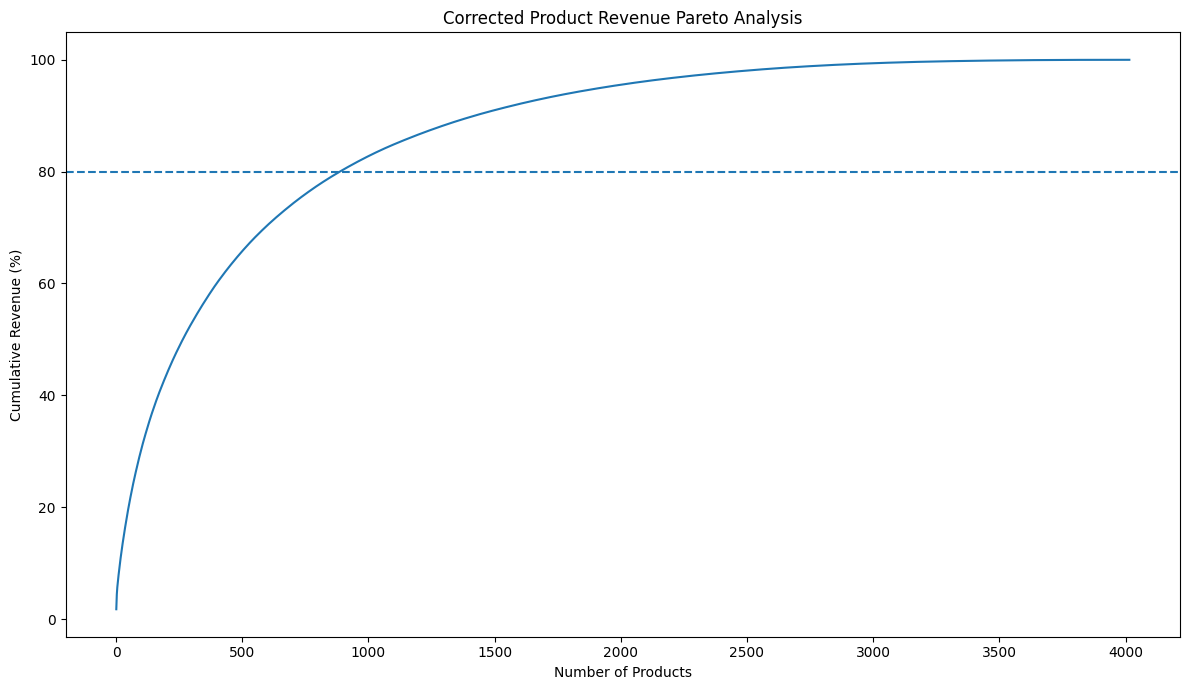

In [ ]:
product_analysis = customer_transactions[
    ~customer_transactions["StockCode"].isin(["POST", "M"])
].copy()

print("Product analysis shape:", product_analysis.shape)
display(product_analysis.head())

# ------------------------------------------------------------

print("Unique products:", product_analysis["StockCode"].nunique())
print("Unique customers:", product_analysis["Customer ID"].nunique())
print("Unique orders:", product_analysis["Invoice"].nunique())
print("Total revenue:", product_analysis["Revenue"].sum())

# ------------------------------------------------------------

description_counts = (
    product_analysis
    .groupby("StockCode")["Description"]
    .nunique()
    .sort_values(ascending=False)
)

print("Products with multiple descriptions:",
      (description_counts > 1).sum())

display(
    description_counts[description_counts > 1].head(20)
)

# ------------------------------------------------------------

multi_description_codes = description_counts[
    description_counts > 1
].index

conflicting_descriptions = (
    product_analysis[
        product_analysis["StockCode"].isin(multi_description_codes)
    ][["StockCode", "Description"]]
    .drop_duplicates()
    .copy()
)

# Convert only the temporary sorting column to string
conflicting_descriptions["StockCode_sort"] = (
    conflicting_descriptions["StockCode"].astype(str)
)

conflicting_descriptions = (
    conflicting_descriptions
    .sort_values("StockCode_sort")
    .drop(columns="StockCode_sort")
)

display(conflicting_descriptions.head(50))

# ------------------------------------------------------------

product_descriptions = (
    product_analysis
    .groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="description_count")
    .sort_values(
        ["StockCode", "description_count"],
        ascending=[True, False]
    )
    .drop_duplicates("StockCode")
)

display(product_descriptions.head(20))

# ------------------------------------------------------------

product_performance_fixed = (
    product_analysis
    .groupby("StockCode")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_quantity=("Quantity", "sum"),
        total_orders=("Invoice", "nunique"),
        unique_customers=("Customer ID", "nunique"),
        avg_price=("Price", "mean")
    )
    .reset_index()
)

product_performance_fixed = product_performance_fixed.merge(
    product_descriptions[["StockCode", "Description"]],
    on="StockCode",
    how="left"
)

print("Corrected product count:",
      product_performance_fixed["StockCode"].nunique())

display(product_performance_fixed.head())

# ------------------------------------------------------------

print("Unique StockCodes in raw product analysis:",
      product_analysis["StockCode"].nunique())

print("Unique StockCodes in corrected table:",
      product_performance_fixed["StockCode"].nunique())

# ------------------------------------------------------------

product_performance_fixed = product_performance_fixed.sort_values(
    "total_revenue",
    ascending=False
).reset_index(drop=True)

product_performance_fixed["revenue_share_pct"] = (
    product_performance_fixed["total_revenue"]
    / product_performance_fixed["total_revenue"].sum()
    * 100
)

display(
    product_performance_fixed.head(10)
)

# ------------------------------------------------------------

product_performance_fixed["cumulative_revenue_pct"] = (
    product_performance_fixed["total_revenue"].cumsum()
    / product_performance_fixed["total_revenue"].sum()
    * 100
)

display(
    product_performance_fixed[
        [
            "StockCode",
            "Description",
            "total_revenue",
            "revenue_share_pct",
            "cumulative_revenue_pct"
        ]
    ].head(20)
)

# ------------------------------------------------------------

first_80_index = (
    product_performance_fixed["cumulative_revenue_pct"] >= 80
).idxmax()

products_to_80 = first_80_index + 1
total_products_fixed = len(product_performance_fixed)

print("Products needed to reach 80% revenue:", products_to_80)
print("Total products:", total_products_fixed)
print(
    "Percentage of products:",
    round(products_to_80 / total_products_fixed * 100, 2),
    "%"
)

# ------------------------------------------------------------

top_10_share_fixed = (
    product_performance_fixed.head(10)["total_revenue"].sum()
    / product_performance_fixed["total_revenue"].sum()
    * 100
)

print(f"Top 10 product revenue share: {top_10_share_fixed:.2f}%")

# ------------------------------------------------------------

top_20_share_fixed = (
    product_performance_fixed.head(20)["total_revenue"].sum()
    / product_performance_fixed["total_revenue"].sum()
    * 100
)

print(f"Top 20 product revenue share: {top_20_share_fixed:.2f}%")

# ------------------------------------------------------------

display(
    product_performance_fixed[
        [
            "StockCode",
            "Description",
            "total_revenue",
            "total_quantity",
            "total_orders",
            "unique_customers",
            "avg_price"
        ]
    ].head(10)
)

# ------------------------------------------------------------

top_quantity_fixed = (
    product_performance_fixed
    .sort_values("total_quantity", ascending=False)
    .head(10)
)

display(
    top_quantity_fixed[
        [
            "StockCode",
            "Description",
            "total_quantity",
            "total_revenue",
            "unique_customers"
        ]
    ]
)

# ------------------------------------------------------------

top_customer_reach_fixed = (
    product_performance_fixed
    .sort_values("unique_customers", ascending=False)
    .head(10)
)

display(
    top_customer_reach_fixed[
        [
            "StockCode",
            "Description",
            "unique_customers",
            "total_revenue",
            "total_quantity"
        ]
    ]
)

# ------------------------------------------------------------

product_performance_fixed["revenue_per_customer"] = (
    product_performance_fixed["total_revenue"]
    / product_performance_fixed["unique_customers"]
)

display(
    product_performance_fixed
    .sort_values("revenue_per_customer", ascending=False)
    .head(20)
)

# ------------------------------------------------------------

high_value_products = product_performance_fixed[
    product_performance_fixed["unique_customers"] >= 50
].copy()

display(
    high_value_products
    .sort_values("revenue_per_customer", ascending=False)
    .head(20)
)

# ------------------------------------------------------------

product_performance_fixed["revenue_per_order"] = (
    product_performance_fixed["total_revenue"]
    / product_performance_fixed["total_orders"]
)

display(
    product_performance_fixed
    .sort_values("revenue_per_order", ascending=False)
    .head(20)
)

# ------------------------------------------------------------

revenue_median = product_performance_fixed["total_revenue"].median()
customer_median = product_performance_fixed["unique_customers"].median()

product_performance_fixed["product_type"] = "Other"

product_performance_fixed.loc[
    (product_performance_fixed["total_revenue"] >= revenue_median) &
    (product_performance_fixed["unique_customers"] >= customer_median),
    "product_type"
] = "High Revenue / High Reach"

product_performance_fixed.loc[
    (product_performance_fixed["total_revenue"] >= revenue_median) &
    (product_performance_fixed["unique_customers"] < customer_median),
    "product_type"
] = "High Revenue / Low Reach"

product_performance_fixed.loc[
    (product_performance_fixed["total_revenue"] < revenue_median) &
    (product_performance_fixed["unique_customers"] >= customer_median),
    "product_type"
] = "Low Revenue / High Reach"

display(
    product_performance_fixed["product_type"]
    .value_counts()
)

# ------------------------------------------------------------

display(
    product_performance_fixed[
        product_performance_fixed["product_type"]
        == "High Revenue / High Reach"
    ][
        [
            "StockCode",
            "Description",
            "total_revenue",
            "unique_customers",
            "total_orders",
            "total_quantity"
        ]
    ]
    .sort_values("total_revenue", ascending=False)
    .head(20)
)

# ------------------------------------------------------------

product_performance_fixed.to_csv(
    "/content/product_performance_fixed.csv",
    index=False
)

high_value_products.to_csv(
    "/content/high_value_products.csv",
    index=False
)

print("Corrected product analytics saved successfully.")

# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

plt.plot(
    range(1, len(product_performance_fixed) + 1),
    product_performance_fixed["cumulative_revenue_pct"]
)

plt.axhline(80, linestyle="--")

plt.xlabel("Number of Products")
plt.ylabel("Cumulative Revenue (%)")
plt.title("Corrected Product Revenue Pareto Analysis")

plt.tight_layout()
plt.show()


## Phase 7 — Customer Behavior & Statistical Testing

Compare one-time and repeat customers using descriptive statistics and formal statistical testing.

Because customer revenue is highly skewed, the analysis uses a **Mann–Whitney U test** and an effect-size measure rather than relying only on mean comparisons. The results describe association, not causation.


In [ ]:
# ============================================================
# PHASE 7 — CUSTOMER BEHAVIOR + STATISTICAL TESTING
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

# ------------------------------------------------------------
# 1. CUSTOMER-LEVEL BEHAVIOR TABLE
# ------------------------------------------------------------

customer_behavior = (
    customer_transactions
    .groupby("Customer ID")
    .agg(
        total_revenue=("Revenue", "sum"),
        total_orders=("Invoice", "nunique"),
        total_items=("Quantity", "sum"),
        unique_products=("StockCode", "nunique"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

# Customer activity duration
customer_behavior["customer_lifetime_days"] = (
    customer_behavior["last_purchase"]
    - customer_behavior["first_purchase"]
).dt.days

# One-time vs repeat
customer_behavior["customer_type"] = np.where(
    customer_behavior["total_orders"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

print("CUSTOMER BEHAVIOR TABLE")
print("-" * 60)
print("Customers:", len(customer_behavior))
display(customer_behavior.head())


# ------------------------------------------------------------
# 2. CUSTOMER TYPE COUNTS
# ------------------------------------------------------------

customer_type_counts = (
    customer_behavior
    .groupby("customer_type")
    .agg(
        customers=("Customer ID", "count")
    )
    .reset_index()
)

customer_type_counts["customer_share_pct"] = (
    customer_type_counts["customers"]
    / customer_type_counts["customers"].sum()
    * 100
)

print("\nCUSTOMER TYPE COUNTS")
print("-" * 60)
display(customer_type_counts)


# ------------------------------------------------------------
# 3. CUSTOMER REVENUE COMPARISON
# ------------------------------------------------------------

customer_type_revenue = (
    customer_behavior
    .groupby("customer_type")
    .agg(
        customers=("Customer ID", "count"),
        total_revenue=("total_revenue", "sum"),
        avg_revenue=("total_revenue", "mean"),
        median_revenue=("total_revenue", "median"),
        avg_orders=("total_orders", "mean"),
        median_orders=("total_orders", "median"),
        avg_items=("total_items", "mean"),
        avg_unique_products=("unique_products", "mean"),
        avg_lifetime_days=("customer_lifetime_days", "mean"),
        median_lifetime_days=("customer_lifetime_days", "median")
    )
    .reset_index()
)

customer_type_revenue["revenue_share_pct"] = (
    customer_type_revenue["total_revenue"]
    / customer_type_revenue["total_revenue"].sum()
    * 100
)

print("\nCUSTOMER TYPE REVENUE COMPARISON")
print("-" * 60)
display(customer_type_revenue)


# ------------------------------------------------------------
# 4. ORDER-LEVEL TABLE
# ------------------------------------------------------------

order_summary = (
    customer_transactions
    .groupby(["Customer ID", "Invoice"])
    .agg(
        order_revenue=("Revenue", "sum"),
        order_items=("Quantity", "sum"),
        order_date=("InvoiceDate", "min")
    )
    .reset_index()
)

order_summary = order_summary.merge(
    customer_behavior[
        ["Customer ID", "customer_type"]
    ],
    on="Customer ID",
    how="left"
)

print("\nORDER SUMMARY")
print("-" * 60)
print("Total orders:", len(order_summary))
print(
    "Average order value:",
    round(order_summary["order_revenue"].mean(), 2)
)
print(
    "Median order value:",
    round(order_summary["order_revenue"].median(), 2)
)
print(
    "Average items/order:",
    round(order_summary["order_items"].mean(), 2)
)


# ------------------------------------------------------------
# 5. ORDER VALUE BY CUSTOMER TYPE
# ------------------------------------------------------------

order_type_summary = (
    order_summary
    .groupby("customer_type")
    .agg(
        orders=("Invoice", "count"),
        avg_order_value=("order_revenue", "mean"),
        median_order_value=("order_revenue", "median"),
        avg_items=("order_items", "mean"),
        median_items=("order_items", "median")
    )
    .reset_index()
)

print("\nORDER VALUE BY CUSTOMER TYPE")
print("-" * 60)
display(order_type_summary)


# ------------------------------------------------------------
# 6. REPEAT CUSTOMER REVENUE ADVANTAGE
# ------------------------------------------------------------

repeat_avg_revenue = customer_behavior.loc[
    customer_behavior["customer_type"] == "Repeat Customer",
    "total_revenue"
].mean()

one_time_avg_revenue = customer_behavior.loc[
    customer_behavior["customer_type"] == "One-Time Customer",
    "total_revenue"
].mean()

revenue_difference_pct = (
    (repeat_avg_revenue - one_time_avg_revenue)
    / one_time_avg_revenue
    * 100
)

print("\nREPEAT CUSTOMER REVENUE ADVANTAGE")
print("-" * 60)
print(
    f"One-time average customer revenue: "
    f"${one_time_avg_revenue:,.2f}"
)
print(
    f"Repeat average customer revenue: "
    f"${repeat_avg_revenue:,.2f}"
)
print(
    f"Difference: {revenue_difference_pct:.2f}%"
)


# ------------------------------------------------------------
# 7. MANN-WHITNEY TEST — CUSTOMER REVENUE
# ------------------------------------------------------------

one_time_revenue = customer_behavior.loc[
    customer_behavior["customer_type"] == "One-Time Customer",
    "total_revenue"
]

repeat_revenue = customer_behavior.loc[
    customer_behavior["customer_type"] == "Repeat Customer",
    "total_revenue"
]

u_revenue, p_revenue = mannwhitneyu(
    repeat_revenue,
    one_time_revenue,
    alternative="two-sided"
)

print("\nSTATISTICAL TEST — CUSTOMER REVENUE")
print("-" * 60)
print("Mann-Whitney U:", u_revenue)
print("p-value:", p_revenue)

if p_revenue < 0.05:
    print(
        "Statistical conclusion: customer revenue distributions "
        "differ significantly at α = 0.05."
    )
else:
    print(
        "Statistical conclusion: no statistically significant "
        "difference detected at α = 0.05."
    )


# ------------------------------------------------------------
# 8. EFFECT SIZE — CUSTOMER REVENUE
# ------------------------------------------------------------

n_repeat = len(repeat_revenue)
n_one_time = len(one_time_revenue)

rank_biserial_revenue = (
    2 * u_revenue / (n_repeat * n_one_time)
) - 1

print("\nREVENUE EFFECT SIZE")
print("-" * 60)
print(
    f"Rank-biserial effect size: "
    f"{rank_biserial_revenue:.4f}"
)


# ------------------------------------------------------------
# 9. MANN-WHITNEY TEST — CUSTOMER LIFETIME
# ------------------------------------------------------------

one_time_lifetime = customer_behavior.loc[
    customer_behavior["customer_type"] == "One-Time Customer",
    "customer_lifetime_days"
]

repeat_lifetime = customer_behavior.loc[
    customer_behavior["customer_type"] == "Repeat Customer",
    "customer_lifetime_days"
]

u_lifetime, p_lifetime = mannwhitneyu(
    repeat_lifetime,
    one_time_lifetime,
    alternative="two-sided"
)

print("\nSTATISTICAL TEST — CUSTOMER LIFETIME")
print("-" * 60)
print("Mann-Whitney U:", u_lifetime)
print("p-value:", p_lifetime)


# ------------------------------------------------------------
# 10. REPEAT CUSTOMER REVENUE CONTRIBUTION
# ------------------------------------------------------------

repeat_revenue_total = customer_behavior.loc[
    customer_behavior["customer_type"] == "Repeat Customer",
    "total_revenue"
].sum()

overall_customer_revenue = customer_behavior[
    "total_revenue"
].sum()

repeat_revenue_share = (
    repeat_revenue_total
    / overall_customer_revenue
    * 100
)

print("\nREPEAT CUSTOMER REVENUE CONTRIBUTION")
print("-" * 60)
print(
    f"Repeat customers generate "
    f"{repeat_revenue_share:.2f}% of customer revenue."
)


# ------------------------------------------------------------
# 11. CUSTOMER LIFETIME / PRODUCT BREADTH
# ------------------------------------------------------------

lifetime_summary = (
    customer_behavior
    .groupby("customer_type")
    .agg(
        avg_lifetime_days=("customer_lifetime_days", "mean"),
        median_lifetime_days=("customer_lifetime_days", "median"),
        avg_unique_products=("unique_products", "mean"),
        median_unique_products=("unique_products", "median"),
        avg_items=("total_items", "mean")
    )
    .reset_index()
)

print("\nCUSTOMER LIFETIME / PRODUCT BREADTH")
print("-" * 60)
display(lifetime_summary)


# ------------------------------------------------------------
# 12. FINAL CUSTOMER BEHAVIOR SUMMARY
# ------------------------------------------------------------

customer_behavior_summary = (
    customer_behavior
    .groupby("customer_type")
    .agg(
        customers=("Customer ID", "count"),
        total_revenue=("total_revenue", "sum"),
        avg_customer_revenue=("total_revenue", "mean"),
        median_customer_revenue=("total_revenue", "median"),
        avg_orders=("total_orders", "mean"),
        avg_items=("total_items", "mean"),
        avg_unique_products=("unique_products", "mean"),
        avg_lifetime_days=("customer_lifetime_days", "mean")
    )
    .reset_index()
)

customer_behavior_summary["customer_share_pct"] = (
    customer_behavior_summary["customers"]
    / customer_behavior_summary["customers"].sum()
    * 100
)

customer_behavior_summary["revenue_share_pct"] = (
    customer_behavior_summary["total_revenue"]
    / customer_behavior_summary["total_revenue"].sum()
    * 100
)

print("\nFINAL CUSTOMER BEHAVIOR SUMMARY")
print("-" * 60)
display(customer_behavior_summary)


# ------------------------------------------------------------
# 13. SAVE EVERYTHING
# ------------------------------------------------------------

customer_behavior.to_csv(
    "/content/customer_behavior.csv",
    index=False
)

order_summary.to_csv(
    "/content/order_summary.csv",
    index=False
)

customer_behavior_summary.to_csv(
    "/content/customer_behavior_summary.csv",
    index=False
)

customer_type_counts.to_csv(
    "/content/customer_type_counts.csv",
    index=False
)

customer_type_revenue.to_csv(
    "/content/customer_type_revenue.csv",
    index=False
)

order_type_summary.to_csv(
    "/content/order_type_summary.csv",
    index=False
)

lifetime_summary.to_csv(
    "/content/customer_lifetime_summary.csv",
    index=False
)

print("\nAll Phase 7 files saved successfully.")


CUSTOMER BEHAVIOR TABLE
------------------------------------------------------------
Customers: 4312


,Customer ID,total_revenue,total_orders,total_items,unique_products,first_purchase,last_purchase,customer_lifetime_days,customer_type
0,12346,372.86,11,70,26,2009-12-14 08:34:00,2010-06-28 13:53:00,196,Repeat Customer
1,12347,1323.32,2,828,70,2010-10-31 14:20:00,2010-12-07 14:57:00,37,Repeat Customer
2,12348,222.16,1,373,20,2010-09-27 14:59:00,2010-09-27 14:59:00,0,One-Time Customer
3,12349,2671.14,3,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,181,Repeat Customer
4,12351,300.93,1,261,21,2010-11-29 15:23:00,2010-11-29 15:23:00,0,One-Time Customer



CUSTOMER TYPE COUNTS
------------------------------------------------------------


,customer_type,customers,customer_share_pct
0,One-Time Customer,1419,32.908163
1,Repeat Customer,2893,67.091837



CUSTOMER TYPE REVENUE COMPARISON
------------------------------------------------------------


...


REPEAT CUSTOMER REVENUE ADVANTAGE
------------------------------------------------------------
One-time average customer revenue: $349.76
Repeat average customer revenue: $2,869.66
Difference: 720.47%

STATISTICAL TEST — CUSTOMER REVENUE
------------------------------------------------------------
Mann-Whitney U: 3731126.0
p-value: 0.0
Statistical conclusion: customer revenue distributions differ significantly at α = 0.05.

REVENUE EFFECT SIZE
------------------------------------------------------------
Rank-biserial effect size: 0.8178

STATISTICAL TEST — CUSTOMER LIFETIME
------------------------------------------------------------
Mann-Whitney U: 4049826.0
p-value: 0.0

REPEAT CUSTOMER REVENUE CONTRIBUTION
------------------------------------------------------------
Repeat customers generate 94.36% of customer revenue.

CUSTOMER LIFETIME / PRODUCT BREADTH
------------------------------------------------------------


,customer_type,avg_lifetime_days,median_lifetime_days,avg_unique_products,median_unique_products,avg_items
0,One-Time Customer,0.000000,0.0,21.602537,17.0,272.83580
1,Repeat Customer,199.724162,209.0,84.268234,58.0,1774.08365



FINAL CUSTOMER BEHAVIOR SUMMARY
------------------------------------------------------------


,customer_type,customers,total_revenue,avg_customer_revenue,median_customer_revenue,avg_orders,avg_items,avg_unique_products,avg_lifetime_days,customer_share_pct,revenue_share_pct
0,One-Time Customer,1419,496304.474,349.756500,240.50,1.000000,272.83580,21.602537,0.000000,32.908163,5.640956
1,Repeat Customer,2893,8301929.270,2869.660999,1223.11,6.150709,1774.08365,84.268234,199.724162,67.091837,94.359044



All Phase 6 files saved successfully.


## Phase 8 — Predictive Retention Analytics

Use historical customer behavior to predict whether a customer will purchase again during a future prediction window.

The modeling framework uses time-based observation and prediction periods to reduce leakage. Logistic Regression and Random Forest models are compared using metrics including ROC-AUC, precision, recall, and F1.


Using customer_transactions from memory.

Transaction data shape: (400916, 10)
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00

Data start: 2009-12-01 07:45:00
Data end: 2010-12-09 20:01:00

Observation period:
2009-12-01 07:45:00 to 2010-09-01 07:45:00

Prediction period:
2010-09-01 07:45:00 to 2010-12-01 07:45:00

Observation transactions: 244976
Future transactions: 141756

Observation date range: 2009-12-01 07:45:00 to 2010-08-31 17:39:00
Future date range: 2010-09-01 09:25:00 to 2010-11-30 19:35:00

Target distribution:
future_purchase
0    1379
1    1942
Name: count, dtype: int64

Target percentage:
future_purchase
0    41.523637
1    58.476363
Name: proportion, dtype: float64

Model feature shape: (3321, 9)
Target shape: (3321,)

Missing values:
recency_days           0
frequency              0
monetary               0
total_items            0
unique_products        0
avg_order_value        0
avg_items_per_order    0
revenue_per_product    0
orders_per_30_days     0
dtype

,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.6619,0.703,0.7305,0.7164,0.7149
1,Random Forest,0.6570,0.741,0.6358,0.6844,0.6945



RANDOM FOREST FEATURE IMPORTANCE


,feature,importance
2,monetary,0.1763
1,frequency,0.1291
3,total_items,0.1247
8,orders_per_30_days,0.1185
4,unique_products,0.1152
0,recency_days,0.1080
7,revenue_per_product,0.0772
5,avg_order_value,0.0762
6,avg_items_per_order,0.0748


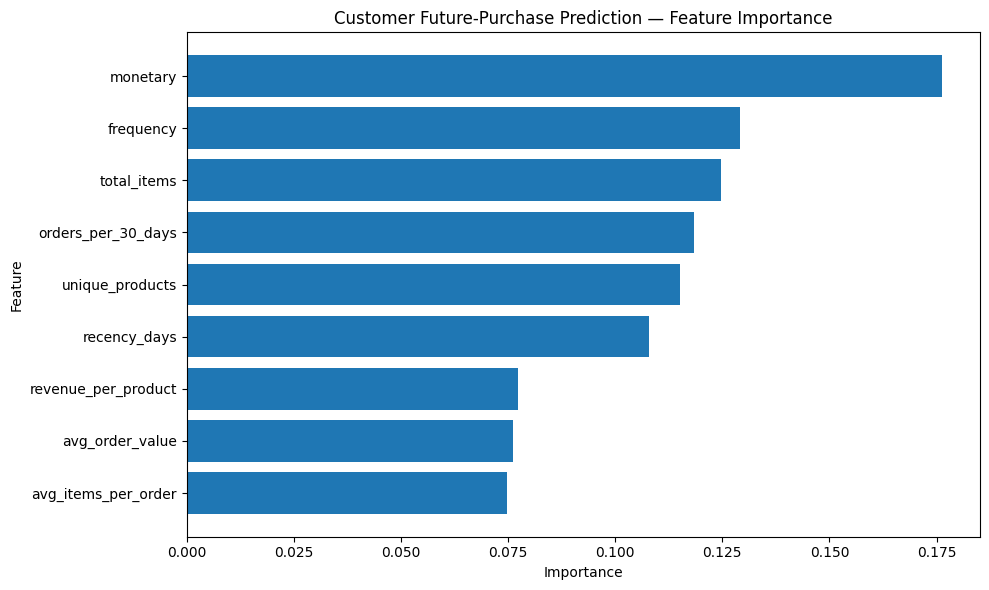


RANDOM FOREST CONFUSION MATRIX
[[237 108]
 [177 309]]


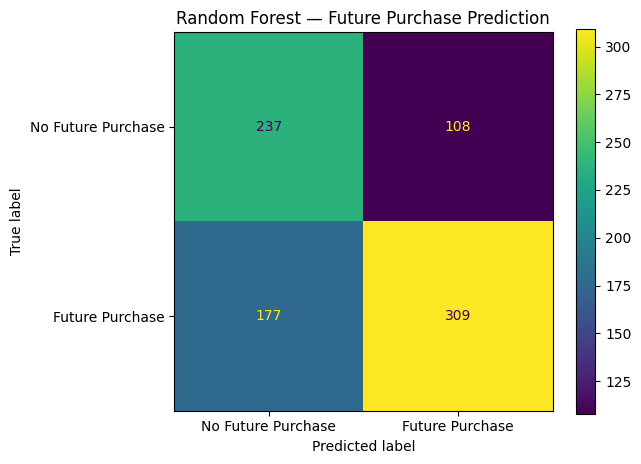


RANDOM FOREST CLASSIFICATION REPORT
                    precision    recall  f1-score   support

No Future Purchase       0.57      0.69      0.62       345
   Future Purchase       0.74      0.64      0.68       486

          accuracy                           0.66       831
         macro avg       0.66      0.66      0.65       831
      weighted avg       0.67      0.66      0.66       831


RETENTION GROUP SUMMARY


,retention_group,customers,avg_retention_probability,avg_recency,avg_frequency,avg_monetary,avg_order_value,avg_unique_products,customer_share_pct
0,High Predicted Retention,713,0.87,30.34,9.63,5113.94,462.15,121.47,21.47
1,Low Predicted Retention,1458,0.36,122.64,1.43,437.96,305.34,22.22,43.90
2,Moderate Predicted Retention,922,0.64,70.58,3.05,1211.33,430.51,58.48,27.76
3,Very Low Predicted Retention,228,0.19,151.68,1.16,251.56,229.19,11.19,6.87



HIGH-VALUE / LOWER-PREDICTED-RETENTION CUSTOMERS


,Customer ID,recency_days,frequency,monetary,unique_products,avg_order_value,retention_probability,retention_group
834,13902,167,5,34095.260,58,6819.052,0.403,Low Predicted Retention
1892,15760,165,2,13916.340,1,6958.170,0.267,Low Predicted Retention
278,12918,161,1,10953.500,1,10953.500,0.152,Very Low Predicted Retention
3188,18052,99,1,10877.180,16,10877.180,0.258,Low Predicted Retention
938,14091,189,2,9530.080,13,4765.040,0.462,Low Predicted Retention
922,14063,221,7,9471.500,29,1353.071,0.479,Low Predicted Retention
979,14160,145,7,8421.470,80,1203.067,0.457,Low Predicted Retention
1703,15413,226,5,6798.720,20,1359.744,0.492,Low Predicted Retention
2097,16118,187,1,4376.250,41,4376.250,0.251,Low Predicted Retention
184,12737,33,2,3710.500,2,1855.250,0.238,Very Low Predicted Retention



PHASE 7 COMPLETE
Saved:
/content/customer_retention_predictions.csv
/content/customer_model_comparison.csv
/content/customer_feature_importance.csv
/content/customer_retention_summary.csv
/content/high_priority_retention_customers.csv


In [ ]:
# ============================================================
# PHASE 8 — PREDICTIVE CUSTOMER ANALYTICS
# Future Purchase / Retention Prediction
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. LOAD TRANSACTION DATA
# ------------------------------------------------------------

# Use the cleaned transaction dataset already created earlier.
# If it exists in memory, use it directly.
# Otherwise load the saved CSV.

try:
    model_transactions = customer_transactions.copy()
    print("Using customer_transactions from memory.")
except NameError:
    model_transactions = pd.read_csv(
        "/content/online_retail_clean.csv",
        parse_dates=["InvoiceDate"]
    )
    print("Loaded online_retail_clean.csv.")

print("\nTransaction data shape:", model_transactions.shape)
print(
    "Date range:",
    model_transactions["InvoiceDate"].min(),
    "to",
    model_transactions["InvoiceDate"].max()
)

# ------------------------------------------------------------
# 2. DEFINE MODELING WINDOWS
# ------------------------------------------------------------
#
# We will use:
#
# Observation window:
#     First 9 months of the available period
#
# Prediction window:
#     Following 3 months
#
# Customers are represented using ONLY information available
# during the observation window.
#
# The target asks:
#     Did this customer make another purchase during the
#     following 3-month prediction window?
#
# This prevents future information from leaking into the model.

data_start = model_transactions["InvoiceDate"].min()
data_end = model_transactions["InvoiceDate"].max()

print("\nData start:", data_start)
print("Data end:", data_end)

# Use a calendar-based cutoff approximately 9 months after
# the beginning of the dataset.
observation_end = data_start + pd.DateOffset(months=9)

prediction_end = observation_end + pd.DateOffset(months=3)

# Do not go beyond the actual dataset.
prediction_end = min(
    prediction_end,
    data_end + pd.Timedelta(days=1)
)

print("\nObservation period:")
print(data_start, "to", observation_end)

print("\nPrediction period:")
print(observation_end, "to", prediction_end)

# ------------------------------------------------------------
# 3. CREATE OBSERVATION DATA
# ------------------------------------------------------------

observation_data = model_transactions[
    model_transactions["InvoiceDate"] < observation_end
].copy()

future_data = model_transactions[
    (model_transactions["InvoiceDate"] >= observation_end)
    & (model_transactions["InvoiceDate"] < prediction_end)
].copy()

print("\nObservation transactions:", len(observation_data))
print("Future transactions:", len(future_data))

print(
    "\nObservation date range:",
    observation_data["InvoiceDate"].min(),
    "to",
    observation_data["InvoiceDate"].max()
)

print(
    "Future date range:",
    future_data["InvoiceDate"].min(),
    "to",
    future_data["InvoiceDate"].max()
)

# ------------------------------------------------------------
# 4. CREATE CUSTOMER-LEVEL FEATURES
# ------------------------------------------------------------

feature_reference_date = observation_end

customer_features = (
    observation_data
    .groupby("Customer ID")
    .agg(
        recency_days=(
            "InvoiceDate",
            lambda x: (feature_reference_date - x.max()).days
        ),
        frequency=("Invoice", "nunique"),
        monetary=("Revenue", "sum"),
        total_items=("Quantity", "sum"),
        unique_products=("StockCode", "nunique"),
        avg_order_value=("Revenue", "sum")
    )
    .reset_index()
)

# Correct average order value
customer_features["avg_order_value"] = (
    customer_features["monetary"]
    / customer_features["frequency"]
)

# ------------------------------------------------------------
# 5. ADD CUSTOMER PURCHASE BEHAVIOR FEATURES
# ------------------------------------------------------------

# Average quantity per order
customer_features["avg_items_per_order"] = (
    customer_features["total_items"]
    / customer_features["frequency"]
)

# Revenue per product purchased
customer_features["revenue_per_product"] = (
    customer_features["monetary"]
    / customer_features["unique_products"]
)

# Purchase frequency normalized by observation period
observation_days = (
    observation_end - data_start
).days

customer_features["orders_per_30_days"] = (
    customer_features["frequency"]
    / observation_days
    * 30
)

# ------------------------------------------------------------
# 6. ADD COUNTRY INFORMATION
# ------------------------------------------------------------

customer_country = (
    observation_data
    .groupby("Customer ID")["Country"]
    .first()
    .reset_index()
)

customer_country = customer_country.rename(
    columns={"Country": "country"}
)

customer_features = customer_features.merge(
    customer_country,
    on="Customer ID",
    how="left"
)

# ------------------------------------------------------------
# 7. CREATE FUTURE PURCHASE TARGET
# ------------------------------------------------------------
#
# target = 1:
# customer purchases again during prediction period
#
# target = 0:
# customer does not purchase again during prediction period
#
# This is our retention/future-purchase target.

future_customers = set(
    future_data["Customer ID"].unique()
)

customer_features["future_purchase"] = (
    customer_features["Customer ID"]
    .isin(future_customers)
    .astype(int)
)

print("\nTarget distribution:")
print(
    customer_features["future_purchase"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentage:")
print(
    customer_features["future_purchase"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# ------------------------------------------------------------
# 8. REMOVE COUNTRY FOR THE FIRST MODEL
# ------------------------------------------------------------
#
# Country is categorical and would require one-hot encoding.
# We will keep the clean baseline focused on behavioral
# variables.
#
# We can revisit geographic features later if useful.

feature_columns = [
    "recency_days",
    "frequency",
    "monetary",
    "total_items",
    "unique_products",
    "avg_order_value",
    "avg_items_per_order",
    "revenue_per_product",
    "orders_per_30_days"
]

X = customer_features[feature_columns].copy()
y = customer_features["future_purchase"].copy()

print("\nModel feature shape:", X.shape)
print("Target shape:", y.shape)

# ------------------------------------------------------------
# 9. CHECK FOR MISSING / INFINITE VALUES
# ------------------------------------------------------------

X = X.replace([np.inf, -np.inf], np.nan)

print("\nMissing values:")
print(X.isna().sum())

# Remove any problematic rows
valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

customer_features_model = customer_features.loc[
    valid_rows
].copy()

print("\nFinal modeling dataset:", X.shape)

# ------------------------------------------------------------
# 10. TRAIN / TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# ------------------------------------------------------------
# 11. LOGISTIC REGRESSION BASELINE
# ------------------------------------------------------------

logistic_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

print("\n============================================================")
print("LOGISTIC REGRESSION RESULTS")
print("============================================================")

print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_auc, 4))

# ------------------------------------------------------------
# 12. RANDOM FOREST MODEL
# ------------------------------------------------------------

random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)
rf_prob = random_forest.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("\n============================================================")
print("RANDOM FOREST RESULTS")
print("============================================================")

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

# ------------------------------------------------------------
# 13. MODEL COMPARISON
# ------------------------------------------------------------

model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "precision": [
        logistic_precision,
        rf_precision
    ],
    "recall": [
        logistic_recall,
        rf_recall
    ],
    "f1_score": [
        logistic_f1,
        rf_f1
    ],
    "roc_auc": [
        logistic_auc,
        rf_auc
    ]
})

print("\n============================================================")
print("MODEL COMPARISON")
print("============================================================")

display(
    model_comparison.round(4)
)

# ------------------------------------------------------------
# 14. RANDOM FOREST FEATURE IMPORTANCE
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": random_forest.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("\n============================================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("============================================================")

display(
    feature_importance.round(4)
)

# ------------------------------------------------------------
# 15. PLOT FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title(
    "Customer Future-Purchase Prediction — Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. CONFUSION MATRIX — RANDOM FOREST
# ------------------------------------------------------------

print("\n============================================================")
print("RANDOM FOREST CONFUSION MATRIX")
print("============================================================")

cm = confusion_matrix(
    y_test,
    rf_pred
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Future Purchase",
        "Future Purchase"
    ]
).plot()

plt.title(
    "Random Forest — Future Purchase Prediction"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n============================================================")
print("RANDOM FOREST CLASSIFICATION REPORT")
print("============================================================")

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "No Future Purchase",
            "Future Purchase"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 18. CREATE CUSTOMER RETENTION SCORES
# ------------------------------------------------------------
#
# Use the trained Random Forest to estimate the probability
# that each modeled customer makes another purchase.
#
# This creates a business-facing customer prioritization table.

customer_features_model["retention_probability"] = (
    random_forest.predict_proba(
        customer_features_model[feature_columns]
    )[:, 1]
)

customer_features_model["retention_prediction"] = (
    random_forest.predict(
        customer_features_model[feature_columns]
    )
)

# ------------------------------------------------------------
# 19. CREATE BUSINESS-FRIENDLY RETENTION GROUPS
# ------------------------------------------------------------

def retention_group(probability):

    if probability >= 0.75:
        return "High Predicted Retention"

    elif probability >= 0.50:
        return "Moderate Predicted Retention"

    elif probability >= 0.25:
        return "Low Predicted Retention"

    else:
        return "Very Low Predicted Retention"


customer_features_model["retention_group"] = (
    customer_features_model["retention_probability"]
    .apply(retention_group)
)

# ------------------------------------------------------------
# 20. RETENTION GROUP SUMMARY
# ------------------------------------------------------------

retention_summary = (
    customer_features_model
    .groupby("retention_group")
    .agg(
        customers=("Customer ID", "count"),
        avg_retention_probability=(
            "retention_probability",
            "mean"
        ),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        avg_order_value=("avg_order_value", "mean"),
        avg_unique_products=("unique_products", "mean")
    )
    .reset_index()
)

retention_summary["customer_share_pct"] = (
    retention_summary["customers"]
    / retention_summary["customers"].sum()
    * 100
)

print("\n============================================================")
print("RETENTION GROUP SUMMARY")
print("============================================================")

display(
    retention_summary.round(2)
)

# ------------------------------------------------------------
# 21. HIGH-PRIORITY CUSTOMERS
# ------------------------------------------------------------
#
# Customers with relatively low predicted future-purchase
# probability but meaningful historical monetary value.
#
# This is useful for potential retention campaigns.
#
# IMPORTANT:
# This is an analytical prioritization, not a causal claim.

priority_customers = customer_features_model[
    (customer_features_model["retention_probability"] < 0.50)
    & (customer_features_model["monetary"] > customer_features_model["monetary"].median())
].copy()

priority_customers = priority_customers.sort_values(
    ["monetary", "retention_probability"],
    ascending=[False, True]
)

print("\n============================================================")
print("HIGH-VALUE / LOWER-PREDICTED-RETENTION CUSTOMERS")
print("============================================================")

display(
    priority_customers[
        [
            "Customer ID",
            "recency_days",
            "frequency",
            "monetary",
            "unique_products",
            "avg_order_value",
            "retention_probability",
            "retention_group"
        ]
    ].head(20).round(3)
)

# ------------------------------------------------------------
# 22. SAVE PHASE 8 OUTPUTS
# ------------------------------------------------------------

customer_features_model.to_csv(
    "/content/customer_retention_predictions.csv",
    index=False
)

model_comparison.to_csv(
    "/content/customer_model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "/content/customer_feature_importance.csv",
    index=False
)

retention_summary.to_csv(
    "/content/customer_retention_summary.csv",
    index=False
)

priority_customers.to_csv(
    "/content/high_priority_retention_customers.csv",
    index=False
)

print("\n============================================================")
print("PHASE 8 COMPLETE")
print("============================================================")

print("Saved:")
print("/content/customer_retention_predictions.csv")
print("/content/customer_model_comparison.csv")
print("/content/customer_feature_importance.csv")
print("/content/customer_retention_summary.csv")
print("/content/high_priority_retention_customers.csv")


## Phase 9 — Future Customer Revenue Modeling

Estimate future three-month customer revenue from historical purchasing behavior.

Baseline and machine-learning regression approaches are compared using RMSE and R². Predicted future value is used as a prioritization signal rather than a guarantee of future customer behavior.


PHASE 8 — CUSTOMER FUTURE REVENUE MODEL

Using Phase 7 datasets from memory.

Observation data: (244976, 10)
Future data: (141756, 10)

Observation period: 2009-12-01 07:45:00 to 2010-08-31 17:39:00
Future period: 2010-09-01 09:25:00 to 2010-11-30 19:35:00

FUTURE REVENUE DISTRIBUTION
count     3321.000000
mean       729.530299
std       2923.265910
min          0.000000
25%          0.000000
50%        206.150000
75%        682.670000
max      92219.610000
Name: future_revenue, dtype: float64

Customers with $0 future revenue: 1379
Customers with future revenue: 1942

Percentage with future revenue: 58.48 %

MODEL DATASET
Features: (3321, 12)
Target: (3321,)

Training customers: 2490
Testing customers: 831

BASELINE RESULTS
MAE : 934.61
RMSE: 4133.86
R²  : -0.0013

LINEAR REGRESSION RESULTS
MAE : 669.55
RMSE: 2839.32
R²  : 0.5276

RANDOM FOREST REGRESSION RESULTS
MAE : 663.09
RMSE: 2983.35
R²  : 0.4785

GRADIENT BOOSTING RESULTS
MAE : 636.54
RMSE: 3097.77
R²  : 0.4377

FUTURE REVENUE 

,model,MAE,RMSE,R2
0,Mean Baseline,934.611,4133.865,-0.001
1,Linear Regression,669.553,2839.318,0.528
2,Random Forest,663.092,2983.352,0.478
3,Gradient Boosting,636.540,3097.768,0.438



Best model based on RMSE:
Linear Regression

FUTURE REVENUE FEATURE IMPORTANCE


,feature,importance
9,revenue_per_30_days,693.8201
2,monetary,693.8201
1,frequency,491.9652
8,orders_per_30_days,491.9652
3,total_items,283.8177
5,avg_order_value,116.5911
4,unique_products,109.0574
7,revenue_per_product,77.1471
10,products_per_order,74.8258
11,items_per_product,64.1796


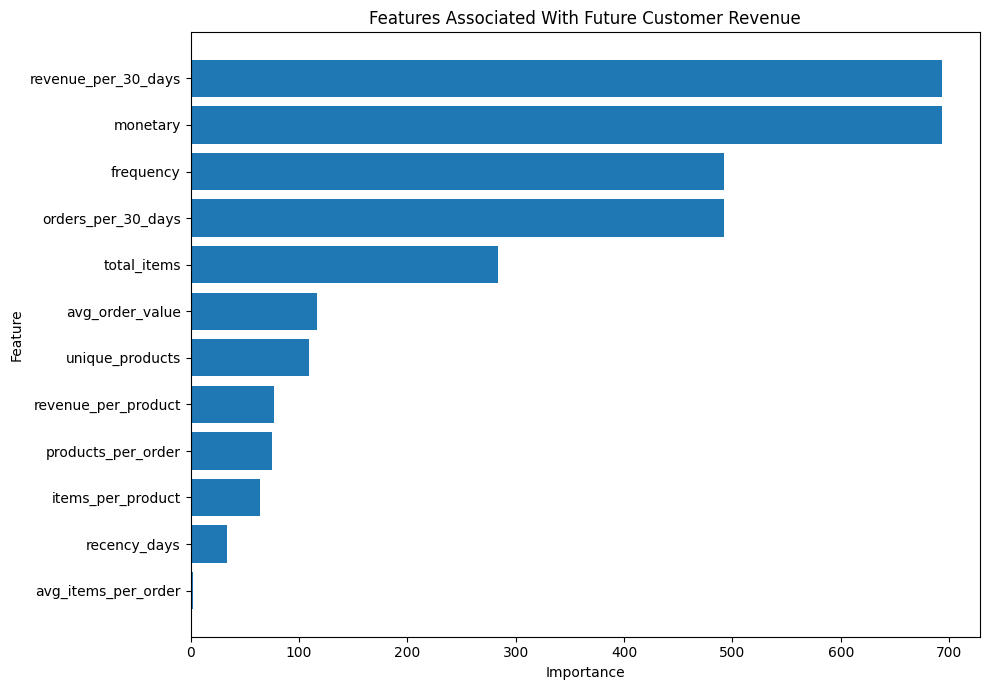


CUSTOMER VALUE TIER SUMMARY


,value_tier,customers,avg_predicted_future_revenue,total_predicted_future_revenue,avg_historical_revenue,avg_recency,avg_frequency,avg_order_value,avg_unique_products,customer_share_pct,predicted_revenue_share_pct
0,High Predicted Value,831,2094.28,1740344.99,4985.89,41.26,8.96,604.39,115.26,25.02,74.14
1,Low Predicted Value,830,41.62,34544.14,235.47,119.05,1.05,188.32,12.07,24.99,1.47
2,Medium-High Predicted Value,830,483.21,401060.37,944.76,78.82,2.89,391.88,54.09,24.99,17.09
3,Medium-Low Predicted Value,830,206.43,171337.49,404.97,122.39,1.59,289.24,29.85,24.99,7.30



HIGH-VALUE FUTURE REVENUE OPPORTUNITIES


,Customer ID,recency_days,frequency,monetary,unique_products,avg_order_value,predicted_future_revenue,value_tier
3218,18102,0,78,269041.67,268,3449.25,62233.78,High Predicted Value
976,14156,8,68,154300.85,815,2269.13,37257.30,High Predicted Value
1264,14646,11,44,156176.89,384,3549.47,33962.96,High Predicted Value
1423,14911,0,117,82707.94,1274,706.91,32074.72,High Predicted Value
710,13694,19,83,109340.51,594,1317.36,29737.29,High Predicted Value
1652,15311,4,85,44134.71,504,519.23,20600.63,High Predicted Value
3078,17850,43,81,36066.05,77,445.26,19414.57,High Predicted Value
380,13089,0,75,34382.87,404,458.44,17428.26,High Predicted Value
3132,17949,6,58,42465.36,31,732.16,16721.02,High Predicted Value
1508,15061,13,50,48940.59,104,978.81,16353.95,High Predicted Value



HIGH HISTORICAL VALUE / LOWER PREDICTED FUTURE VALUE


,Customer ID,recency_days,frequency,monetary,unique_products,avg_order_value,predicted_future_revenue,value_tier
834,13902,167,5,34095.26,58,6819.05,0.0,Low Predicted Value
1047,14277,22,4,12620.23,74,3155.06,0.0,Low Predicted Value


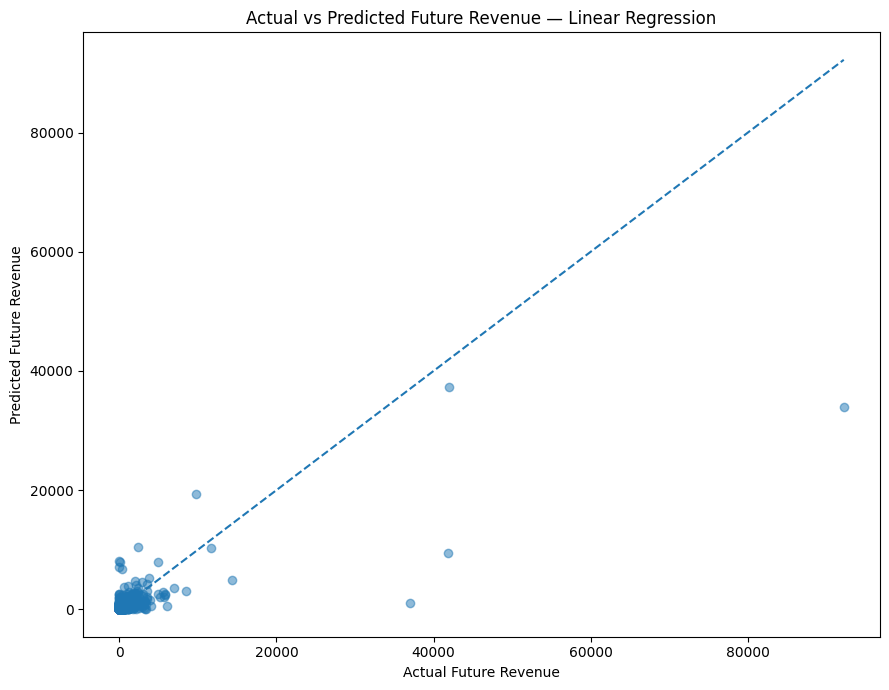


PHASE 8 COMPLETE

Files saved:
/content/customer_future_value_predictions.csv
/content/customer_value_model_comparison.csv
/content/customer_value_feature_importance.csv
/content/customer_value_tier_summary.csv
/content/high_value_future_value_customers.csv
/content/high_historical_value_lower_future_value.csv
/content/future_revenue_test_predictions.csv

Best future-revenue model: Linear Regression
Best RMSE: 2839.32


In [ ]:
# ============================================================
# PHASE 9 — CUSTOMER LIFETIME VALUE / FUTURE REVENUE MODEL
# Predicting Future 3-Month Customer Revenue
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. VERIFY PHASE 8 DATA EXISTS
# ============================================================

print("============================================================")
print("PHASE 9 — CUSTOMER FUTURE REVENUE MODEL")
print("============================================================")

# Phase 8 created these datasets.
# If they already exist in memory, reuse them.

try:
    observation_data
    future_data
    customer_features
    print("\nUsing Phase 8 datasets from memory.")

except NameError:

    print("\nPhase 8 variables not found. Loading data...")

    try:
        model_transactions = customer_transactions.copy()
    except NameError:
        model_transactions = pd.read_csv(
            "/content/online_retail_clean.csv",
            parse_dates=["InvoiceDate"]
        )

    data_start = model_transactions["InvoiceDate"].min()
    data_end = model_transactions["InvoiceDate"].max()

    observation_end = data_start + pd.DateOffset(months=9)
    prediction_end = min(
        observation_end + pd.DateOffset(months=3),
        data_end + pd.Timedelta(days=1)
    )

    observation_data = model_transactions[
        model_transactions["InvoiceDate"] < observation_end
    ].copy()

    future_data = model_transactions[
        (model_transactions["InvoiceDate"] >= observation_end)
        & (model_transactions["InvoiceDate"] < prediction_end)
    ].copy()

    feature_reference_date = observation_end

    customer_features = (
        observation_data
        .groupby("Customer ID")
        .agg(
            recency_days=(
                "InvoiceDate",
                lambda x: (feature_reference_date - x.max()).days
            ),
            frequency=("Invoice", "nunique"),
            monetary=("Revenue", "sum"),
            total_items=("Quantity", "sum"),
            unique_products=("StockCode", "nunique")
        )
        .reset_index()
    )

    customer_features["avg_order_value"] = (
        customer_features["monetary"]
        / customer_features["frequency"]
    )

    customer_features["avg_items_per_order"] = (
        customer_features["total_items"]
        / customer_features["frequency"]
    )

    customer_features["revenue_per_product"] = (
        customer_features["monetary"]
        / customer_features["unique_products"]
    )

    observation_days = (
        observation_end - data_start
    ).days

    customer_features["orders_per_30_days"] = (
        customer_features["frequency"]
        / observation_days
        * 30
    )


print("\nObservation data:", observation_data.shape)
print("Future data:", future_data.shape)

print(
    "\nObservation period:",
    observation_data["InvoiceDate"].min(),
    "to",
    observation_data["InvoiceDate"].max()
)

print(
    "Future period:",
    future_data["InvoiceDate"].min(),
    "to",
    future_data["InvoiceDate"].max()
)

# ============================================================
# 2. CREATE FUTURE CUSTOMER REVENUE TARGET
# ============================================================
#
# For every customer in the observation period, calculate
# revenue generated during the following 3-month period.
#
# Customers who did not purchase again receive future revenue
# of $0.
#
# This gives us a genuine future-value prediction problem.

future_revenue = (
    future_data
    .groupby("Customer ID")
    .agg(
        future_revenue=("Revenue", "sum"),
        future_orders=("Invoice", "nunique"),
        future_items=("Quantity", "sum"),
        future_unique_products=("StockCode", "nunique")
    )
    .reset_index()
)

customer_value = customer_features.merge(
    future_revenue,
    on="Customer ID",
    how="left"
)

# Customers without a future purchase
# should have zero future revenue.
for column in [
    "future_revenue",
    "future_orders",
    "future_items",
    "future_unique_products"
]:
    customer_value[column] = (
        customer_value[column]
        .fillna(0)
    )

# ============================================================
# 3. INSPECT FUTURE REVENUE DISTRIBUTION
# ============================================================

print("\n============================================================")
print("FUTURE REVENUE DISTRIBUTION")
print("============================================================")

print(
    customer_value["future_revenue"].describe()
)

zero_future = (
    customer_value["future_revenue"] == 0
).sum()

positive_future = (
    customer_value["future_revenue"] > 0
).sum()

print("\nCustomers with $0 future revenue:", zero_future)
print("Customers with future revenue:", positive_future)

print(
    "\nPercentage with future revenue:",
    round(
        positive_future
        / len(customer_value)
        * 100,
        2
    ),
    "%"
)

# ============================================================
# 4. ADD VALUE-ORIENTED FEATURES
# ============================================================

# Historical revenue per day of observation
observation_days = (
    observation_end - data_start
).days

customer_value["revenue_per_30_days"] = (
    customer_value["monetary"]
    / observation_days
    * 30
)

# Order frequency normalized to 30 days
customer_value["orders_per_30_days"] = (
    customer_value["frequency"]
    / observation_days
    * 30
)

# Product breadth relative to number of orders
customer_value["products_per_order"] = (
    customer_value["unique_products"]
    / customer_value["frequency"]
)

# Items per product
customer_value["items_per_product"] = (
    customer_value["total_items"]
    / customer_value["unique_products"]
)

# ============================================================
# 5. SELECT MODEL FEATURES
# ============================================================

value_features = [
    "recency_days",
    "frequency",
    "monetary",
    "total_items",
    "unique_products",
    "avg_order_value",
    "avg_items_per_order",
    "revenue_per_product",
    "orders_per_30_days",
    "revenue_per_30_days",
    "products_per_order",
    "items_per_product"
]

X = customer_value[value_features].copy()

# Future revenue is our target
y = customer_value["future_revenue"].copy()

# Remove infinite values
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove missing rows
valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

customer_value_model = (
    customer_value
    .loc[valid_rows]
    .copy()
)

print("\n============================================================")
print("MODEL DATASET")
print("============================================================")

print("Features:", X.shape)
print("Target:", y.shape)

# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("\nTraining customers:", len(X_train))
print("Testing customers:", len(X_test))

# ============================================================
# 7. BASELINE — PREDICT MEAN FUTURE REVENUE
# ============================================================

baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("\n============================================================")
print("BASELINE RESULTS")
print("============================================================")

print("MAE :", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²  :", round(baseline_r2, 4))

# ============================================================
# 8. LINEAR REGRESSION
# ============================================================

linear_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]
)

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

linear_pred = np.maximum(
    linear_pred,
    0
)

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_pred
    )
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

print("\n============================================================")
print("LINEAR REGRESSION RESULTS")
print("============================================================")

print("MAE :", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²  :", round(linear_r2, 4))

# ============================================================
# 9. RANDOM FOREST REGRESSOR
# ============================================================

random_forest_reg = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

random_forest_reg.fit(
    X_train,
    y_train
)

rf_pred = random_forest_reg.predict(
    X_test
)

rf_pred = np.maximum(
    rf_pred,
    0
)

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("\n============================================================")
print("RANDOM FOREST REGRESSION RESULTS")
print("============================================================")

print("MAE :", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²  :", round(rf_r2, 4))

# ============================================================
# 10. GRADIENT BOOSTING REGRESSOR
# ============================================================

gradient_boosting = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42,
    loss="huber"
)

gradient_boosting.fit(
    X_train,
    y_train
)

gb_pred = gradient_boosting.predict(
    X_test
)

gb_pred = np.maximum(
    gb_pred,
    0
)

gb_mae = mean_absolute_error(
    y_test,
    gb_pred
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gb_pred
    )
)

gb_r2 = r2_score(
    y_test,
    gb_pred
)

print("\n============================================================")
print("GRADIENT BOOSTING RESULTS")
print("============================================================")

print("MAE :", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("R²  :", round(gb_r2, 4))

# ============================================================
# 11. MODEL COMPARISON
# ============================================================

value_model_comparison = pd.DataFrame({
    "model": [
        "Mean Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

print("\n============================================================")
print("FUTURE REVENUE MODEL COMPARISON")
print("============================================================")

display(
    value_model_comparison.round(3)
)

# ============================================================
# 12. SELECT BEST MODEL BASED ON RMSE
# ============================================================

model_predictions = {
    "Linear Regression": linear_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

rmse_values = {
    "Linear Regression": linear_rmse,
    "Random Forest": rf_rmse,
    "Gradient Boosting": gb_rmse
}

best_model_name = min(
    rmse_values,
    key=rmse_values.get
)

print("\nBest model based on RMSE:")
print(best_model_name)

# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

if best_model_name == "Random Forest":

    value_feature_importance = pd.DataFrame({
        "feature": value_features,
        "importance": random_forest_reg.feature_importances_
    })

elif best_model_name == "Gradient Boosting":

    value_feature_importance = pd.DataFrame({
        "feature": value_features,
        "importance": gradient_boosting.feature_importances_
    })

else:

    # Linear regression coefficients
    linear_coefficients = (
        linear_model
        .named_steps["model"]
        .coef_
    )

    value_feature_importance = pd.DataFrame({
        "feature": value_features,
        "importance": np.abs(linear_coefficients)
    })

value_feature_importance = (
    value_feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

print("\n============================================================")
print("FUTURE REVENUE FEATURE IMPORTANCE")
print("============================================================")

display(
    value_feature_importance.round(4)
)

# ============================================================
# 14. FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(10, 7))

plt.barh(
    value_feature_importance["feature"],
    value_feature_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title(
    "Features Associated With Future Customer Revenue"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()
plt.show()

# ============================================================
# 15. GENERATE PREDICTED FUTURE REVENUE FOR ALL CUSTOMERS
# ============================================================

if best_model_name == "Linear Regression":

    all_predictions = linear_model.predict(
        customer_value_model[value_features]
    )

elif best_model_name == "Random Forest":

    all_predictions = random_forest_reg.predict(
        customer_value_model[value_features]
    )

else:

    all_predictions = gradient_boosting.predict(
        customer_value_model[value_features]
    )

all_predictions = np.maximum(
    all_predictions,
    0
)

customer_value_model["predicted_future_revenue"] = (
    all_predictions
)

# ============================================================
# 16. CREATE CUSTOMER VALUE TIERS
# ============================================================

# Use predicted future revenue quartiles.
#
# This creates business-friendly groups rather than claiming
# that a particular dollar amount is universally "high value."

q25 = customer_value_model[
    "predicted_future_revenue"
].quantile(0.25)

q50 = customer_value_model[
    "predicted_future_revenue"
].quantile(0.50)

q75 = customer_value_model[
    "predicted_future_revenue"
].quantile(0.75)


def value_tier(value):

    if value >= q75:
        return "High Predicted Value"

    elif value >= q50:
        return "Medium-High Predicted Value"

    elif value >= q25:
        return "Medium-Low Predicted Value"

    else:
        return "Low Predicted Value"


customer_value_model["value_tier"] = (
    customer_value_model[
        "predicted_future_revenue"
    ]
    .apply(value_tier)
)

# ============================================================
# 17. VALUE TIER SUMMARY
# ============================================================

value_tier_summary = (
    customer_value_model
    .groupby("value_tier")
    .agg(
        customers=("Customer ID", "count"),
        avg_predicted_future_revenue=(
            "predicted_future_revenue",
            "mean"
        ),
        total_predicted_future_revenue=(
            "predicted_future_revenue",
            "sum"
        ),
        avg_historical_revenue=(
            "monetary",
            "mean"
        ),
        avg_recency=(
            "recency_days",
            "mean"
        ),
        avg_frequency=(
            "frequency",
            "mean"
        ),
        avg_order_value=(
            "avg_order_value",
            "mean"
        ),
        avg_unique_products=(
            "unique_products",
            "mean"
        )
    )
    .reset_index()
)

value_tier_summary["customer_share_pct"] = (
    value_tier_summary["customers"]
    / value_tier_summary["customers"].sum()
    * 100
)

value_tier_summary["predicted_revenue_share_pct"] = (
    value_tier_summary[
        "total_predicted_future_revenue"
    ]
    / value_tier_summary[
        "total_predicted_future_revenue"
    ].sum()
    * 100
)

print("\n============================================================")
print("CUSTOMER VALUE TIER SUMMARY")
print("============================================================")

display(
    value_tier_summary.round(2)
)

# ============================================================
# 18. HIGH-VALUE OPPORTUNITY CUSTOMERS
# ============================================================
#
# These are customers with:
#
# 1. meaningful historical revenue
# 2. relatively strong predicted future value
#
# They can later be used in a dashboard as an example of
# customer-level targeting.

historical_median = (
    customer_value_model["monetary"].median()
)

predicted_median = (
    customer_value_model[
        "predicted_future_revenue"
    ].median()
)

high_value_opportunities = customer_value_model[
    (
        customer_value_model["monetary"]
        >= historical_median
    )
    &
    (
        customer_value_model[
            "predicted_future_revenue"
        ]
        >= predicted_median
    )
].copy()

high_value_opportunities = (
    high_value_opportunities
    .sort_values(
        "predicted_future_revenue",
        ascending=False
    )
)

print("\n============================================================")
print("HIGH-VALUE FUTURE REVENUE OPPORTUNITIES")
print("============================================================")

display(
    high_value_opportunities[
        [
            "Customer ID",
            "recency_days",
            "frequency",
            "monetary",
            "unique_products",
            "avg_order_value",
            "predicted_future_revenue",
            "value_tier"
        ]
    ]
    .head(20)
    .round(2)
)

# ============================================================
# 19. CUSTOMERS WITH HIGH HISTORICAL VALUE BUT LOWER
#     PREDICTED FUTURE VALUE
# ============================================================
#
# This is particularly useful from a customer analytics
# perspective.
#
# These customers have generated substantial historical
# revenue but are not predicted to generate as much in the
# future.
#
# This does NOT prove that they are going to churn.
# It identifies customers for further investigation.

historical_high_value = (
    customer_value_model["monetary"]
    >= customer_value_model["monetary"].quantile(0.75)
)

predicted_lower_value = (
    customer_value_model[
        "predicted_future_revenue"
    ]
    <= customer_value_model[
        "predicted_future_revenue"
    ].median()
)

retention_opportunities = customer_value_model[
    historical_high_value
    & predicted_lower_value
].copy()

retention_opportunities = (
    retention_opportunities
    .sort_values(
        "monetary",
        ascending=False
    )
)

print("\n============================================================")
print("HIGH HISTORICAL VALUE / LOWER PREDICTED FUTURE VALUE")
print("============================================================")

display(
    retention_opportunities[
        [
            "Customer ID",
            "recency_days",
            "frequency",
            "monetary",
            "unique_products",
            "avg_order_value",
            "predicted_future_revenue",
            "value_tier"
        ]
    ]
    .head(20)
    .round(2)
)

# ============================================================
# 20. ACTUAL VS PREDICTED REVENUE
# ============================================================

# Use the test set to visualize model performance.

test_results = pd.DataFrame({
    "actual_future_revenue": y_test.values,
    "predicted_future_revenue": model_predictions[
        best_model_name
    ]
})

plt.figure(figsize=(9, 7))

plt.scatter(
    test_results["actual_future_revenue"],
    test_results["predicted_future_revenue"],
    alpha=0.5
)

max_value = max(
    test_results["actual_future_revenue"].max(),
    test_results["predicted_future_revenue"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted Future Revenue — {best_model_name}"
)

plt.xlabel(
    "Actual Future Revenue"
)

plt.ylabel(
    "Predicted Future Revenue"
)

plt.tight_layout()
plt.show()

# ============================================================
# 21. SAVE ALL PHASE 9 OUTPUTS
# ============================================================

customer_value_model.to_csv(
    "/content/customer_future_value_predictions.csv",
    index=False
)

value_model_comparison.to_csv(
    "/content/customer_value_model_comparison.csv",
    index=False
)

value_feature_importance.to_csv(
    "/content/customer_value_feature_importance.csv",
    index=False
)

value_tier_summary.to_csv(
    "/content/customer_value_tier_summary.csv",
    index=False
)

high_value_opportunities.to_csv(
    "/content/high_value_future_value_customers.csv",
    index=False
)

retention_opportunities.to_csv(
    "/content/high_historical_value_lower_future_value.csv",
    index=False
)

test_results.to_csv(
    "/content/future_revenue_test_predictions.csv",
    index=False
)

print("\n============================================================")
print("PHASE 9 COMPLETE")
print("============================================================")

print("\nFiles saved:")

print(
    "/content/customer_future_value_predictions.csv"
)

print(
    "/content/customer_value_model_comparison.csv"
)

print(
    "/content/customer_value_feature_importance.csv"
)

print(
    "/content/customer_value_tier_summary.csv"
)

print(
    "/content/high_value_future_value_customers.csv"
)

print(
    "/content/high_historical_value_lower_future_value.csv"
)

print(
    "/content/future_revenue_test_predictions.csv"
)

print("\nBest future-revenue model:", best_model_name)
print("Best RMSE:", round(rmse_values[best_model_name], 2))


## Phase 10 — Product × Customer & Market-Basket Analysis

Connect customer value with product behavior and examine product co-purchase relationships.

The analysis explores high-value customer product preferences, product roles, and cross-sell candidates. Association metrics indicate co-occurrence rather than causal product influence, and rare product pairs should not be treated as production-ready recommendations without sufficient support.


PHASE 9 — PRODUCT × CUSTOMER RELATIONSHIP ANALYSIS

Using customer_transactions from memory.
Transaction shape: (400916, 10)
Product transaction shape: (399758, 10)

Unique products: 4015

High-value customer revenue threshold: 1698.03

Customer value groups:
value_group
Other Customer         3222
High-Value Customer    1074
Name: count, dtype: int64

PRODUCT PERFORMANCE


,StockCode,total_revenue,total_quantity,total_orders,unique_customers,avg_price,Description,customer_penetration_pct,revenue_per_customer
3624,85123A,151339.16,56814,3021,1141,2.85,WHITE HANGING HEART T-LIGHT HOLDER,26.56,132.64
1489,22423,143727.60,12484,1687,818,12.44,REGENCY CAKESTAND 3 TIER,19.04,175.71
3615,85099B,85257.45,48731,1708,692,1.91,JUMBO BAG RED RETROSPOT,16.11,123.20
2478,84879,70291.03,44431,1333,627,1.67,ASSORTED COLOUR BIRD ORNAMENT,14.59,112.11
1008,21843,41457.64,4056,895,467,10.87,RED RETROSPOT CAKE STAND,10.87,88.77
2176,48138,41223.56,6342,1016,528,7.22,DOOR MAT UNION FLAG,12.29,78.07
2325,84347,40156.05,21579,244,177,2.51,ROTATING SILVER ANGELS T-LIGHT HLDR,4.12,226.87
1179,22086,36871.55,13839,796,505,2.90,PAPER CHAIN KIT 50'S CHRISTMAS,11.76,73.01
100,20685,36417.04,5642,934,472,7.21,DOOR MAT RED SPOT,10.99,77.15
2163,47566,35017.30,8312,710,391,4.57,PARTY BUNTING,9.10,89.56



PRODUCT REVENUE — REPEAT CUSTOMER SHARE


customer_type,StockCode,Description,One-Time Customer,Repeat Customer,total_revenue,repeat_revenue_share_pct
3624,85123A,WHITE HANGING HEART T-LIGHT HOLDER,3938.10,147401.06,151339.16,97.40
1489,22423,REGENCY CAKESTAND 3 TIER,6019.05,137708.55,143727.60,95.81
3615,85099B,JUMBO BAG RED RETROSPOT,2227.80,83029.65,85257.45,97.39
2478,84879,ASSORTED COLOUR BIRD ORNAMENT,2158.13,68132.90,70291.03,96.93
1008,21843,RED RETROSPOT CAKE STAND,799.35,40658.29,41457.64,98.07
2176,48138,DOOR MAT UNION FLAG,1937.14,39286.42,41223.56,95.30
2325,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,981.30,39174.75,40156.05,97.56
1179,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2095.50,34776.05,36871.55,94.32
100,20685,DOOR MAT RED SPOT,889.90,35527.14,36417.04,97.56
2163,47566,PARTY BUNTING,1248.00,33769.30,35017.30,96.44



PRODUCTS WITH STRONG REPEAT-CUSTOMER PENETRATION
Minimum 50 customers


...

,product_a,description_a,product_b,description_b,co_purchase_orders,confidence_a_to_b,confidence_b_to_a,lift
9120,21231,NaN,21232,NaN,622,NaN,NaN,NaN
1420,21733,NaN,85123A,WHITE HANGING HEART T-LIGHT HOLDER,536,NaN,0.1774,NaN
69,21754,NaN,21755,NaN,517,NaN,NaN,NaN
19626,21212,NaN,21977,NaN,508,NaN,NaN,NaN
11782,20725,NaN,20727,NaN,506,NaN,NaN,NaN
24946,82482,NaN,82494L,WOODEN FRAME ANTIQUE WHITE,475,NaN,0.4708,NaN
386719,20725,NaN,22384,NaN,468,NaN,NaN,NaN
793121,22469,NaN,22470,NaN,456,NaN,NaN,NaN
1219,20725,NaN,20728,NaN,454,NaN,NaN,NaN
385950,20725,NaN,22383,NaN,437,NaN,NaN,NaN



TOP PRODUCT PAIRS BY LIFT
Minimum 20 co-purchase orders


,product_a,description_a,product_b,description_b,co_purchase_orders,support,confidence_a_to_b,confidence_b_to_a,lift
57610,35810A,ENAMEL PINK COFFEE CONTAINER,35811A,ENAMEL PINK SUGAR CONTAINER,32,0.0017,0.6154,0.6809,249.2831
57601,35809A,ENAMEL PINK TEA CONTAINER,35810A,ENAMEL PINK COFFEE CONTAINER,42,0.0022,0.6000,0.8077,219.6808
57602,35809A,ENAMEL PINK TEA CONTAINER,35811A,ENAMEL PINK SUGAR CONTAINER,36,0.0019,0.5143,0.7660,208.3295
25200,35095A,BLUE VICTORIAN FABRIC OVAL BOX,35095B,RED VICTORIAN FABRIC OVAL BOX,23,0.0012,0.5227,0.4510,195.1413
377745,15058A,BLUE WHITE SPOTS GARDEN PARASOL,15058B,PINK WHITE SPOTS GARDEN PARASOL,26,0.0014,0.4727,0.5200,180.0051
65837,79190B,RETRO PLASTIC POLKA TRAY,79190D,RETRO PLASTIC DAISY TRAY,25,0.0013,0.4032,0.5000,153.5403
65824,79190A,RETRO PLASTIC 70'S TRAY,79190B,RETRO PLASTIC POLKA TRAY,20,0.0011,0.4878,0.3226,149.7954
13884,17165B,ASS COL LARGE SAND GECKO P'WEIGHT,17165D,ASS COL LARGE SAND FROG P'WEIGHT,34,0.0018,0.6071,0.4146,140.9682
138779,85124B,BLUE JUICY FRUIT PHOTO FRAME,85124C,GREEN JUICY FRUIT PHOTO FRAME,30,0.0016,0.5172,0.4225,138.7008
193835,82613B,"METAL SIGN,CUPCAKE SINGLE HOOK",82613D,METAL SIGN CUPCAKE SINGLE HOOK,27,0.0014,0.5400,0.3553,135.2771



TOP PRODUCT AFFINITY OPPORTUNITIES


,product_a,description_a,product_b,description_b,co_purchase_orders,confidence_a_to_b,confidence_b_to_a,lift,affinity_score
279239,72755C,FLOWER FAIRY OIL BURNER SET ROSE,72755D,FLOWER FAIRY OIL BURNER SET SUMMER,10,0.7692,0.7692,1126.5680,2701.3922
39065,17109B,FLOWER FAIRY INCENSE LAVENDER,17109C,FLOWER FAIRY INCENSE ROSE,10,0.6250,0.6667,793.2917,1902.2303
197660,17090A,LAVENDER INCENSE 40 CONES IN TIN,17090D,VANILLA INCENSE 40 CONES IN TIN,12,0.6667,0.6667,705.1481,1808.6693
773527,84875B,GREEN SQUARE COMPACT MIRROR,84875D,BLUE SQUARE COMPACT MIRROR,19,0.9048,0.6552,593.9918,1779.4404
75813,35096A,BLUE VICTORIAN FABRIC HEART BOX,35096B,RED VICTORIAN FABRIC HEART BOX,12,0.6316,0.5714,572.6015,1468.6939
239642,85160A,WHITE BIRD GARDEN DESIGN MUG,85160B,BLACK BIRD GARDEN DESIGN MUG,10,0.4545,0.6667,576.9394,1383.4402
276527,85028L,FRENCH CHATEAU LARGE FRUIT BOWL,85028S,FRENCH CHATEAU SMALL FRUITBOWL,13,0.6190,0.5417,491.0853,1296.0023
773528,84875B,GREEN SQUARE COMPACT MIRROR,85162C,WHITE RETRODISC LAMPSHADE,19,0.9048,0.4634,420.1405,1258.6286
584095,84797A,PINK HAWAIIAN PICNIC HAMPER FOR 4,84797B,BLUE SAVANNAH PICNIC HAMPER FOR 4,14,0.5600,0.5833,444.2433,1203.0332
399368,85027L,FRENCH CHATEAU LARGE PLATTER,85028L,FRENCH CHATEAU LARGE FRUIT BOWL,11,0.4783,0.5238,433.6004,1077.4566


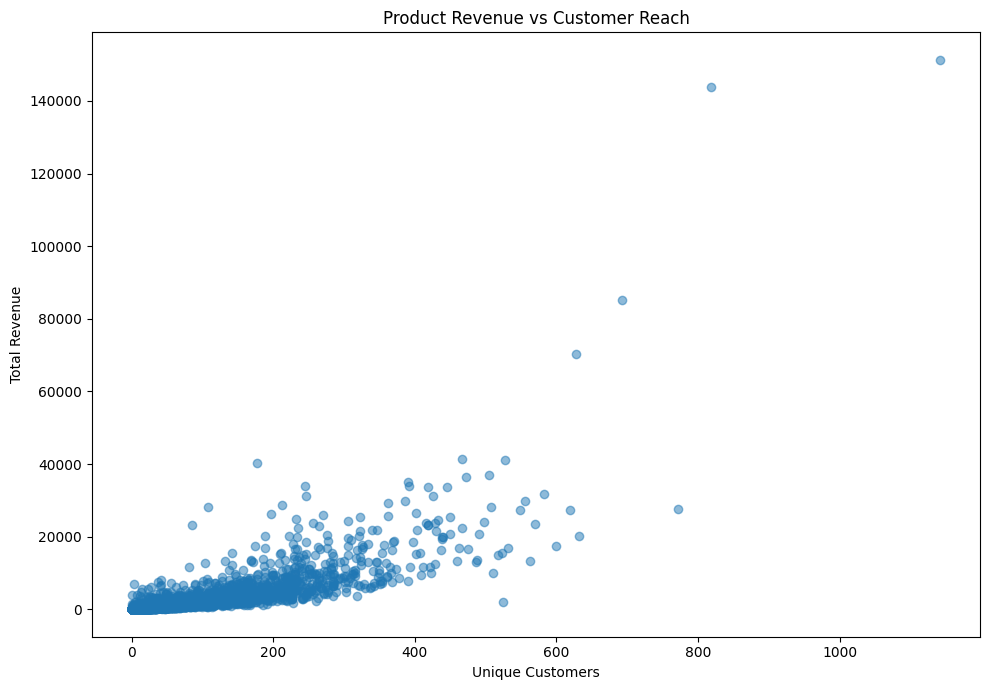

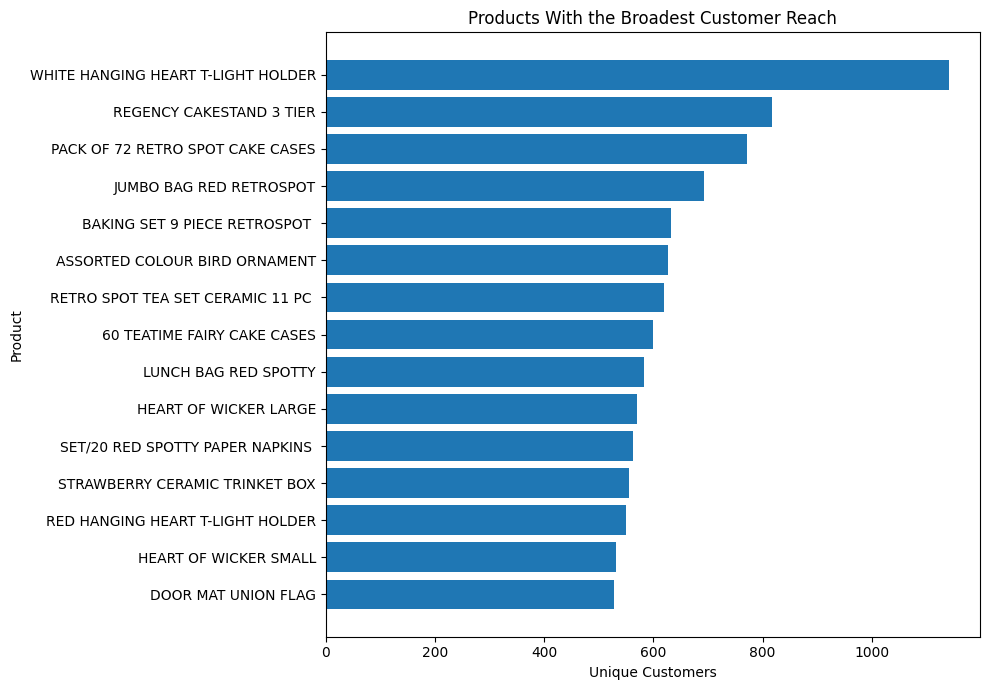

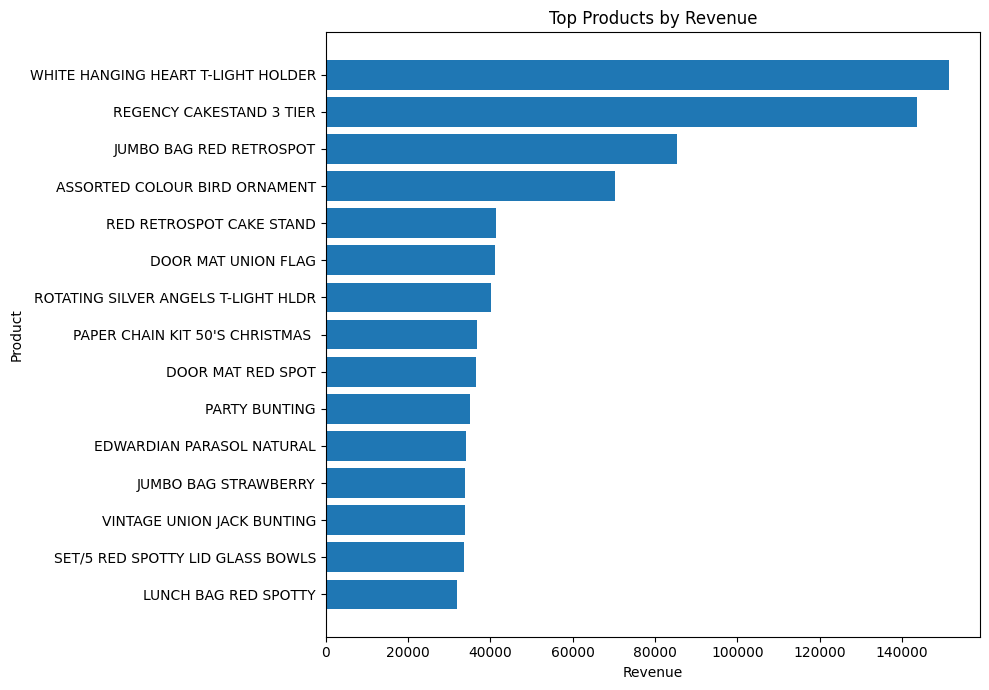


PRODUCT ROLE SUMMARY


,product_role,products,total_revenue,avg_revenue,avg_customer_reach,avg_revenue_per_customer,revenue_share_pct
0,High Revenue / High Reach,1753,7980446.81,4552.45,136.65,28.88,92.25
1,High Revenue / Low Reach,255,289624.58,1135.78,19.30,110.44,3.35
2,Low Revenue / High Reach,262,105422.53,402.38,43.65,9.52,1.22
3,Low Revenue / Low Reach,1745,275466.75,157.86,10.33,17.72,3.18



CROSS-SELLING OPPORTUNITIES


,product_a,description_a,product_b,description_b,co_purchase_orders,support,confidence_a_to_b,confidence_b_to_a,lift
279239,72755C,FLOWER FAIRY OIL BURNER SET ROSE,72755D,FLOWER FAIRY OIL BURNER SET SUMMER,10,0.0005,0.7692,0.7692,1126.5680
39065,17109B,FLOWER FAIRY INCENSE LAVENDER,17109C,FLOWER FAIRY INCENSE ROSE,10,0.0005,0.6250,0.6667,793.2917
197660,17090A,LAVENDER INCENSE 40 CONES IN TIN,17090D,VANILLA INCENSE 40 CONES IN TIN,12,0.0006,0.6667,0.6667,705.1481
773527,84875B,GREEN SQUARE COMPACT MIRROR,84875D,BLUE SQUARE COMPACT MIRROR,19,0.0010,0.9048,0.6552,593.9918
239642,85160A,WHITE BIRD GARDEN DESIGN MUG,85160B,BLACK BIRD GARDEN DESIGN MUG,10,0.0005,0.4545,0.6667,576.9394
75813,35096A,BLUE VICTORIAN FABRIC HEART BOX,35096B,RED VICTORIAN FABRIC HEART BOX,12,0.0006,0.6316,0.5714,572.6015
276527,85028L,FRENCH CHATEAU LARGE FRUIT BOWL,85028S,FRENCH CHATEAU SMALL FRUITBOWL,13,0.0007,0.6190,0.5417,491.0853
584095,84797A,PINK HAWAIIAN PICNIC HAMPER FOR 4,84797B,BLUE SAVANNAH PICNIC HAMPER FOR 4,14,0.0007,0.5600,0.5833,444.2433
399368,85027L,FRENCH CHATEAU LARGE PLATTER,85028L,FRENCH CHATEAU LARGE FRUIT BOWL,11,0.0006,0.4783,0.5238,433.6004
773528,84875B,GREEN SQUARE COMPACT MIRROR,85162C,WHITE RETRODISC LAMPSHADE,19,0.0010,0.9048,0.4634,420.1405



FINAL PRODUCT-CUSTOMER INSIGHTS


,StockCode,total_revenue,total_quantity,total_orders,unique_customers,avg_price,Description,customer_penetration_pct,revenue_per_customer,product_role,high_value_customers,high_value_customer_share_pct,high_value_revenue_share_pct,repeat_customers,repeat_customer_penetration_pct
3624,85123A,151339.16,56814,3021,1141,2.85,WHITE HANGING HEART T-LIGHT HOLDER,26.56,132.64,High Revenue / High Reach,479,41.98,79.93,956,83.79
1489,22423,143727.60,12484,1687,818,12.44,REGENCY CAKESTAND 3 TIER,19.04,175.71,High Revenue / High Reach,411,50.24,85.86,717,87.65
3615,85099B,85257.45,48731,1708,692,1.91,JUMBO BAG RED RETROSPOT,16.11,123.20,High Revenue / High Reach,380,54.91,89.59,602,86.99
2478,84879,70291.03,44431,1333,627,1.67,ASSORTED COLOUR BIRD ORNAMENT,14.59,112.11,High Revenue / High Reach,281,44.82,82.70,536,85.49
1008,21843,41457.64,4056,895,467,10.87,RED RETROSPOT CAKE STAND,10.87,88.77,High Revenue / High Reach,273,58.46,87.98,428,91.65
2176,48138,41223.56,6342,1016,528,7.22,DOOR MAT UNION FLAG,12.29,78.07,High Revenue / High Reach,305,57.77,84.10,458,86.74
2325,84347,40156.05,21579,244,177,2.51,ROTATING SILVER ANGELS T-LIGHT HLDR,4.12,226.87,High Revenue / High Reach,88,49.72,90.64,145,81.92
1179,22086,36871.55,13839,796,505,2.90,PAPER CHAIN KIT 50'S CHRISTMAS,11.76,73.01,High Revenue / High Reach,241,47.72,75.35,433,85.74
100,20685,36417.04,5642,934,472,7.21,DOOR MAT RED SPOT,10.99,77.15,High Revenue / High Reach,284,60.17,87.72,425,90.04
2163,47566,35017.30,8312,710,391,4.57,PARTY BUNTING,9.10,89.56,High Revenue / High Reach,217,55.50,79.12,347,88.75



PHASE 9 COMPLETE

Files saved:
/content/product_customer_performance.csv
/content/product_revenue_by_customer_type.csv
/content/strong_repeat_customer_products.csv
/content/high_value_customer_product_analysis.csv
/content/high_value_customer_product_revenue.csv
/content/product_pair_affinity.csv
/content/top_product_affinity_pairs.csv
/content/cross_sell_opportunities.csv
/content/product_role_summary.csv
/content/product_customer_insights.csv


In [ ]:
# ============================================================
# PHASE 10 — PRODUCT × CUSTOMER RELATIONSHIP ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations
from collections import Counter

print("============================================================")
print("PHASE 10 — PRODUCT × CUSTOMER RELATIONSHIP ANALYSIS")
print("============================================================")

# ============================================================
# 1. LOAD / VERIFY TRANSACTION DATA
# ============================================================

try:
    customer_transactions
    print("\nUsing customer_transactions from memory.")

except NameError:

    customer_transactions = pd.read_csv(
        "/content/online_retail_clean.csv",
        parse_dates=["InvoiceDate"]
    )

    print("\nLoaded cleaned transaction data.")

print(
    "Transaction shape:",
    customer_transactions.shape
)

# Product analysis should exclude POSTAGE and MANUAL
# because these are not actual merchandise products.

product_tx = customer_transactions[
    ~customer_transactions["StockCode"].isin(
        ["POST", "M"]
    )
].copy()

print(
    "Product transaction shape:",
    product_tx.shape
)

# ============================================================
# 2. STANDARDIZE PRODUCT DESCRIPTIONS
# ============================================================
#
# StockCode is our product identifier.
#
# Some StockCodes have multiple descriptions.
# We therefore select the most frequently observed
# description for each StockCode.

product_descriptions = (
    product_tx
    .groupby(
        ["StockCode", "Description"]
    )
    .size()
    .reset_index(
        name="description_count"
    )
    .sort_values(
        ["StockCode", "description_count"],
        ascending=[True, False]
    )
    .drop_duplicates(
        "StockCode"
    )
)

product_descriptions = (
    product_descriptions[
        ["StockCode", "Description"]
    ]
)

print(
    "\nUnique products:",
    product_tx["StockCode"].nunique()
)

# ============================================================
# 3. CUSTOMER VALUE GROUP
# ============================================================
#
# Use customer-level revenue to identify the top quartile
# of customers by historical revenue.

customer_revenue = (
    product_tx
    .groupby("Customer ID")
    ["Revenue"]
    .sum()
    .reset_index(
        name="customer_revenue"
    )
)

high_value_threshold = (
    customer_revenue[
        "customer_revenue"
    ].quantile(0.75)
)

customer_revenue["value_group"] = np.where(
    customer_revenue["customer_revenue"]
    >= high_value_threshold,
    "High-Value Customer",
    "Other Customer"
)

product_tx = product_tx.merge(
    customer_revenue[
        [
            "Customer ID",
            "customer_revenue",
            "value_group"
        ]
    ],
    on="Customer ID",
    how="left"
)

print(
    "\nHigh-value customer revenue threshold:",
    round(high_value_threshold, 2)
)

print(
    "\nCustomer value groups:"
)

print(
    customer_revenue["value_group"]
    .value_counts()
)

# ============================================================
# 4. CUSTOMER TYPE — ONE-TIME VS REPEAT
# ============================================================

customer_order_counts = (
    customer_transactions
    .groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index(
        name="customer_orders"
    )
)

customer_order_counts["customer_type"] = np.where(
    customer_order_counts["customer_orders"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

product_tx = product_tx.merge(
    customer_order_counts[
        [
            "Customer ID",
            "customer_type"
        ]
    ],
    on="Customer ID",
    how="left"
)

# ============================================================
# 5. PRODUCT-LEVEL PERFORMANCE
# ============================================================

product_performance = (
    product_tx
    .groupby("StockCode")
    .agg(
        total_revenue=(
            "Revenue",
            "sum"
        ),
        total_quantity=(
            "Quantity",
            "sum"
        ),
        total_orders=(
            "Invoice",
            "nunique"
        ),
        unique_customers=(
            "Customer ID",
            "nunique"
        ),
        avg_price=(
            "Price",
            "mean"
        )
    )
    .reset_index()
)

product_performance = product_performance.merge(
    product_descriptions,
    on="StockCode",
    how="left"
)

# Product penetration among all customers
total_customers = (
    product_tx["Customer ID"]
    .nunique()
)

product_performance["customer_penetration_pct"] = (
    product_performance["unique_customers"]
    / total_customers
    * 100
)

# Revenue per customer
product_performance["revenue_per_customer"] = (
    product_performance["total_revenue"]
    / product_performance["unique_customers"]
)

print("\n============================================================")
print("PRODUCT PERFORMANCE")
print("============================================================")

display(
    product_performance
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(15)
    .round(2)
)

# ============================================================
# 6. PRODUCT REVENUE BY CUSTOMER TYPE
# ============================================================

product_customer_type = (
    product_tx
    .groupby(
        [
            "StockCode",
            "customer_type"
        ]
    )
    .agg(
        revenue=(
            "Revenue",
            "sum"
        ),
        quantity=(
            "Quantity",
            "sum"
        ),
        customers=(
            "Customer ID",
            "nunique"
        )
    )
    .reset_index()
)

product_customer_type = product_customer_type.merge(
    product_descriptions,
    on="StockCode",
    how="left"
)

# Pivot revenue
product_type_revenue = (
    product_customer_type
    .pivot_table(
        index=[
            "StockCode",
            "Description"
        ],
        columns="customer_type",
        values="revenue",
        fill_value=0
    )
    .reset_index()
)

# Ensure both columns exist
if "Repeat Customer" not in product_type_revenue.columns:
    product_type_revenue["Repeat Customer"] = 0

if "One-Time Customer" not in product_type_revenue.columns:
    product_type_revenue["One-Time Customer"] = 0

product_type_revenue["total_revenue"] = (
    product_type_revenue["Repeat Customer"]
    + product_type_revenue["One-Time Customer"]
)

product_type_revenue["repeat_revenue_share_pct"] = np.where(
    product_type_revenue["total_revenue"] > 0,
    product_type_revenue["Repeat Customer"]
    / product_type_revenue["total_revenue"]
    * 100,
    0
)

print("\n============================================================")
print("PRODUCT REVENUE — REPEAT CUSTOMER SHARE")
print("============================================================")

display(
    product_type_revenue
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(15)
    .round(2)
)

# ============================================================
# 7. PRODUCTS WITH STRONG REPEAT-CUSTOMER PENETRATION
# ============================================================
#
# Filter to products with meaningful customer reach.
#
# This avoids highlighting products purchased by only a
# handful of customers.

product_repeat = (
    product_tx
    .groupby("StockCode")
    .agg(
        total_customers=(
            "Customer ID",
            "nunique"
        ),
        repeat_customers=(
            "Customer ID",
            lambda x: x[
                product_tx.loc[
                    x.index,
                    "customer_type"
                ] == "Repeat Customer"
            ].nunique()
        ),
        total_revenue=(
            "Revenue",
            "sum"
        )
    )
    .reset_index()
)

product_repeat["repeat_customer_penetration_pct"] = (
    product_repeat["repeat_customers"]
    / product_repeat["total_customers"]
    * 100
)

product_repeat = product_repeat.merge(
    product_descriptions,
    on="StockCode",
    how="left"
)

strong_repeat_products = (
    product_repeat[
        product_repeat["total_customers"] >= 50
    ]
    .sort_values(
        [
            "repeat_customer_penetration_pct",
            "total_customers"
        ],
        ascending=[False, False]
    )
)

print("\n============================================================")
print("PRODUCTS WITH STRONG REPEAT-CUSTOMER PENETRATION")
print("Minimum 50 customers")
print("============================================================")

display(
    strong_repeat_products
    .head(20)
    .round(2)
)

# ============================================================
# 8. PRODUCTS POPULAR AMONG HIGH-VALUE CUSTOMERS
# ============================================================

high_value_product_analysis = (
    product_tx
    .groupby("StockCode")
    .agg(
        total_customers=(
            "Customer ID",
            "nunique"
        ),
        high_value_customers=(
            "Customer ID",
            lambda x: x[
                product_tx.loc[
                    x.index,
                    "value_group"
                ] == "High-Value Customer"
            ].nunique()
        ),
        total_revenue=(
            "Revenue",
            "sum"
        ),
        high_value_revenue=(
            "Revenue",
            lambda x: x[
                product_tx.loc[
                    x.index,
                    "value_group"
                ] == "High-Value Customer"
            ].sum()
        )
    )
    .reset_index()
)

high_value_product_analysis[
    "high_value_customer_share_pct"
] = (
    high_value_product_analysis[
        "high_value_customers"
    ]
    / high_value_product_analysis[
        "total_customers"
    ]
    * 100
)

high_value_product_analysis[
    "high_value_revenue_share_pct"
] = np.where(
    high_value_product_analysis["total_revenue"] > 0,
    high_value_product_analysis[
        "high_value_revenue"
    ]
    / high_value_product_analysis[
        "total_revenue"
    ]
    * 100,
    0
)

high_value_product_analysis = (
    high_value_product_analysis
    .merge(
        product_descriptions,
        on="StockCode",
        how="left"
    )
)

print("\n============================================================")
print("PRODUCTS POPULAR AMONG HIGH-VALUE CUSTOMERS")
print("============================================================")

display(
    high_value_product_analysis[
        high_value_product_analysis[
            "total_customers"
        ] >= 50
    ]
    .sort_values(
        "high_value_customer_share_pct",
        ascending=False
    )
    .head(20)
    .round(2)
)

# ============================================================
# 9. HIGH-VALUE CUSTOMER PRODUCT REVENUE
# ============================================================

high_value_revenue_products = (
    product_tx[
        product_tx["value_group"]
        == "High-Value Customer"
    ]
    .groupby("StockCode")
    .agg(
        revenue=(
            "Revenue",
            "sum"
        ),
        customers=(
            "Customer ID",
            "nunique"
        ),
        orders=(
            "Invoice",
            "nunique"
        )
    )
    .reset_index()
)

high_value_revenue_products = (
    high_value_revenue_products
    .merge(
        product_descriptions,
        on="StockCode",
        how="left"
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

print("\n============================================================")
print("TOP PRODUCTS BY HIGH-VALUE CUSTOMER REVENUE")
print("============================================================")

display(
    high_value_revenue_products
    .head(20)
    .round(2)
)

# ============================================================
# 10. CUSTOMER-PRODUCT MATRIX
# ============================================================
#
# Binary matrix:
#
# rows    = customers
# columns = products
# values  = 1 if customer purchased product
#
# This is useful for product affinity analysis.

customer_product = (
    product_tx[
        [
            "Customer ID",
            "StockCode"
        ]
    ]
    .drop_duplicates()
)

print("\nCreating customer-product matrix...")

customer_product_matrix = (
    customer_product
    .assign(purchased=1)
    .pivot_table(
        index="Customer ID",
        columns="StockCode",
        values="purchased",
        fill_value=0
    )
)

print(
    "Customer-product matrix shape:",
    customer_product_matrix.shape
)

# ============================================================
# 11. PRODUCT CO-OCCURRENCE
# ============================================================
#
# Instead of multiplying the entire huge customer-product
# matrix, calculate product pairs within each order.
#
# A pair means:
#     Product A and Product B were purchased in the same order.
#
# This gives us candidate cross-selling relationships.

order_products = (
    product_tx[
        [
            "Invoice",
            "StockCode"
        ]
    ]
    .drop_duplicates()
)

# Only consider orders containing 2+ products
order_product_counts = (
    order_products
    .groupby("Invoice")
    ["StockCode"]
    .nunique()
)

multi_product_orders = (
    order_product_counts[
        order_product_counts >= 2
    ]
    .index
)

order_products_multi = (
    order_products[
        order_products["Invoice"]
        .isin(multi_product_orders)
    ]
)

print(
    "\nOrders with 2+ unique products:",
    len(multi_product_orders)
)

# ============================================================
# 12. CREATE PRODUCT PAIRS
# ============================================================

pair_counter = Counter()

for invoice, group in order_products_multi.groupby(
    "Invoice"
):

    products = sorted(
        group["StockCode"]
        .astype(str)
        .unique()
    )

    # Avoid extremely large baskets dominating computation.
    # Keep all normal baskets; cap very large baskets.
    if len(products) > 50:
        products = products[:50]

    for pair in combinations(
        products,
        2
    ):
        pair_counter[pair] += 1

product_pairs = pd.DataFrame(
    [
        {
            "product_a": pair[0],
            "product_b": pair[1],
            "co_purchase_orders": count
        }
        for pair, count in pair_counter.items()
    ]
)

print(
    "\nUnique product pairs:",
    len(product_pairs)
)

# ============================================================
# 13. CALCULATE PRODUCT SUPPORT
# ============================================================

total_orders = (
    product_tx["Invoice"]
    .nunique()
)

product_order_counts = (
    product_tx
    .groupby("StockCode")["Invoice"]
    .nunique()
    .to_dict()
)

product_pairs["orders_with_a"] = (
    product_pairs["product_a"]
    .map(product_order_counts)
)

product_pairs["orders_with_b"] = (
    product_pairs["product_b"]
    .map(product_order_counts)
)

product_pairs["support"] = (
    product_pairs["co_purchase_orders"]
    / total_orders
)

# ============================================================
# 14. CONFIDENCE
# ============================================================
#
# Confidence(A -> B):
#
# Among orders containing A, how often does B also appear?
#
# This is directional.
#
# We calculate both directions.

product_pairs["confidence_a_to_b"] = (
    product_pairs["co_purchase_orders"]
    / product_pairs["orders_with_a"]
)

product_pairs["confidence_b_to_a"] = (
    product_pairs["co_purchase_orders"]
    / product_pairs["orders_with_b"]
)

# ============================================================
# 15. LIFT
# ============================================================
#
# Lift > 1:
# A and B occur together more often than expected
# based on their individual frequencies.
#
# Lift near 1:
# little evidence of association.
#
# Lift < 1:
# pair occurs less often than expected.

product_pairs["support_a"] = (
    product_pairs["orders_with_a"]
    / total_orders
)

product_pairs["support_b"] = (
    product_pairs["orders_with_b"]
    / total_orders
)

product_pairs["lift"] = (
    product_pairs["support"]
    / (
        product_pairs["support_a"]
        * product_pairs["support_b"]
    )
)

# ============================================================
# 16. ADD PRODUCT DESCRIPTIONS TO PAIRS
# ============================================================

description_map = (
    product_descriptions
    .set_index("StockCode")
    ["Description"]
    .to_dict()
)

product_pairs["description_a"] = (
    product_pairs["product_a"]
    .map(description_map)
)

product_pairs["description_b"] = (
    product_pairs["product_b"]
    .map(description_map)
)

# ============================================================
# 17. FILTER USEFUL PRODUCT PAIRS
# ============================================================
#
# Avoid extremely rare relationships.
#
# At least 10 co-purchase orders.

useful_pairs = product_pairs[
    product_pairs["co_purchase_orders"] >= 10
].copy()

print(
    "\nProduct pairs with at least 10 co-purchases:",
    len(useful_pairs)
)

# ============================================================
# 18. TOP CROSS-SELLING PAIRS BY CO-PURCHASE VOLUME
# ============================================================

top_pairs_volume = (
    useful_pairs
    .sort_values(
        "co_purchase_orders",
        ascending=False
    )
)

print("\n============================================================")
print("TOP PRODUCT PAIRS BY CO-PURCHASE VOLUME")
print("============================================================")

display(
    top_pairs_volume[
        [
            "product_a",
            "description_a",
            "product_b",
            "description_b",
            "co_purchase_orders",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
    .head(20)
    .round(4)
)

# ============================================================
# 19. TOP PRODUCT PAIRS BY LIFT
# ============================================================
#
# Require at least 20 co-purchase orders for more stability.

high_lift_pairs = (
    useful_pairs[
        useful_pairs["co_purchase_orders"] >= 20
    ]
    .sort_values(
        "lift",
        ascending=False
    )
)

print("\n============================================================")
print("TOP PRODUCT PAIRS BY LIFT")
print("Minimum 20 co-purchase orders")
print("============================================================")

display(
    high_lift_pairs[
        [
            "product_a",
            "description_a",
            "product_b",
            "description_b",
            "co_purchase_orders",
            "support",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
    .head(20)
    .round(4)
)

# ============================================================
# 20. PRODUCT AFFINITY SCORE
# ============================================================
#
# Combine:
# - co-purchase volume
# - lift
#
# This is NOT a formal statistical score.
# It is a business ranking measure for the dashboard.

useful_pairs["affinity_score"] = (
    np.log1p(
        useful_pairs["co_purchase_orders"]
    )
    * useful_pairs["lift"]
)

top_affinity_pairs = (
    useful_pairs
    .sort_values(
        "affinity_score",
        ascending=False
    )
)

print("\n============================================================")
print("TOP PRODUCT AFFINITY OPPORTUNITIES")
print("============================================================")

display(
    top_affinity_pairs[
        [
            "product_a",
            "description_a",
            "product_b",
            "description_b",
            "co_purchase_orders",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift",
            "affinity_score"
        ]
    ]
    .head(20)
    .round(4)
)

# ============================================================
# 21. PRODUCT REVENUE VS CUSTOMER REACH
# ============================================================

product_scatter = (
    product_performance[
        [
            "StockCode",
            "Description",
            "total_revenue",
            "unique_customers",
            "revenue_per_customer"
        ]
    ]
    .copy()
)

plt.figure(figsize=(10, 7))

plt.scatter(
    product_scatter["unique_customers"],
    product_scatter["total_revenue"],
    alpha=0.5
)

plt.title(
    "Product Revenue vs Customer Reach"
)

plt.xlabel(
    "Unique Customers"
)

plt.ylabel(
    "Total Revenue"
)

plt.tight_layout()
plt.show()

# ============================================================
# 22. TOP PRODUCTS BY CUSTOMER REACH
# ============================================================

top_reach_products = (
    product_performance
    .sort_values(
        "unique_customers",
        ascending=False
    )
    .head(15)
    .sort_values(
        "unique_customers"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_reach_products["Description"].astype(str),
    top_reach_products["unique_customers"]
)

plt.title(
    "Products With the Broadest Customer Reach"
)

plt.xlabel(
    "Unique Customers"
)

plt.ylabel(
    "Product"
)

plt.tight_layout()
plt.show()

# ============================================================
# 23. TOP PRODUCTS BY REVENUE
# ============================================================

top_revenue_products = (
    product_performance
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(15)
    .sort_values(
        "total_revenue"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_revenue_products["Description"].astype(str),
    top_revenue_products["total_revenue"]
)

plt.title(
    "Top Products by Revenue"
)

plt.xlabel(
    "Revenue"
)

plt.ylabel(
    "Product"
)

plt.tight_layout()
plt.show()

# ============================================================
# 24. IDENTIFY BROAD-REACH PRODUCTS
# ============================================================
#
# Products with:
# - above-median customer reach
# - above-median revenue

reach_median = (
    product_performance[
        "unique_customers"
    ].median()
)

revenue_median = (
    product_performance[
        "total_revenue"
    ].median()
)

product_performance["product_role"] = np.select(
    [
        (
            product_performance[
                "unique_customers"
            ] >= reach_median
        )
        &
        (
            product_performance[
                "total_revenue"
            ] >= revenue_median
        ),

        (
            product_performance[
                "unique_customers"
            ] >= reach_median
        )
        &
        (
            product_performance[
                "total_revenue"
            ] < revenue_median
        ),

        (
            product_performance[
                "unique_customers"
            ] < reach_median
        )
        &
        (
            product_performance[
                "total_revenue"
            ] >= revenue_median
        )
    ],
    [
        "High Revenue / High Reach",
        "Low Revenue / High Reach",
        "High Revenue / Low Reach"
    ],
    default="Low Revenue / Low Reach"
)

product_role_summary = (
    product_performance
    .groupby("product_role")
    .agg(
        products=("StockCode", "count"),
        total_revenue=("total_revenue", "sum"),
        avg_revenue=("total_revenue", "mean"),
        avg_customer_reach=("unique_customers", "mean"),
        avg_revenue_per_customer=(
            "revenue_per_customer",
            "mean"
        )
    )
    .reset_index()
)

product_role_summary["revenue_share_pct"] = (
    product_role_summary[
        "total_revenue"
    ]
    / product_role_summary[
        "total_revenue"
    ].sum()
    * 100
)

print("\n============================================================")
print("PRODUCT ROLE SUMMARY")
print("============================================================")

display(
    product_role_summary.round(2)
)

# ============================================================
# 25. CROSS-SELLING OPPORTUNITY TABLE
# ============================================================
#
# Focus on product pairs that have:
# - meaningful co-purchase volume
# - lift > 1
#
# This creates a business-ready cross-selling table.

cross_sell_opportunities = useful_pairs[
    useful_pairs["lift"] > 1
].copy()

cross_sell_opportunities = (
    cross_sell_opportunities
    .sort_values(
        [
            "lift",
            "co_purchase_orders"
        ],
        ascending=[False, False]
    )
)

print("\n============================================================")
print("CROSS-SELLING OPPORTUNITIES")
print("============================================================")

display(
    cross_sell_opportunities[
        [
            "product_a",
            "description_a",
            "product_b",
            "description_b",
            "co_purchase_orders",
            "support",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
    .head(30)
    .round(4)
)

# ============================================================
# 26. FINAL PRODUCT-CUSTOMER INSIGHTS TABLE
# ============================================================

product_customer_insights = (
    product_performance
    .merge(
        high_value_product_analysis[
            [
                "StockCode",
                "high_value_customers",
                "high_value_customer_share_pct",
                "high_value_revenue_share_pct"
            ]
        ],
        on="StockCode",
        how="left"
    )
)

product_customer_insights = (
    product_customer_insights
    .merge(
        product_repeat[
            [
                "StockCode",
                "repeat_customers",
                "repeat_customer_penetration_pct"
            ]
        ],
        on="StockCode",
        how="left"
    )
)

print("\n============================================================")
print("FINAL PRODUCT-CUSTOMER INSIGHTS")
print("============================================================")

display(
    product_customer_insights
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(20)
    .round(2)
)

# ============================================================
# 27. SAVE PHASE 10 OUTPUTS
# ============================================================

product_performance.to_csv(
    "/content/product_customer_performance.csv",
    index=False
)

product_type_revenue.to_csv(
    "/content/product_revenue_by_customer_type.csv",
    index=False
)

strong_repeat_products.to_csv(
    "/content/strong_repeat_customer_products.csv",
    index=False
)

high_value_product_analysis.to_csv(
    "/content/high_value_customer_product_analysis.csv",
    index=False
)

high_value_revenue_products.to_csv(
    "/content/high_value_customer_product_revenue.csv",
    index=False
)

product_pairs.to_csv(
    "/content/product_pair_affinity.csv",
    index=False
)

top_affinity_pairs.to_csv(
    "/content/top_product_affinity_pairs.csv",
    index=False
)

cross_sell_opportunities.to_csv(
    "/content/cross_sell_opportunities.csv",
    index=False
)

product_role_summary.to_csv(
    "/content/product_role_summary.csv",
    index=False
)

product_customer_insights.to_csv(
    "/content/product_customer_insights.csv",
    index=False
)

print("\n============================================================")
print("PHASE 10 COMPLETE")
print("============================================================")

print("\nFiles saved:")

print(
    "/content/product_customer_performance.csv"
)

print(
    "/content/product_revenue_by_customer_type.csv"
)

print(
    "/content/strong_repeat_customer_products.csv"
)

print(
    "/content/high_value_customer_product_analysis.csv"
)

print(
    "/content/high_value_customer_product_revenue.csv"
)

print(
    "/content/product_pair_affinity.csv"
)

print(
    "/content/top_product_affinity_pairs.csv"
)

print(
    "/content/cross_sell_opportunities.csv"
)

print(
    "/content/product_role_summary.csv"
)

print(
    "/content/product_customer_insights.csv"
)


## Phase 11 — SQL Analytics Layer

Build a reusable analytical SQL layer in DuckDB using the cleaned transaction data.

The SQL work covers executive KPIs, monthly revenue, customer rankings, repeat behavior, customer-value quartiles, product concentration, geographic performance, purchase gaps, active customers, new versus returning customers, RFM analytics, and customer revenue concentration.


In [ ]:
# ============================================================
# PHASE 11 — SQL ANALYTICS LAYER
# Product Analytics & Customer Intelligence Platform
#
# ============================================================

# This phase demonstrates:
# - SQL data preparation
# - GROUP BY
# - CASE WHEN
# - CTEs
# - Window functions
# - LAG
# - DENSE_RANK
# - NTILE
# - Customer segmentation
# - Product analysis
# - Revenue concentration
# - New vs returning customers
# - RFM analysis
# - Analytics views
# ============================================================


# ------------------------------------------------------------
# 1. INSTALL + IMPORT
# ------------------------------------------------------------

!pip -q install duckdb

import duckdb
import pandas as pd
import numpy as np
import os

print("=" * 60)
print("PHASE 11 — SQL ANALYTICS LAYER")
print("=" * 60)


# ------------------------------------------------------------
# 2. LOAD CLEAN TRANSACTION DATA
# ------------------------------------------------------------

if "customer_transactions" in globals():

    sql_transactions = customer_transactions.copy()

    print("\nUsing customer_transactions from memory.")

elif os.path.exists("/content/online_retail_clean.csv"):

    sql_transactions = pd.read_csv(
        "/content/online_retail_clean.csv",
        parse_dates=["InvoiceDate"]
    )

    print("\nLoaded /content/online_retail_clean.csv")

else:

    raise FileNotFoundError(
        "Could not find customer_transactions or "
        "/content/online_retail_clean.csv"
    )


# ------------------------------------------------------------
# 3. KEEP ONLY REQUIRED ORIGINAL TRANSACTION COLUMNS
#
# This is important because earlier phases may have added
# Period[M] columns such as PurchaseMonth or CohortMonth.
# DuckDB cannot directly register Pandas Period columns.
# ------------------------------------------------------------

required_columns = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "Price",
    "Customer ID",
    "Country",
    "Revenue"
]

missing_columns = [
    col
    for col in required_columns
    if col not in sql_transactions.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


sql_transactions = sql_transactions[
    required_columns
].copy()


# ------------------------------------------------------------
# 4. FIX DATA TYPES
# ------------------------------------------------------------

sql_transactions["InvoiceDate"] = pd.to_datetime(
    sql_transactions["InvoiceDate"]
)

sql_transactions["Invoice"] = (
    sql_transactions["Invoice"]
    .astype(str)
)

sql_transactions["StockCode"] = (
    sql_transactions["StockCode"]
    .astype(str)
)

sql_transactions["Description"] = (
    sql_transactions["Description"]
    .astype(str)
)

sql_transactions["Country"] = (
    sql_transactions["Country"]
    .astype(str)
)

sql_transactions["Customer ID"] = (
    pd.to_numeric(
        sql_transactions["Customer ID"],
        errors="coerce"
    )
)

sql_transactions["Quantity"] = (
    pd.to_numeric(
        sql_transactions["Quantity"],
        errors="coerce"
    )
)

sql_transactions["Price"] = (
    pd.to_numeric(
        sql_transactions["Price"],
        errors="coerce"
    )
)

sql_transactions["Revenue"] = (
    pd.to_numeric(
        sql_transactions["Revenue"],
        errors="coerce"
    )
)


# ------------------------------------------------------------
# EXTRA SAFETY CHECK FOR PERIOD COLUMNS
# ------------------------------------------------------------

period_columns = []

for col in sql_transactions.columns:

    if isinstance(
        sql_transactions[col].dtype,
        pd.PeriodDtype
    ):

        period_columns.append(col)

        sql_transactions[col] = (
            sql_transactions[col]
            .astype(str)
        )


print(
    "\nPeriod columns converted:",
    period_columns
)


# ------------------------------------------------------------
# 5. VERIFY DATA BEFORE SQL
# ------------------------------------------------------------

print(
    "\nTransaction shape:",
    sql_transactions.shape
)

print(
    "Date range:",
    sql_transactions["InvoiceDate"].min(),
    "to",
    sql_transactions["InvoiceDate"].max()
)

print("\nColumns:")
print(
    sql_transactions.columns.tolist()
)

print("\nData types:")
print(
    sql_transactions.dtypes
)


# ------------------------------------------------------------
# 6. CREATE DUCKDB DATABASE
# ------------------------------------------------------------

try:
    con.close()
except:
    pass


con = duckdb.connect(
    "/content/product_analytics.duckdb"
)


con.register(
    "transactions_df",
    sql_transactions
)


con.execute("""
DROP TABLE IF EXISTS transactions;
""")


con.execute("""
CREATE TABLE transactions AS

SELECT *
FROM transactions_df;
""")


row_count = con.execute("""
SELECT COUNT(*)
FROM transactions;
""").fetchone()[0]


print("\n" + "=" * 60)
print("DUCKDB DATABASE CREATED")
print("=" * 60)

print(
    "Rows loaded into SQL:",
    f"{row_count:,}"
)


# ------------------------------------------------------------
# 7. VERIFY SQL SCHEMA
# ------------------------------------------------------------

sql_schema = con.execute("""
DESCRIBE transactions;
""").df()

print("\nSQL TABLE SCHEMA")
display(sql_schema)


# ------------------------------------------------------------
# 8. SQL DATA QUALITY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SQL DATA QUALITY CHECK")
print("=" * 60)


sql_quality = con.execute("""

SELECT

    COUNT(*) AS total_rows,

    COUNT(
        DISTINCT Invoice
    ) AS unique_orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS unique_customers,

    COUNT(
        DISTINCT StockCode
    ) AS unique_stockcodes,

    ROUND(
        SUM(Revenue),
        2
    ) AS total_revenue,

    MIN(
        InvoiceDate
    ) AS first_transaction,

    MAX(
        InvoiceDate
    ) AS last_transaction,

    SUM(
        CASE
            WHEN Quantity <= 0
            THEN 1
            ELSE 0
        END
    ) AS invalid_quantity_rows,

    SUM(
        CASE
            WHEN Price <= 0
            THEN 1
            ELSE 0
        END
    ) AS invalid_price_rows

FROM transactions;

""").df()


display(sql_quality)


# ============================================================
# QUERY 1 — EXECUTIVE BUSINESS KPIs
# ============================================================

print("\n" + "=" * 60)
print("QUERY 1 — EXECUTIVE BUSINESS KPIs")
print("=" * 60)


sql_kpis = con.execute("""

WITH order_summary AS (

    SELECT

        Invoice,

        "Customer ID" AS customer_id,

        SUM(
            Revenue
        ) AS order_revenue,

        SUM(
            Quantity
        ) AS order_items

    FROM transactions

    GROUP BY
        Invoice,
        "Customer ID"
)

SELECT

    COUNT(*) AS total_orders,

    COUNT(
        DISTINCT customer_id
    ) AS total_customers,

    ROUND(
        SUM(order_revenue),
        2
    ) AS total_revenue,

    ROUND(
        AVG(order_revenue),
        2
    ) AS average_order_value,

    ROUND(
        AVG(order_items),
        2
    ) AS average_items_per_order

FROM order_summary;

""").df()


display(sql_kpis)


# ============================================================
# QUERY 2 — MONTHLY REVENUE + MONTH-OVER-MONTH GROWTH
# ============================================================

print("\n" + "=" * 60)
print("QUERY 2 — MONTHLY REVENUE + MoM GROWTH")
print("=" * 60)


sql_monthly_revenue = con.execute("""

WITH monthly AS (

    SELECT

        DATE_TRUNC(
            'month',
            InvoiceDate
        ) AS month,

        ROUND(
            SUM(Revenue),
            2
        ) AS revenue,

        COUNT(
            DISTINCT Invoice
        ) AS orders,

        COUNT(
            DISTINCT "Customer ID"
        ) AS customers

    FROM transactions

    GROUP BY 1
),

monthly_with_previous AS (

    SELECT

        *,

        LAG(revenue) OVER (
            ORDER BY month
        ) AS previous_month_revenue

    FROM monthly
)

SELECT

    month,

    revenue,

    orders,

    customers,

    ROUND(
        revenue
        / NULLIF(orders, 0),
        2
    ) AS avg_order_value,

    ROUND(

        (
            revenue
            - previous_month_revenue
        )

        / NULLIF(
            previous_month_revenue,
            0
        )

        * 100,

        2

    ) AS mom_revenue_growth_pct

FROM monthly_with_previous

ORDER BY month;

""").df()


display(sql_monthly_revenue)


print(
    "\nNOTE: December 2010 is partial through December 9, "
    "so its monthly decline should not be interpreted as "
    "a complete month-over-month business decline."
)


# ============================================================
# QUERY 3 — TOP CUSTOMERS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 3 — TOP CUSTOMERS BY REVENUE")
print("=" * 60)


sql_top_customers = con.execute("""

WITH customer_metrics AS (

    SELECT

        "Customer ID" AS customer_id,

        ROUND(
            SUM(Revenue),
            2
        ) AS total_revenue,

        COUNT(
            DISTINCT Invoice
        ) AS total_orders,

        SUM(
            Quantity
        ) AS total_items,

        COUNT(
            DISTINCT StockCode
        ) AS unique_products,

        MIN(
            InvoiceDate
        ) AS first_purchase,

        MAX(
            InvoiceDate
        ) AS last_purchase

    FROM transactions

    GROUP BY
        "Customer ID"
)

SELECT

    *,

    ROUND(
        total_revenue
        / NULLIF(total_orders, 0),
        2
    ) AS avg_order_value,

    DENSE_RANK() OVER (
        ORDER BY total_revenue DESC
    ) AS revenue_rank

FROM customer_metrics

ORDER BY
    total_revenue DESC

LIMIT 20;

""").df()


display(sql_top_customers)


# ============================================================
# QUERY 4 — ONE-TIME VS REPEAT CUSTOMERS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 4 — ONE-TIME VS REPEAT CUSTOMERS")
print("=" * 60)


sql_customer_type = con.execute("""

WITH customer_metrics AS (

    SELECT

        "Customer ID" AS customer_id,

        COUNT(
            DISTINCT Invoice
        ) AS orders,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    GROUP BY
        "Customer ID"
),

classified AS (

    SELECT

        *,

        CASE

            WHEN orders = 1
            THEN 'One-Time Customer'

            ELSE 'Repeat Customer'

        END AS customer_type

    FROM customer_metrics
)

SELECT

    customer_type,

    COUNT(*) AS customers,

    ROUND(
        COUNT(*) * 100.0
        / SUM(COUNT(*)) OVER (),
        2
    ) AS customer_share_pct,

    ROUND(
        SUM(revenue),
        2
    ) AS revenue,

    ROUND(
        SUM(revenue) * 100.0
        / SUM(SUM(revenue)) OVER (),
        2
    ) AS revenue_share_pct,

    ROUND(
        AVG(revenue),
        2
    ) AS avg_customer_revenue,

    ROUND(
        AVG(orders),
        2
    ) AS avg_orders

FROM classified

GROUP BY
    customer_type

ORDER BY
    revenue DESC;

""").df()


display(sql_customer_type)


# ============================================================
# QUERY 5 — CUSTOMER VALUE QUARTILES
# ============================================================

print("\n" + "=" * 60)
print("QUERY 5 — CUSTOMER VALUE QUARTILES")
print("=" * 60)


sql_customer_quartiles = con.execute("""

WITH customer_revenue AS (

    SELECT

        "Customer ID" AS customer_id,

        SUM(
            Revenue
        ) AS revenue,

        COUNT(
            DISTINCT Invoice
        ) AS orders

    FROM transactions

    GROUP BY
        "Customer ID"
),

quartiles AS (

    SELECT

        *,

        NTILE(4) OVER (
            ORDER BY revenue DESC
        ) AS value_quartile

    FROM customer_revenue
)

SELECT

    value_quartile,

    COUNT(*) AS customers,

    ROUND(
        SUM(revenue),
        2
    ) AS total_revenue,

    ROUND(
        SUM(revenue) * 100.0
        / SUM(SUM(revenue)) OVER (),
        2
    ) AS revenue_share_pct,

    ROUND(
        AVG(revenue),
        2
    ) AS avg_customer_revenue,

    ROUND(
        AVG(orders),
        2
    ) AS avg_orders

FROM quartiles

GROUP BY
    value_quartile

ORDER BY
    value_quartile;

""").df()


display(sql_customer_quartiles)


# ============================================================
# QUERY 6 — TOP PRODUCTS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 6 — TOP PRODUCTS BY REVENUE")
print("=" * 60)


sql_top_products = con.execute("""

WITH description_counts AS (

    SELECT

        StockCode,

        Description,

        COUNT(*) AS description_count

    FROM transactions

    WHERE StockCode NOT IN ('POST', 'M')

    GROUP BY
        StockCode,
        Description
),

description_ranked AS (

    SELECT

        *,

        ROW_NUMBER() OVER (

            PARTITION BY StockCode

            ORDER BY
                description_count DESC,
                Description

        ) AS description_rank

    FROM description_counts
),

preferred_description AS (

    SELECT

        StockCode,
        Description

    FROM description_ranked

    WHERE description_rank = 1
),

product_metrics AS (

    SELECT

        StockCode,

        ROUND(
            SUM(Revenue),
            2
        ) AS total_revenue,

        SUM(
            Quantity
        ) AS total_quantity,

        COUNT(
            DISTINCT Invoice
        ) AS total_orders,

        COUNT(
            DISTINCT "Customer ID"
        ) AS unique_customers

    FROM transactions

    WHERE StockCode NOT IN ('POST', 'M')

    GROUP BY
        StockCode
)

SELECT

    p.StockCode,

    d.Description,

    p.total_revenue,

    p.total_quantity,

    p.total_orders,

    p.unique_customers,

    ROUND(
        p.total_revenue
        / NULLIF(
            p.unique_customers,
            0
        ),
        2
    ) AS revenue_per_customer,

    DENSE_RANK() OVER (
        ORDER BY p.total_revenue DESC
    ) AS revenue_rank

FROM product_metrics p

LEFT JOIN preferred_description d

ON p.StockCode = d.StockCode

ORDER BY
    p.total_revenue DESC

LIMIT 20;

""").df()


display(sql_top_products)


# ============================================================
# QUERY 7 — PRODUCT PARETO / REVENUE CONCENTRATION
# ============================================================

print("\n" + "=" * 60)
print("QUERY 7 — PRODUCT REVENUE CONCENTRATION")
print("=" * 60)


sql_product_pareto = con.execute("""

WITH product_revenue AS (

    SELECT

        StockCode,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    WHERE StockCode NOT IN ('POST', 'M')

    GROUP BY
        StockCode
),

ranked AS (

    SELECT

        StockCode,

        revenue,

        ROW_NUMBER() OVER (
            ORDER BY revenue DESC
        ) AS product_rank,

        SUM(revenue) OVER (

            ORDER BY revenue DESC

            ROWS BETWEEN
            UNBOUNDED PRECEDING
            AND CURRENT ROW

        ) AS cumulative_revenue,

        SUM(revenue) OVER () AS total_revenue,

        COUNT(*) OVER () AS total_products

    FROM product_revenue
),

calculated AS (

    SELECT

        *,

        cumulative_revenue
        / NULLIF(total_revenue, 0)
        * 100 AS cumulative_revenue_pct

    FROM ranked
)

SELECT

    MIN(product_rank)
        AS products_needed_for_80pct_revenue,

    MAX(total_products)
        AS total_products,

    ROUND(

        MIN(product_rank)
        * 100.0
        / MAX(total_products),

        2

    ) AS product_pct_needed

FROM calculated

WHERE cumulative_revenue_pct >= 80;

""").df()


display(sql_product_pareto)


# ============================================================
# QUERY 8 — COUNTRY PERFORMANCE
# ============================================================

print("\n" + "=" * 60)
print("QUERY 8 — COUNTRY PERFORMANCE")
print("=" * 60)


sql_country_performance = con.execute("""

SELECT

    Country,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers,

    ROUND(

        SUM(Revenue)
        / NULLIF(
            COUNT(DISTINCT Invoice),
            0
        ),

        2

    ) AS avg_order_value,

    ROUND(

        SUM(Revenue)
        * 100.0
        / SUM(SUM(Revenue)) OVER (),

        2

    ) AS revenue_share_pct

FROM transactions

GROUP BY
    Country

ORDER BY
    revenue DESC;

""").df()


display(
    sql_country_performance.head(20)
)


# ============================================================
# QUERY 9 — CUSTOMER PURCHASE GAPS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 9 — CUSTOMER PURCHASE GAPS")
print("=" * 60)


sql_purchase_gaps = con.execute("""

WITH invoice_level AS (

    SELECT

        "Customer ID" AS customer_id,

        Invoice,

        MIN(InvoiceDate) AS order_datetime

    FROM transactions

    GROUP BY
        "Customer ID",
        Invoice
),

previous_orders AS (

    SELECT

        customer_id,

        Invoice,

        order_datetime,

        LAG(order_datetime) OVER (

            PARTITION BY customer_id

            ORDER BY order_datetime

        ) AS previous_purchase

    FROM invoice_level
),

purchase_gaps AS (

    SELECT

        customer_id,

        DATE_DIFF(
            'day',
            previous_purchase,
            order_datetime
        ) AS days_between_purchases

    FROM previous_orders

    WHERE previous_purchase IS NOT NULL
)

SELECT

    COUNT(
        DISTINCT customer_id
    ) AS repeat_customers,

    ROUND(
        AVG(days_between_purchases),
        2
    ) AS avg_days_between_orders,

    ROUND(
        MEDIAN(days_between_purchases),
        2
    ) AS median_days_between_orders,

    MIN(
        days_between_purchases
    ) AS minimum_gap_days,

    MAX(
        days_between_purchases
    ) AS maximum_gap_days

FROM purchase_gaps;

""").df()


display(sql_purchase_gaps)


# ============================================================
# QUERY 10 — MONTHLY ACTIVE CUSTOMERS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 10 — MONTHLY ACTIVE CUSTOMERS")
print("=" * 60)


sql_monthly_active = con.execute("""

SELECT

    DATE_TRUNC(
        'month',
        InvoiceDate
    ) AS month,

    COUNT(
        DISTINCT "Customer ID"
    ) AS active_customers,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    ROUND(

        SUM(Revenue)
        / NULLIF(
            COUNT(DISTINCT "Customer ID"),
            0
        ),

        2

    ) AS revenue_per_active_customer

FROM transactions

GROUP BY 1

ORDER BY 1;

""").df()


display(sql_monthly_active)


# ============================================================
# QUERY 11 — NEW VS RETURNING CUSTOMERS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 11 — NEW VS RETURNING CUSTOMERS")
print("=" * 60)


sql_new_returning = con.execute("""

WITH first_purchase AS (

    SELECT

        "Customer ID" AS customer_id,

        DATE_TRUNC(
            'month',
            MIN(InvoiceDate)
        ) AS first_purchase_month

    FROM transactions

    GROUP BY
        "Customer ID"
),

monthly_activity AS (

    SELECT DISTINCT

        "Customer ID" AS customer_id,

        DATE_TRUNC(
            'month',
            InvoiceDate
        ) AS activity_month

    FROM transactions
),

classified AS (

    SELECT

        a.activity_month,

        a.customer_id,

        CASE

            WHEN
                a.activity_month
                = f.first_purchase_month

            THEN 'New Customer'

            ELSE 'Returning Customer'

        END AS customer_status

    FROM monthly_activity a

    INNER JOIN first_purchase f

        ON a.customer_id = f.customer_id
)

SELECT

    activity_month AS month,

    SUM(

        CASE

            WHEN customer_status = 'New Customer'
            THEN 1

            ELSE 0

        END

    ) AS new_customers,

    SUM(

        CASE

            WHEN customer_status = 'Returning Customer'
            THEN 1

            ELSE 0

        END

    ) AS returning_customers,

    COUNT(*) AS active_customers,

    ROUND(

        SUM(

            CASE

                WHEN customer_status = 'Returning Customer'
                THEN 1

                ELSE 0

            END

        )

        * 100.0

        / NULLIF(COUNT(*), 0),

        2

    ) AS returning_customer_share_pct

FROM classified

GROUP BY
    activity_month

ORDER BY
    activity_month;

""").df()


display(sql_new_returning)


# ============================================================
# QUERY 12 — RFM ANALYSIS IN SQL
# ============================================================

print("\n" + "=" * 60)
print("QUERY 12 — RFM ANALYSIS IN SQL")
print("=" * 60)


sql_rfm = con.execute("""

WITH reference_date AS (

    SELECT

        MAX(InvoiceDate)
        + INTERVAL '1 day'
        AS reference_date

    FROM transactions
),

customer_rfm AS (

    SELECT

        t."Customer ID" AS customer_id,

        DATE_DIFF(

            'day',

            MAX(t.InvoiceDate),

            MAX(r.reference_date)

        ) AS recency,

        COUNT(
            DISTINCT t.Invoice
        ) AS frequency,

        ROUND(
            SUM(t.Revenue),
            2
        ) AS monetary

    FROM transactions t

    CROSS JOIN reference_date r

    GROUP BY
        t."Customer ID"
),

recency_scored AS (

    SELECT

        *,

        6 - NTILE(5) OVER (
            ORDER BY recency ASC
        ) AS recency_score

    FROM customer_rfm
),

frequency_scored AS (

    SELECT

        *,

        NTILE(5) OVER (
            ORDER BY frequency ASC
        ) AS frequency_score

    FROM recency_scored
),

fully_scored AS (

    SELECT

        *,

        NTILE(5) OVER (
            ORDER BY monetary ASC
        ) AS monetary_score

    FROM frequency_scored
)

SELECT

    customer_id,

    recency,

    frequency,

    monetary,

    recency_score,

    frequency_score,

    monetary_score,

    recency_score
    + frequency_score
    + monetary_score
        AS rfm_total

FROM fully_scored

ORDER BY
    rfm_total DESC,
    monetary DESC;

""").df()


display(
    sql_rfm.head(20)
)


# ============================================================
# QUERY 13 — HIGH-VALUE CUSTOMER PRODUCT ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("QUERY 13 — PRODUCTS PURCHASED BY HIGH-VALUE CUSTOMERS")
print("=" * 60)


sql_high_value_products = con.execute("""

WITH customer_revenue AS (

    SELECT

        "Customer ID" AS customer_id,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    GROUP BY
        "Customer ID"
),

customer_value AS (

    SELECT

        *,

        NTILE(4) OVER (
            ORDER BY revenue DESC
        ) AS value_quartile

    FROM customer_revenue
),

product_customer AS (

    SELECT

        t.StockCode,

        t."Customer ID" AS customer_id,

        SUM(
            t.Revenue
        ) AS revenue

    FROM transactions t

    WHERE t.StockCode NOT IN (
        'POST',
        'M'
    )

    GROUP BY
        t.StockCode,
        t."Customer ID"
)

SELECT

    p.StockCode,

    COUNT(
        DISTINCT p.customer_id
    ) AS total_customers,

    COUNT(
        DISTINCT CASE

            WHEN c.value_quartile = 1
            THEN p.customer_id

        END
    ) AS high_value_customers,

    ROUND(
        SUM(p.revenue),
        2
    ) AS total_revenue,

    ROUND(

        SUM(

            CASE

                WHEN c.value_quartile = 1
                THEN p.revenue

                ELSE 0

            END

        ),

        2

    ) AS high_value_revenue,

    ROUND(

        COUNT(

            DISTINCT CASE

                WHEN c.value_quartile = 1
                THEN p.customer_id

            END

        )

        * 100.0

        / NULLIF(
            COUNT(DISTINCT p.customer_id),
            0
        ),

        2

    ) AS high_value_customer_share_pct

FROM product_customer p

INNER JOIN customer_value c

ON p.customer_id = c.customer_id

GROUP BY
    p.StockCode

HAVING
    COUNT(DISTINCT p.customer_id) >= 50

ORDER BY
    high_value_customer_share_pct DESC,
    total_revenue DESC

LIMIT 30;

""").df()


display(sql_high_value_products)


# ============================================================
# QUERY 14 — TOP PRODUCT IN EACH COUNTRY
# ============================================================

print("\n" + "=" * 60)
print("QUERY 14 — TOP PRODUCT BY COUNTRY")
print("=" * 60)


sql_country_top_product = con.execute("""

WITH product_country AS (

    SELECT

        Country,

        StockCode,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    WHERE StockCode NOT IN (
        'POST',
        'M'
    )

    GROUP BY
        Country,
        StockCode
),

ranked AS (

    SELECT

        *,

        DENSE_RANK() OVER (

            PARTITION BY Country

            ORDER BY revenue DESC

        ) AS product_rank

    FROM product_country
)

SELECT

    Country,

    StockCode,

    ROUND(
        revenue,
        2
    ) AS revenue

FROM ranked

WHERE product_rank = 1

ORDER BY
    revenue DESC;

""").df()


display(
    sql_country_top_product.head(20)
)


# ============================================================
# QUERY 15 — CUSTOMER REVENUE CONCENTRATION
# ============================================================

print("\n" + "=" * 60)
print("QUERY 15 — CUSTOMER REVENUE CONCENTRATION")
print("=" * 60)


sql_customer_concentration = con.execute("""

WITH customer_revenue AS (

    SELECT

        "Customer ID" AS customer_id,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    GROUP BY
        "Customer ID"
),

ranked AS (

    SELECT

        *,

        ROW_NUMBER() OVER (
            ORDER BY revenue DESC
        ) AS customer_rank,

        COUNT(*) OVER ()
            AS total_customers,

        SUM(revenue) OVER ()
            AS total_revenue

    FROM customer_revenue
),

groups AS (

    SELECT

        *,

        CASE

            WHEN
                customer_rank
                <= CEIL(
                    total_customers * 0.10
                )

            THEN 'Top 10%'

            WHEN
                customer_rank
                <= CEIL(
                    total_customers * 0.25
                )

            THEN 'Top 11-25%'

            WHEN
                customer_rank
                <= CEIL(
                    total_customers * 0.50
                )

            THEN 'Middle 26-50%'

            ELSE 'Bottom 50%'

        END AS customer_group

    FROM ranked
)

SELECT

    customer_group,

    COUNT(*) AS customers,

    ROUND(
        SUM(revenue),
        2
    ) AS revenue,

    ROUND(

        SUM(revenue)
        * 100.0
        / MAX(total_revenue),

        2

    ) AS revenue_share_pct

FROM groups

GROUP BY
    customer_group

ORDER BY

    CASE customer_group

        WHEN 'Top 10%'
        THEN 1

        WHEN 'Top 11-25%'
        THEN 2

        WHEN 'Middle 26-50%'
        THEN 3

        ELSE 4

    END;

""").df()


display(sql_customer_concentration)


# ============================================================
# 9. CREATE ANALYTICS VIEWS
# ============================================================

print("\n" + "=" * 60)
print("CREATING SQL ANALYTICS VIEWS")
print("=" * 60)


con.execute("""

CREATE OR REPLACE VIEW customer_analytics AS

SELECT

    "Customer ID" AS customer_id,

    COUNT(
        DISTINCT Invoice
    ) AS total_orders,

    SUM(
        Quantity
    ) AS total_items,

    COUNT(
        DISTINCT StockCode
    ) AS unique_products,

    SUM(
        Revenue
    ) AS total_revenue,

    MIN(
        InvoiceDate
    ) AS first_purchase,

    MAX(
        InvoiceDate
    ) AS last_purchase,

    SUM(Revenue)
    / NULLIF(
        COUNT(DISTINCT Invoice),
        0
    ) AS avg_order_value

FROM transactions

GROUP BY
    "Customer ID";

""")


con.execute("""

CREATE OR REPLACE VIEW product_analytics AS

SELECT

    StockCode,

    SUM(
        Revenue
    ) AS total_revenue,

    SUM(
        Quantity
    ) AS total_quantity,

    COUNT(
        DISTINCT Invoice
    ) AS total_orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS unique_customers

FROM transactions

WHERE StockCode NOT IN (
    'POST',
    'M'
)

GROUP BY
    StockCode;

""")


con.execute("""

CREATE OR REPLACE VIEW monthly_analytics AS

SELECT

    DATE_TRUNC(
        'month',
        InvoiceDate
    ) AS month,

    SUM(
        Revenue
    ) AS revenue,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers

FROM transactions

GROUP BY 1;

""")


print(
    "Created: customer_analytics"
)

print(
    "Created: product_analytics"
)

print(
    "Created: monthly_analytics"
)


# ============================================================
# 10. VERIFY TABLES + VIEWS
# ============================================================

sql_views = con.execute("""

SELECT

    table_name,

    table_type

FROM information_schema.tables

WHERE table_name IN (

    'transactions',

    'customer_analytics',

    'product_analytics',

    'monthly_analytics'

)

ORDER BY
    table_name;

""").df()


print("\nSQL TABLES AND VIEWS:")
display(sql_views)


# ============================================================
# 11. EXPORT RESULTS
# ============================================================

print("\n" + "=" * 60)
print("EXPORTING SQL RESULTS")
print("=" * 60)


exports = {

    "sql_data_quality.csv":
        sql_quality,

    "sql_business_kpis.csv":
        sql_kpis,

    "sql_monthly_revenue.csv":
        sql_monthly_revenue,

    "sql_top_customers.csv":
        sql_top_customers,

    "sql_customer_type.csv":
        sql_customer_type,

    "sql_customer_quartiles.csv":
        sql_customer_quartiles,

    "sql_top_products.csv":
        sql_top_products,

    "sql_product_pareto.csv":
        sql_product_pareto,

    "sql_country_performance.csv":
        sql_country_performance,

    "sql_purchase_gaps.csv":
        sql_purchase_gaps,

    "sql_monthly_active_customers.csv":
        sql_monthly_active,

    "sql_new_returning_customers.csv":
        sql_new_returning,

    "sql_rfm.csv":
        sql_rfm,

    "sql_high_value_products.csv":
        sql_high_value_products,

    "sql_country_top_product.csv":
        sql_country_top_product,

    "sql_customer_concentration.csv":
        sql_customer_concentration

}


for filename, dataframe in exports.items():

    path = (
        "/content/"
        + filename
    )

    dataframe.to_csv(
        path,
        index=False
    )


print("\nFiles saved:")

for filename in exports.keys():

    print(
        "/content/"
        + filename
    )


# ============================================================
# 12. CREATE PORTFOLIO SQL FILE
# ============================================================

portfolio_sql = r"""

-- ============================================================
-- PRODUCT ANALYTICS & CUSTOMER INTELLIGENCE PLATFORM
-- BUSINESS SQL ANALYSIS
-- ============================================================
--
-- Dataset:
-- UCI Online Retail II
--
-- Analysis period:
-- 2009-12-01 through 2010-12-09
--
-- IMPORTANT:
-- December 2010 is a partial month.
--
-- SQL skills demonstrated:
-- CTEs
-- GROUP BY
-- CASE
-- Window functions
-- LAG
-- DENSE_RANK
-- NTILE
-- Revenue concentration
-- Customer segmentation
-- Product analysis
-- ============================================================


-- ============================================================
-- QUERY 1
-- EXECUTIVE KPIs
-- ============================================================

WITH order_summary AS (

    SELECT

        Invoice,

        "Customer ID" AS customer_id,

        SUM(Revenue)
            AS order_revenue,

        SUM(Quantity)
            AS order_items

    FROM transactions

    GROUP BY
        Invoice,
        "Customer ID"
)

SELECT

    COUNT(*)
        AS total_orders,

    COUNT(DISTINCT customer_id)
        AS total_customers,

    ROUND(
        SUM(order_revenue),
        2
    ) AS total_revenue,

    ROUND(
        AVG(order_revenue),
        2
    ) AS average_order_value,

    ROUND(
        AVG(order_items),
        2
    ) AS average_items_per_order

FROM order_summary;



-- ============================================================
-- QUERY 2
-- MONTHLY REVENUE
-- ============================================================

SELECT

    DATE_TRUNC(
        'month',
        InvoiceDate
    ) AS month,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers

FROM transactions

GROUP BY 1

ORDER BY 1;



-- ============================================================
-- QUERY 3
-- TOP CUSTOMERS
-- ============================================================

SELECT

    "Customer ID"
        AS customer_id,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT StockCode
    ) AS unique_products

FROM transactions

GROUP BY
    "Customer ID"

ORDER BY
    revenue DESC

LIMIT 20;



-- ============================================================
-- QUERY 4
-- ONE-TIME VS REPEAT CUSTOMERS
-- ============================================================

WITH customer_metrics AS (

    SELECT

        "Customer ID"
            AS customer_id,

        COUNT(
            DISTINCT Invoice
        ) AS orders,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    GROUP BY
        "Customer ID"
)

SELECT

    CASE

        WHEN orders = 1
        THEN 'One-Time Customer'

        ELSE 'Repeat Customer'

    END AS customer_type,

    COUNT(*)
        AS customers,

    ROUND(
        SUM(revenue),
        2
    ) AS revenue

FROM customer_metrics

GROUP BY 1

ORDER BY
    revenue DESC;



-- ============================================================
-- QUERY 5
-- TOP PRODUCTS
-- ============================================================

SELECT

    StockCode,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    SUM(
        Quantity
    ) AS quantity,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers

FROM transactions

WHERE StockCode NOT IN (
    'POST',
    'M'
)

GROUP BY
    StockCode

ORDER BY
    revenue DESC

LIMIT 20;



-- ============================================================
-- QUERY 6
-- COUNTRY PERFORMANCE
-- ============================================================

SELECT

    Country,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers

FROM transactions

GROUP BY
    Country

ORDER BY
    revenue DESC;



-- ============================================================
-- QUERY 7
-- MONTHLY ACTIVE CUSTOMERS
-- ============================================================

SELECT

    DATE_TRUNC(
        'month',
        InvoiceDate
    ) AS month,

    COUNT(
        DISTINCT "Customer ID"
    ) AS active_customers,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue

FROM transactions

GROUP BY 1

ORDER BY 1;



-- ============================================================
-- QUERY 8
-- CUSTOMER REVENUE RANKING
-- ============================================================

WITH customer_revenue AS (

    SELECT

        "Customer ID"
            AS customer_id,

        SUM(
            Revenue
        ) AS revenue

    FROM transactions

    GROUP BY
        "Customer ID"
)

SELECT

    customer_id,

    ROUND(
        revenue,
        2
    ) AS revenue,

    DENSE_RANK() OVER (
        ORDER BY revenue DESC
    ) AS revenue_rank

FROM customer_revenue

ORDER BY
    revenue DESC;

"""


sql_script_path = (
    "/content/"
    "product_analytics_business_queries.sql"
)


with open(
    sql_script_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        portfolio_sql
    )


print(
    "\nPortfolio SQL script saved:"
)

print(
    sql_script_path
)


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("FINAL VALIDATION")
print("=" * 60)


validation = con.execute("""

SELECT

    COUNT(*) AS rows,

    COUNT(
        DISTINCT "Customer ID"
    ) AS customers,

    COUNT(
        DISTINCT Invoice
    ) AS orders,

    ROUND(
        SUM(Revenue),
        2
    ) AS revenue

FROM transactions;

""").df()


display(validation)


# ============================================================
# PHASE 11 COMPLETE
# ============================================================

print("\n" + "=" * 60)
print("PHASE 11 COMPLETE")
print("=" * 60)

print(
    """
SQL capabilities demonstrated:

✓ SQL database creation
✓ Data quality validation
✓ GROUP BY
✓ Aggregations
✓ CASE WHEN
✓ CTEs
✓ Window functions
✓ LAG
✓ DENSE_RANK
✓ NTILE
✓ Customer segmentation
✓ Customer value analysis
✓ Product analysis
✓ Pareto analysis
✓ Country analysis
✓ New vs returning customers
✓ Purchase-gap analysis
✓ RFM analysis
✓ Analytics views
✓ SQL result exports

Database:
 /content/product_analytics.duckdb

Portfolio SQL script:
 /content/product_analytics_business_queries.sql

NEXT:
 PHASE 11 — SQL ANALYTICS LAYER
"""
)


PHASE 10 — SQL ANALYTICS LAYER

Using customer_transactions from memory.

Period columns converted: []

Transaction shape: (400916, 9)
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             int64
Country                object
Revenue               float64
dtype: object

DUCKDB DATABASE CREATED
Rows loaded into SQL: 400,916

SQL TABLE SCHEMA


,column_name,column_type,null,key,default,extra
0,Invoice,VARCHAR,YES,None,None,None
1,StockCode,VARCHAR,YES,None,None,None
2,Description,VARCHAR,YES,None,None,None
3,Quantity,BIGINT,YES,None,None,None
4,InvoiceDate,TIMESTAMP_NS,YES,None,None,None
5,Price,DOUBLE,YES,None,None,None
6,Customer ID,BIGINT,YES,None,None,None
7,Country,VARCHAR,YES,None,None,None
8,Revenue,DOUBLE,YES,None,None,None



SQL DATA QUALITY CHECK


,total_rows,unique_orders,unique_customers,unique_stockcodes,total_revenue,first_transaction,last_transaction,invalid_quantity_rows,invalid_price_rows
0,400916,19213,4312,4017,8798233.74,2009-12-01 07:45:00,2010-12-09 20:01:00,0.0,0.0



QUERY 1 — EXECUTIVE BUSINESS KPIs


...


CREATING SQL ANALYTICS VIEWS
Created: customer_analytics
Created: product_analytics
Created: monthly_analytics

SQL TABLES AND VIEWS:


,table_name,table_type
0,customer_analytics,VIEW
1,monthly_analytics,VIEW
2,product_analytics,VIEW
3,transactions,BASE TABLE



EXPORTING SQL RESULTS

Files saved:
/content/sql_data_quality.csv
/content/sql_business_kpis.csv
/content/sql_monthly_revenue.csv
/content/sql_top_customers.csv
/content/sql_customer_type.csv
/content/sql_customer_quartiles.csv
/content/sql_top_products.csv
/content/sql_product_pareto.csv
/content/sql_country_performance.csv
/content/sql_purchase_gaps.csv
/content/sql_monthly_active_customers.csv
/content/sql_new_returning_customers.csv
/content/sql_rfm.csv
/content/sql_high_value_products.csv
/content/sql_country_top_product.csv
/content/sql_customer_concentration.csv

Portfolio SQL script saved:
/content/product_analytics_business_queries.sql

FINAL VALIDATION


,rows,customers,orders,revenue
0,400916,4312,19213,8798233.74



PHASE 10 COMPLETE

SQL capabilities demonstrated:

✓ SQL database creation
✓ Data quality validation
✓ GROUP BY
✓ Aggregations
✓ CASE WHEN
✓ CTEs
✓ Window functions
✓ LAG
✓ DENSE_RANK
✓ NTILE
✓ Customer segmentation
✓ Customer value analysis
✓ Product analysis
✓ Pareto analysis
✓ Country analysis
✓ New vs returning customers
✓ Purchase-gap analysis
✓ RFM analysis
✓ Analytics views
✓ SQL result exports

Database:
 /content/product_analytics.duckdb

Portfolio SQL script:
 /content/product_analytics_business_queries.sql

NEXT:
 PHASE 11 — EXECUTIVE ANALYTICS DASHBOARD



## Phase 12 — Executive Analytics Dashboards

Combine the validated analytical outputs into interactive Plotly dashboards for executive reporting.

The dashboards summarize revenue trends, customer behavior, customer concentration, segmentation, product performance, geographic performance, and predictive analytics. Partial December 2010 is excluded from complete-month trend comparisons.


In [ ]:
# ============================================================
# PHASE 12 — EXECUTIVE ANALYTICS DASHBOARD
# Product Analytics & Customer Intelligence Platform
# ============================================================
#
# PURPOSE
# -------
# Build a recruiter-facing executive dashboard combining:
#
# 1. Executive KPIs
# 2. Revenue trends
# 3. Customer behavior
# 4. RFM segmentation
# 5. Product performance
# 6. Product concentration
# 7. Geographic performance
# 8. Customer value concentration
# 9. New vs returning customers
# 10. Predictive analytics
#
# OUTPUT
# ------
# Interactive dashboard:
# /content/product_analytics_executive_dashboard.html
#
# Dashboard data:
# /content/dashboard_summary.csv
#
# ============================================================


# ------------------------------------------------------------
# 1. INSTALL + IMPORT
# ------------------------------------------------------------

!pip -q install plotly

import pandas as pd
import numpy as np
import os
import plotly.graph_objects as go
import plotly.express as px

from plotly.subplots import make_subplots
from IPython.display import display, HTML


print("=" * 70)
print("PHASE 12 — EXECUTIVE ANALYTICS DASHBOARD")
print("=" * 70)


# ------------------------------------------------------------
# 2. HELPER FUNCTION FOR LOADING FILES
# ------------------------------------------------------------

def load_csv_if_exists(path, **kwargs):

    if os.path.exists(path):

        df_temp = pd.read_csv(
            path,
            **kwargs
        )

        print(
            f"Loaded: {path} | "
            f"Shape: {df_temp.shape}"
        )

        return df_temp

    else:

        print(
            f"Not found: {path}"
        )

        return None


# ------------------------------------------------------------
# 3. LOAD SQL OUTPUTS FROM PHASE 11
# ------------------------------------------------------------

sql_kpis_dash = load_csv_if_exists(
    "/content/sql_business_kpis.csv"
)

monthly_dash = load_csv_if_exists(
    "/content/sql_monthly_revenue.csv"
)

customer_type_dash = load_csv_if_exists(
    "/content/sql_customer_type.csv"
)

customer_quartiles_dash = load_csv_if_exists(
    "/content/sql_customer_quartiles.csv"
)

top_products_dash = load_csv_if_exists(
    "/content/sql_top_products.csv"
)

product_pareto_dash = load_csv_if_exists(
    "/content/sql_product_pareto.csv"
)

country_dash = load_csv_if_exists(
    "/content/sql_country_performance.csv"
)

new_returning_dash = load_csv_if_exists(
    "/content/sql_new_returning_customers.csv"
)

customer_concentration_dash = load_csv_if_exists(
    "/content/sql_customer_concentration.csv"
)


# ------------------------------------------------------------
# 4. LOAD RFM RESULTS
# ------------------------------------------------------------

rfm_dash = None

if os.path.exists(
    "/content/customer_rfm_corrected.csv"
):

    rfm_dash = pd.read_csv(
        "/content/customer_rfm_corrected.csv"
    )

    print(
        "Loaded corrected RFM:",
        rfm_dash.shape
    )

elif "rfm" in globals():

    rfm_dash = rfm.copy()

    print(
        "Using RFM dataframe from memory:",
        rfm_dash.shape
    )


# ------------------------------------------------------------
# 5. LOAD MODEL RESULTS
# ------------------------------------------------------------

retention_model_dash = load_csv_if_exists(
    "/content/customer_model_comparison.csv"
)

value_model_dash = load_csv_if_exists(
    "/content/customer_value_model_comparison.csv"
)


# ------------------------------------------------------------
# 6. LOAD PREDICTION FILES
# ------------------------------------------------------------

retention_predictions_dash = load_csv_if_exists(
    "/content/customer_retention_predictions.csv"
)

future_value_dash = load_csv_if_exists(
    "/content/customer_future_value_predictions.csv"
)


# ------------------------------------------------------------
# 7. VALIDATE REQUIRED FILES
# ------------------------------------------------------------

required_dashboard_files = {

    "KPI data":
        sql_kpis_dash,

    "Monthly data":
        monthly_dash,

    "Customer type":
        customer_type_dash,

    "Top products":
        top_products_dash,

    "Country performance":
        country_dash
}


missing_required = [

    name

    for name, dataframe
    in required_dashboard_files.items()

    if dataframe is None
]


if missing_required:

    raise FileNotFoundError(

        "Missing required dashboard files: "
        + ", ".join(missing_required)

        + "\nPlease make sure Phase 11 completed."
    )


print(
    "\nRequired dashboard files verified."
)


# ------------------------------------------------------------
# 8. CLEAN DATE COLUMNS
# ------------------------------------------------------------

monthly_dash["month"] = pd.to_datetime(
    monthly_dash["month"]
)

new_returning_dash["month"] = pd.to_datetime(
    new_returning_dash["month"]
)


# ------------------------------------------------------------
# 9. REMOVE PARTIAL DECEMBER 2010 FROM TREND COMPARISONS
#
# We still retain December in the raw dataset.
# We simply avoid using the partial month as a full-month
# comparison in the main trend chart.
# ------------------------------------------------------------

complete_monthly_dash = monthly_dash[
    monthly_dash["month"]
    < pd.Timestamp("2010-12-01")
].copy()


complete_new_returning_dash = (
    new_returning_dash[
        new_returning_dash["month"]
        < pd.Timestamp("2010-12-01")
    ].copy()
)


# ------------------------------------------------------------
# 10. EXTRACT EXECUTIVE KPIs
# ------------------------------------------------------------

total_revenue = float(
    sql_kpis_dash.loc[
        0,
        "total_revenue"
    ]
)

total_orders = int(
    sql_kpis_dash.loc[
        0,
        "total_orders"
    ]
)

total_customers = int(
    sql_kpis_dash.loc[
        0,
        "total_customers"
    ]
)

average_order_value = float(
    sql_kpis_dash.loc[
        0,
        "average_order_value"
    ]
)


# ------------------------------------------------------------
# 11. CUSTOMER BEHAVIOR KPIs
# ------------------------------------------------------------

repeat_row = customer_type_dash[
    customer_type_dash[
        "customer_type"
    ] == "Repeat Customer"
].iloc[0]


one_time_row = customer_type_dash[
    customer_type_dash[
        "customer_type"
    ] == "One-Time Customer"
].iloc[0]


repeat_customer_rate = float(
    repeat_row[
        "customer_share_pct"
    ]
)


repeat_revenue_share = float(
    repeat_row[
        "revenue_share_pct"
    ]
)


repeat_avg_revenue = float(
    repeat_row[
        "avg_customer_revenue"
    ]
)


one_time_avg_revenue = float(
    one_time_row[
        "avg_customer_revenue"
    ]
)


repeat_revenue_multiplier = (
    repeat_avg_revenue
    / one_time_avg_revenue
)


# ------------------------------------------------------------
# 12. PRODUCT PARETO KPIs
# ------------------------------------------------------------

products_for_80 = int(
    product_pareto_dash.loc[
        0,
        "products_needed_for_80pct_revenue"
    ]
)


total_products = int(
    product_pareto_dash.loc[
        0,
        "total_products"
    ]
)


product_pct_for_80 = float(
    product_pareto_dash.loc[
        0,
        "product_pct_needed"
    ]
)


# ------------------------------------------------------------
# 13. RFM SEGMENT SUMMARY
# ------------------------------------------------------------

if (
    rfm_dash is not None
    and "segment" in rfm_dash.columns
):

    rfm_segment_dash = (

        rfm_dash
        .groupby(
            "segment"
        )
        .agg(

            customers=(
                "Customer ID",
                "nunique"
            ),

            revenue=(
                "monetary",
                "sum"
            ),

            avg_recency=(
                "recency",
                "mean"
            ),

            avg_frequency=(
                "frequency",
                "mean"
            )

        )
        .reset_index()

    )


    rfm_segment_dash[
        "revenue_share_pct"
    ] = (

        rfm_segment_dash[
            "revenue"
        ]

        / rfm_segment_dash[
            "revenue"
        ].sum()

        * 100
    )


    rfm_segment_dash = (
        rfm_segment_dash
        .sort_values(
            "revenue",
            ascending=False
        )
    )


else:

    rfm_segment_dash = None


# ------------------------------------------------------------
# 14. TOP 10 PRODUCTS
# ------------------------------------------------------------

top10_products = (
    top_products_dash
    .head(10)
    .copy()
)


# Shorten long product names
top10_products[
    "product_label"
] = (

    top10_products[
        "Description"
    ]
    .fillna(
        top10_products[
            "StockCode"
        ].astype(str)
    )
    .str.slice(
        0,
        35
    )
)


# ------------------------------------------------------------
# 15. TOP COUNTRIES
# ------------------------------------------------------------

top10_countries = (
    country_dash
    .head(10)
    .copy()
)


# ------------------------------------------------------------
# 16. CREATE EXECUTIVE KPI SUMMARY TABLE
# ------------------------------------------------------------

dashboard_summary = pd.DataFrame({

    "Metric": [

        "Total Revenue",

        "Total Orders",

        "Total Customers",

        "Average Order Value",

        "Repeat Customer Rate",

        "Repeat Customer Revenue Share",

        "Repeat vs One-Time Revenue Multiple",

        "Products Generating 80% of Product Revenue",

        "Share of Products Generating 80% Revenue"

    ],

    "Value": [

        f"${total_revenue:,.2f}",

        f"{total_orders:,}",

        f"{total_customers:,}",

        f"${average_order_value:,.2f}",

        f"{repeat_customer_rate:.2f}%",

        f"{repeat_revenue_share:.2f}%",

        f"{repeat_revenue_multiplier:.1f}x",

        f"{products_for_80:,} of {total_products:,}",

        f"{product_pct_for_80:.2f}%"

    ]

})


dashboard_summary.to_csv(

    "/content/dashboard_summary.csv",

    index=False
)


print("\nEXECUTIVE KPI SUMMARY")

display(
    dashboard_summary
)


# ============================================================
# 17. BUILD MAIN EXECUTIVE DASHBOARD
# ============================================================

print(
    "\nBuilding executive dashboard..."
)


fig = make_subplots(

    rows=6,

    cols=2,

    specs=[

        [
            {"type": "indicator"},
            {"type": "indicator"}
        ],

        [
            {"type": "indicator"},
            {"type": "indicator"}
        ],

        [
            {"type": "xy"},
            {"type": "xy"}
        ],

        [
            {"type": "xy"},
            {"type": "xy"}
        ],

        [
            {"type": "xy"},
            {"type": "xy"}
        ],

        [
            {"type": "xy"},
            {"type": "xy"}
        ]

    ],

    subplot_titles=(

        "",
        "",
        "",
        "",

        "Monthly Revenue Trend — Complete Months",
        "New vs Returning Customers",

        "Customer Revenue: Repeat vs One-Time",
        "Customer Value Concentration",

        "Top 10 Products by Revenue",
        "Top Countries by Revenue",

        "RFM Segment Revenue",
        "Product Revenue vs Customer Reach"

    ),

    vertical_spacing=0.07,

    horizontal_spacing=0.12
)


# ============================================================
# KPI 1 — TOTAL REVENUE
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=total_revenue,

        number={

            "prefix": "$",

            "valueformat": ",.0f"

        },

        title={

            "text":
                "<b>Total Revenue</b>"
                "<br>"
                "<span style='font-size:12px'>"
                "Cleaned customer transactions"
                "</span>"

        }

    ),

    row=1,

    col=1
)


# ============================================================
# KPI 2 — CUSTOMERS
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=total_customers,

        number={

            "valueformat": ","

        },

        title={

            "text":
                "<b>Total Customers</b>"
                "<br>"
                "<span style='font-size:12px'>"
                "Unique identified customers"
                "</span>"

        }

    ),

    row=1,

    col=2
)


# ============================================================
# KPI 3 — REPEAT CUSTOMER REVENUE SHARE
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=repeat_revenue_share,

        number={

            "suffix": "%",

            "valueformat": ".2f"

        },

        title={

            "text":
                "<b>Revenue from Repeat Customers</b>"
                "<br>"
                "<span style='font-size:12px'>"
                f"{repeat_customer_rate:.2f}% "
                "of customers are repeat buyers"
                "</span>"

        }

    ),

    row=2,

    col=1
)


# ============================================================
# KPI 4 — PRODUCT CONCENTRATION
# ============================================================

fig.add_trace(

    go.Indicator(

        mode="number",

        value=product_pct_for_80,

        number={

            "suffix": "%",

            "valueformat": ".2f"

        },

        title={

            "text":
                "<b>Products Generating 80% of Revenue</b>"
                "<br>"
                "<span style='font-size:12px'>"
                f"{products_for_80:,} of "
                f"{total_products:,} products"
                "</span>"

        }

    ),

    row=2,

    col=2
)


# ============================================================
# CHART 1 — MONTHLY REVENUE
# ============================================================

fig.add_trace(

    go.Scatter(

        x=complete_monthly_dash[
            "month"
        ],

        y=complete_monthly_dash[
            "revenue"
        ],

        mode="lines+markers",

        name="Monthly Revenue",

        hovertemplate=(

            "<b>%{x|%b %Y}</b>"
            "<br>"
            "Revenue: $%{y:,.0f}"
            "<extra></extra>"

        )

    ),

    row=3,

    col=1
)


# ============================================================
# CHART 2 — NEW VS RETURNING CUSTOMERS
# ============================================================

fig.add_trace(

    go.Bar(

        x=complete_new_returning_dash[
            "month"
        ],

        y=complete_new_returning_dash[
            "new_customers"
        ],

        name="New Customers",

        hovertemplate=(

            "%{x|%b %Y}"
            "<br>"
            "New: %{y:,}"
            "<extra></extra>"

        )

    ),

    row=3,

    col=2
)


fig.add_trace(

    go.Bar(

        x=complete_new_returning_dash[
            "month"
        ],

        y=complete_new_returning_dash[
            "returning_customers"
        ],

        name="Returning Customers",

        hovertemplate=(

            "%{x|%b %Y}"
            "<br>"
            "Returning: %{y:,}"
            "<extra></extra>"

        )

    ),

    row=3,

    col=2
)


# ============================================================
# CHART 3 — REPEAT VS ONE-TIME CUSTOMER REVENUE
# ============================================================

fig.add_trace(

    go.Bar(

        x=customer_type_dash[
            "customer_type"
        ],

        y=customer_type_dash[
            "revenue"
        ],

        name="Customer Revenue",

        text=(

            customer_type_dash[
                "revenue_share_pct"
            ]
            .round(1)
            .astype(str)
            + "%"

        ),

        textposition="outside",

        hovertemplate=(

            "<b>%{x}</b>"
            "<br>"
            "Revenue: $%{y:,.0f}"
            "<extra></extra>"

        )

    ),

    row=4,

    col=1
)


# ============================================================
# CHART 4 — CUSTOMER VALUE CONCENTRATION
# ============================================================

fig.add_trace(

    go.Bar(

        x=customer_concentration_dash[
            "customer_group"
        ],

        y=customer_concentration_dash[
            "revenue_share_pct"
        ],

        name="Revenue Share",

        text=(

            customer_concentration_dash[
                "revenue_share_pct"
            ]
            .round(1)
            .astype(str)
            + "%"

        ),

        textposition="outside",

        hovertemplate=(

            "<b>%{x}</b>"
            "<br>"
            "Revenue Share: %{y:.2f}%"
            "<extra></extra>"

        )

    ),

    row=4,

    col=2
)


# ============================================================
# CHART 5 — TOP PRODUCTS
# ============================================================

top10_plot = (
    top10_products
    .sort_values(
        "total_revenue"
    )
)


fig.add_trace(

    go.Bar(

        x=top10_plot[
            "total_revenue"
        ],

        y=top10_plot[
            "product_label"
        ],

        orientation="h",

        name="Product Revenue",

        customdata=np.stack(

            (

                top10_plot[
                    "StockCode"
                ],

                top10_plot[
                    "unique_customers"
                ]

            ),

            axis=-1

        ),

        hovertemplate=(

            "<b>%{y}</b>"
            "<br>"
            "StockCode: %{customdata[0]}"
            "<br>"
            "Revenue: $%{x:,.0f}"
            "<br>"
            "Customers: %{customdata[1]:,.0f}"
            "<extra></extra>"

        )

    ),

    row=5,

    col=1
)


# ============================================================
# CHART 6 — TOP COUNTRIES
# ============================================================

top_country_plot = (
    top10_countries
    .sort_values(
        "revenue"
    )
)


fig.add_trace(

    go.Bar(

        x=top_country_plot[
            "revenue"
        ],

        y=top_country_plot[
            "Country"
        ],

        orientation="h",

        name="Country Revenue",

        customdata=top_country_plot[
            "customers"
        ],

        hovertemplate=(

            "<b>%{y}</b>"
            "<br>"
            "Revenue: $%{x:,.0f}"
            "<br>"
            "Customers: %{customdata:,}"
            "<extra></extra>"

        )

    ),

    row=5,

    col=2
)


# ============================================================
# CHART 7 — RFM SEGMENT REVENUE
# ============================================================

if rfm_segment_dash is not None:

    fig.add_trace(

        go.Bar(

            x=rfm_segment_dash[
                "segment"
            ],

            y=rfm_segment_dash[
                "revenue"
            ],

            name="RFM Revenue",

            text=(

                rfm_segment_dash[
                    "revenue_share_pct"
                ]
                .round(1)
                .astype(str)
                + "%"

            ),

            textposition="outside",

            customdata=rfm_segment_dash[
                "customers"
            ],

            hovertemplate=(

                "<b>%{x}</b>"
                "<br>"
                "Revenue: $%{y:,.0f}"
                "<br>"
                "Customers: %{customdata:,}"
                "<extra></extra>"

            )

        ),

        row=6,

        col=1
    )


else:

    fig.add_annotation(

        text=(
            "RFM segment file not available"
        ),

        x=0.20,

        y=0.05,

        xref="paper",

        yref="paper",

        showarrow=False
    )


# ============================================================
# CHART 8 — PRODUCT REVENUE VS CUSTOMER REACH
# ============================================================

if os.path.exists(
    "/content/product_performance_fixed.csv"
):

    product_scatter_dash = pd.read_csv(
        "/content/product_performance_fixed.csv"
    )


    product_scatter_dash[
        "Description"
    ] = (

        product_scatter_dash[
            "Description"
        ]
        .fillna("Unknown")
    )


    fig.add_trace(

        go.Scatter(

            x=product_scatter_dash[
                "unique_customers"
            ],

            y=product_scatter_dash[
                "total_revenue"
            ],

            mode="markers",

            name="Products",

            customdata=np.stack(

                (

                    product_scatter_dash[
                        "StockCode"
                    ].astype(str),

                    product_scatter_dash[
                        "Description"
                    ].astype(str)

                ),

                axis=-1

            ),

            hovertemplate=(

                "<b>%{customdata[1]}</b>"
                "<br>"
                "StockCode: %{customdata[0]}"
                "<br>"
                "Customers: %{x:,}"
                "<br>"
                "Revenue: $%{y:,.0f}"
                "<extra></extra>"

            )

        ),

        row=6,

        col=2
    )


else:

    fig.add_annotation(

        text=(
            "Product performance file not available"
        ),

        x=0.80,

        y=0.05,

        xref="paper",

        yref="paper",

        showarrow=False
    )


# ============================================================
# 18. DASHBOARD FORMATTING
# ============================================================

fig.update_layout(

    title={

        "text":

            "<b>Product Analytics & Customer Intelligence Platform</b>"
            "<br>"
            "<span style='font-size:16px'>"
            "Executive Analytics Dashboard"
            "</span>"
            "<br>"
            "<span style='font-size:11px'>"
            "UCI Online Retail II | "
            "Analysis period: Dec 2009 – Dec 9, 2010"
            "</span>",

        "x": 0.5,

        "xanchor": "center"

    },

    height=2200,

    width=1400,

    template="plotly_white",

    showlegend=False,

    margin=dict(

        l=100,

        r=70,

        t=160,

        b=100

    ),

    hovermode="closest",

    barmode="group",

    font=dict(

        family="Arial",

        size=12

    )

)


# ------------------------------------------------------------
# AXIS TITLES
# ------------------------------------------------------------

fig.update_xaxes(

    title_text="Month",

    row=3,

    col=1
)

fig.update_yaxes(

    title_text="Revenue ($)",

    row=3,

    col=1
)


fig.update_xaxes(

    title_text="Month",

    row=3,

    col=2
)

fig.update_yaxes(

    title_text="Customers",

    row=3,

    col=2
)


fig.update_yaxes(

    title_text="Revenue ($)",

    row=4,

    col=1
)


fig.update_yaxes(

    title_text="Revenue Share (%)",

    row=4,

    col=2
)


fig.update_xaxes(

    title_text="Revenue ($)",

    row=5,

    col=1
)


fig.update_xaxes(

    title_text="Revenue ($)",

    row=5,

    col=2
)


fig.update_yaxes(

    title_text="Revenue ($)",

    row=6,

    col=1
)


fig.update_xaxes(

    title_text="Unique Customers",

    row=6,

    col=2
)

fig.update_yaxes(

    title_text="Revenue ($)",

    row=6,

    col=2
)


# ------------------------------------------------------------
# CURRENCY FORMATTING
# ------------------------------------------------------------

fig.update_yaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=3,

    col=1
)


fig.update_yaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=4,

    col=1
)


fig.update_xaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=5,

    col=1
)


fig.update_xaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=5,

    col=2
)


fig.update_yaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=6,

    col=1
)


fig.update_yaxes(

    tickprefix="$",

    tickformat=",.0f",

    row=6,

    col=2
)


# ------------------------------------------------------------
# DASHBOARD FOOTNOTE
# ------------------------------------------------------------

fig.add_annotation(

    text=(

        "<b>Interpretation note:</b> "
        "December 2010 contains transactions only through "
        "December 9 and is excluded from complete-month "
        "trend comparisons. Customer segments are analytical "
        "rules rather than causal classifications."

    ),

    x=0.5,

    y=-0.035,

    xref="paper",

    yref="paper",

    showarrow=False,

    align="center",

    font=dict(
        size=11
    )

)


# ------------------------------------------------------------
# SHOW DASHBOARD
# ------------------------------------------------------------

fig.show()


# ============================================================
# 19. SAVE INTERACTIVE HTML DASHBOARD
# ============================================================

dashboard_path = (
    "/content/"
    "product_analytics_executive_dashboard.html"
)


fig.write_html(

    dashboard_path,

    include_plotlyjs=True,

    full_html=True
)


print(
    "\nInteractive dashboard saved:"
)

print(
    dashboard_path
)


# ============================================================
# 20. CREATE CUSTOMER SEGMENT DASHBOARD
# ============================================================

if rfm_segment_dash is not None:

    segment_fig = make_subplots(

        rows=1,

        cols=2,

        subplot_titles=(

            "Customers by RFM Segment",

            "Revenue Share by RFM Segment"

        ),

        specs=[

            [{"type": "bar"},
             {"type": "pie"}]

        ]

    )


    segment_fig.add_trace(

        go.Bar(

            x=rfm_segment_dash[
                "segment"
            ],

            y=rfm_segment_dash[
                "customers"
            ],

            text=rfm_segment_dash[
                "customers"
            ],

            textposition="outside",

            hovertemplate=(

                "<b>%{x}</b>"
                "<br>"
                "Customers: %{y:,}"
                "<extra></extra>"

            )

        ),

        row=1,

        col=1
    )


    segment_fig.add_trace(

        go.Pie(

            labels=rfm_segment_dash[
                "segment"
            ],

            values=rfm_segment_dash[
                "revenue"
            ],

            hole=0.45,

            textinfo="label+percent",

            hovertemplate=(

                "<b>%{label}</b>"
                "<br>"
                "Revenue: $%{value:,.0f}"
                "<br>"
                "Share: %{percent}"
                "<extra></extra>"

            )

        ),

        row=1,

        col=2
    )


    segment_fig.update_layout(

        title={

            "text":
                "<b>Customer Intelligence — RFM Segmentation</b>",

            "x": 0.5

        },

        height=600,

        width=1300,

        template="plotly_white",

        showlegend=False

    )


    segment_fig.show()


    segment_fig.write_html(

        "/content/"
        "customer_segmentation_dashboard.html",

        include_plotlyjs=True,

        full_html=True
    )


# ============================================================
# 21. CREATE PRODUCT PERFORMANCE DASHBOARD
# ============================================================

if os.path.exists(
    "/content/product_performance_fixed.csv"
):

    product_dash = pd.read_csv(
        "/content/product_performance_fixed.csv"
    )


    product_dash[
        "Description"
    ] = (

        product_dash[
            "Description"
        ]
        .fillna("Unknown")
    )


    top_product_revenue = (

        product_dash
        .nlargest(
            15,
            "total_revenue"
        )
        .sort_values(
            "total_revenue"
        )

    )


    top_product_reach = (

        product_dash
        .nlargest(
            15,
            "unique_customers"
        )
        .sort_values(
            "unique_customers"
        )

    )


    product_fig = make_subplots(

        rows=1,

        cols=2,

        subplot_titles=(

            "Top Products by Revenue",

            "Top Products by Customer Reach"

        )

    )


    product_fig.add_trace(

        go.Bar(

            x=top_product_revenue[
                "total_revenue"
            ],

            y=top_product_revenue[
                "Description"
            ].str.slice(
                0,
                32
            ),

            orientation="h",

            hovertemplate=(

                "<b>%{y}</b>"
                "<br>"
                "Revenue: $%{x:,.0f}"
                "<extra></extra>"

            )

        ),

        row=1,

        col=1
    )


    product_fig.add_trace(

        go.Bar(

            x=top_product_reach[
                "unique_customers"
            ],

            y=top_product_reach[
                "Description"
            ].str.slice(
                0,
                32
            ),

            orientation="h",

            hovertemplate=(

                "<b>%{y}</b>"
                "<br>"
                "Customers: %{x:,}"
                "<extra></extra>"

            )

        ),

        row=1,

        col=2
    )


    product_fig.update_layout(

        title={

            "text":
                "<b>Product Performance Dashboard</b>",

            "x": 0.5

        },

        height=700,

        width=1400,

        template="plotly_white",

        showlegend=False,

        margin=dict(

            l=200,

            r=50,

            t=100,

            b=80

        )

    )


    product_fig.update_xaxes(

        title_text="Revenue ($)",

        tickprefix="$",

        tickformat=",.0f",

        row=1,

        col=1

    )


    product_fig.update_xaxes(

        title_text="Unique Customers",

        row=1,

        col=2

    )


    product_fig.show()


    product_fig.write_html(

        "/content/"
        "product_performance_dashboard.html",

        include_plotlyjs=True,

        full_html=True

    )


# ============================================================
# 22. PREDICTIVE ANALYTICS DASHBOARD
# ============================================================

prediction_fig = make_subplots(

    rows=1,

    cols=2,

    subplot_titles=(

        "Retention Model Performance",

        "Future Revenue Model Performance"

    )

)


# ------------------------------------------------------------
# RETENTION MODEL
# ------------------------------------------------------------

if retention_model_dash is not None:

    retention_columns = (
        retention_model_dash.columns.tolist()
    )


    print(
        "\nRetention model columns:",
        retention_columns
    )


    # Try to automatically identify model name
    model_name_col = None

    for possible_col in [
        "model",
        "Model",
        "model_name",
        "Model Name"
    ]:

        if possible_col in retention_model_dash.columns:

            model_name_col = possible_col

            break


    # Try to identify ROC-AUC
    roc_col = None

    for possible_col in [
        "roc_auc",
        "ROC-AUC",
        "ROC_AUC",
        "roc_auc_score"
    ]:

        if possible_col in retention_model_dash.columns:

            roc_col = possible_col

            break


    if (
        model_name_col is not None
        and roc_col is not None
    ):

        prediction_fig.add_trace(

            go.Bar(

                x=retention_model_dash[
                    model_name_col
                ],

                y=retention_model_dash[
                    roc_col
                ],

                text=(

                    retention_model_dash[
                        roc_col
                    ]
                    .round(3)

                ),

                textposition="outside",

                name="ROC-AUC",

                hovertemplate=(

                    "<b>%{x}</b>"
                    "<br>"
                    "ROC-AUC: %{y:.3f}"
                    "<extra></extra>"

                )

            ),

            row=1,

            col=1

        )


# ------------------------------------------------------------
# FUTURE VALUE MODEL
# ------------------------------------------------------------

if value_model_dash is not None:

    value_columns = (
        value_model_dash.columns.tolist()
    )


    print(
        "Future value model columns:",
        value_columns
    )


    value_model_name_col = None

    for possible_col in [
        "model",
        "Model",
        "model_name",
        "Model Name"
    ]:

        if possible_col in value_model_dash.columns:

            value_model_name_col = possible_col

            break


    rmse_col = None

    for possible_col in [
        "rmse",
        "RMSE",
        "Root Mean Squared Error"
    ]:

        if possible_col in value_model_dash.columns:

            rmse_col = possible_col

            break


    if (
        value_model_name_col is not None
        and rmse_col is not None
    ):

        prediction_fig.add_trace(

            go.Bar(

                x=value_model_dash[
                    value_model_name_col
                ],

                y=value_model_dash[
                    rmse_col
                ],

                text=(

                    value_model_dash[
                        rmse_col
                    ]
                    .round(0)

                ),

                textposition="outside",

                name="RMSE",

                hovertemplate=(

                    "<b>%{x}</b>"
                    "<br>"
                    "RMSE: $%{y:,.0f}"
                    "<extra></extra>"

                )

            ),

            row=1,

            col=2

        )


prediction_fig.update_layout(

    title={

        "text":
            "<b>Predictive Customer Analytics</b>",

        "x": 0.5

    },

    height=600,

    width=1300,

    template="plotly_white",

    showlegend=False

)


prediction_fig.update_yaxes(

    title_text="ROC-AUC",

    row=1,

    col=1
)


prediction_fig.update_yaxes(

    title_text="RMSE ($)",

    tickprefix="$",

    tickformat=",.0f",

    row=1,

    col=2
)


prediction_fig.show()


prediction_fig.write_html(

    "/content/"
    "predictive_analytics_dashboard.html",

    include_plotlyjs=True,

    full_html=True

)


# ============================================================
# 23. CREATE BUSINESS INSIGHTS TABLE
# ============================================================

business_insights = pd.DataFrame({

    "Area": [

        "Customer Retention",

        "Customer Value",

        "Product Portfolio",

        "Revenue Trend",

        "Customer Segmentation",

        "Predictive Analytics"

    ],

    "Finding": [

        (
            f"Repeat customers represent "
            f"{repeat_customer_rate:.2f}% of customers "
            f"but generate "
            f"{repeat_revenue_share:.2f}% of revenue."
        ),

        (
            f"Repeat customers generate approximately "
            f"{repeat_revenue_multiplier:.1f}x the average "
            f"customer revenue of one-time customers."
        ),

        (
            f"{products_for_80:,} of "
            f"{total_products:,} products "
            f"({product_pct_for_80:.2f}%) generate "
            f"approximately 80% of product revenue."
        ),

        (
            "Revenue strengthened substantially during "
            "September–November 2010. December 2010 is "
            "partial and should not be directly compared "
            "with complete months."
        ),

        (
            "RFM segmentation identifies materially different "
            "customer groups that can support differentiated "
            "retention and engagement strategies."
        ),

        (
            "Historical customer behavior provides useful "
            "predictive signal for future purchase activity "
            "and future customer revenue, although these "
            "models identify associations rather than "
            "causal effects."
        )

    ],

    "Business Action": [

        (
            "Prioritize retention programs and repeat-purchase "
            "engagement."
        ),

        (
            "Use customer value and purchase history to "
            "prioritize high-value customer relationships."
        ),

        (
            "Protect availability of high-revenue products "
            "while testing cross-sell opportunities around "
            "high-reach products."
        ),

        (
            "Use complete-month comparisons and investigate "
            "seasonality before making trend-based decisions."
        ),

        (
            "Use segment-specific campaigns instead of a "
            "single customer engagement strategy."
        ),

        (
            "Use model scores as prioritization signals and "
            "validate interventions through controlled "
            "experiments."
        )

    ]

})


business_insights.to_csv(

    "/content/"
    "executive_business_insights.csv",

    index=False

)


print("\nEXECUTIVE BUSINESS INSIGHTS")

display(
    business_insights
)


# ============================================================
# 24. SAVE RFM DASHBOARD DATA
# ============================================================

if rfm_segment_dash is not None:

    rfm_segment_dash.to_csv(

        "/content/"
        "dashboard_rfm_segments.csv",

        index=False

    )


# ============================================================
# 25. SAVE TOP PRODUCT DASHBOARD DATA
# ============================================================

top10_products.to_csv(

    "/content/"
    "dashboard_top_products.csv",

    index=False

)


# ============================================================
# 26. SAVE COUNTRY DASHBOARD DATA
# ============================================================

top10_countries.to_csv(

    "/content/"
    "dashboard_top_countries.csv",

    index=False

)


# ============================================================
# 27. FINAL FILE CHECK
# ============================================================

dashboard_files = [

    "/content/product_analytics_executive_dashboard.html",

    "/content/customer_segmentation_dashboard.html",

    "/content/product_performance_dashboard.html",

    "/content/predictive_analytics_dashboard.html",

    "/content/dashboard_summary.csv",

    "/content/executive_business_insights.csv",

    "/content/dashboard_top_products.csv",

    "/content/dashboard_top_countries.csv"

]


print("\n" + "=" * 70)
print("DASHBOARD FILE CHECK")
print("=" * 70)


for file_path in dashboard_files:

    if os.path.exists(file_path):

        size_kb = (
            os.path.getsize(file_path)
            / 1024
        )

        print(
            f"✓ {file_path} "
            f"({size_kb:,.1f} KB)"
        )

    else:

        print(
            f"⚠ Not created: {file_path}"
        )


# ============================================================
# 28. FINAL DASHBOARD SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PHASE 12 COMPLETE")
print("=" * 70)


print(
    f"""
EXECUTIVE DASHBOARD SUMMARY

Revenue
-------
Total Revenue:
${total_revenue:,.2f}

Orders:
{total_orders:,}

Customers:
{total_customers:,}

Average Order Value:
${average_order_value:,.2f}


Customer Behavior
-----------------
Repeat Customer Rate:
{repeat_customer_rate:.2f}%

Repeat Customer Revenue Share:
{repeat_revenue_share:.2f}%

Repeat vs One-Time
Average Customer Revenue:
{repeat_revenue_multiplier:.1f}x


Product Portfolio
-----------------
Products generating approximately
80% of product revenue:

{products_for_80:,} of {total_products:,}

Product Share:
{product_pct_for_80:.2f}%


FILES CREATED
-------------
1. product_analytics_executive_dashboard.html

2. customer_segmentation_dashboard.html

3. product_performance_dashboard.html

4. predictive_analytics_dashboard.html

5. dashboard_summary.csv

6. executive_business_insights.csv

7. dashboard_top_products.csv

8. dashboard_top_countries.csv


IMPORTANT
---------
December 2010 is partial through December 9.
It was excluded from complete-month trend comparisons.

NEXT PHASE
----------
PHASE 12 — EXECUTIVE ANALYTICS DASHBOARD,
GITHUB PROJECT STRUCTURE, README,
AND PORTFOLIO PACKAGING
"""
)


PHASE 11 — EXECUTIVE ANALYTICS DASHBOARD
Loaded: /content/sql_business_kpis.csv | Shape: (1, 5)
Loaded: /content/sql_monthly_revenue.csv | Shape: (13, 6)
Loaded: /content/sql_customer_type.csv | Shape: (2, 7)
Loaded: /content/sql_customer_quartiles.csv | Shape: (4, 6)
Loaded: /content/sql_top_products.csv | Shape: (20, 8)
Loaded: /content/sql_product_pareto.csv | Shape: (1, 3)
Loaded: /content/sql_country_performance.csv | Shape: (37, 6)
Loaded: /content/sql_new_returning_customers.csv | Shape: (13, 5)
Loaded: /content/sql_customer_concentration.csv | Shape: (4, 4)
Loaded corrected RFM: (4312, 11)
Loaded: /content/customer_model_comparison.csv | Shape: (2, 6)
Loaded: /content/customer_value_model_comparison.csv | Shape: (4, 4)
Loaded: /content/customer_retention_predictions.csv | Shape: (3321, 15)
Loaded: /content/customer_future_value_predictions.csv | Shape: (3321, 21)

Required dashboard files verified.

EXECUTIVE KPI SUMMARY


,Metric,Value
0,Total Revenue,"$8,798,233.74"
1,Total Orders,"19,213"
2,Total Customers,"4,312"
3,Average Order Value,$457.93
4,Repeat Customer Rate,67.09%
5,Repeat Customer Revenue Share,94.36%
6,Repeat vs One-Time Revenue Multiple,8.2x
7,Products Generating 80% of Product Revenue,"887 of 4,015"
8,Share of Products Generating 80% Revenue,22.09%



Building executive dashboard...



Interactive dashboard saved:
/content/product_analytics_executive_dashboard.html



Retention model columns: ['model', 'accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']
Future value model columns: ['model', 'MAE', 'RMSE', 'R2']



EXECUTIVE BUSINESS INSIGHTS


,Area,Finding,Business Action
0,Customer Retention,Repeat customers represent 67.09% of customers...,Prioritize retention programs and repeat-purch...
1,Customer Value,Repeat customers generate approximately 8.2x t...,Use customer value and purchase history to pri...
2,Product Portfolio,"887 of 4,015 products (22.09%) generate approx...",Protect availability of high-revenue products ...
3,Revenue Trend,Revenue strengthened substantially during Sept...,Use complete-month comparisons and investigate...
4,Customer Segmentation,RFM segmentation identifies materially differe...,Use segment-specific campaigns instead of a si...
5,Predictive Analytics,Historical customer behavior provides useful p...,Use model scores as prioritization signals and...



DASHBOARD FILE CHECK
✓ /content/product_analytics_executive_dashboard.html (4,673.7 KB)
✓ /content/customer_segmentation_dashboard.html (4,460.8 KB)
✓ /content/product_performance_dashboard.html (4,461.7 KB)
✓ /content/predictive_analytics_dashboard.html (4,460.9 KB)
✓ /content/dashboard_summary.csv (0.3 KB)
✓ /content/executive_business_insights.csv (1.4 KB)
✓ /content/dashboard_top_products.csv (1.0 KB)
✓ /content/dashboard_top_countries.csv (0.4 KB)

PHASE 11 COMPLETE

EXECUTIVE DASHBOARD SUMMARY

Revenue
-------
Total Revenue:
$8,798,233.74

Orders:
19,213

Customers:
4,312

Average Order Value:
$457.93


Customer Behavior
-----------------
Repeat Customer Rate:
67.09%

Repeat Customer Revenue Share:
94.36%

Repeat vs One-Time
Average Customer Revenue:
8.2x


Product Portfolio
-----------------
Products generating approximately
80% of product revenue:

887 of 4,015

Product Share:
22.09%


FILES CREATED
-------------
1. product_analytics_executive_dashboard.html

2. customer_segme

## Final Business Takeaways

The project supports several practical business conclusions:

- **Retention is economically important:** repeat customers account for a disproportionate share of customer revenue.
- **Customer value is concentrated:** segmentation and predictive scores can help prioritize limited CRM resources.
- **Product revenue is concentrated:** a relatively small share of products contributes most product revenue, making availability and assortment management important.
- **Cross-selling should be tested carefully:** product-pair associations can identify candidates for bundles or recommendations, but support and business testing matter.
- **Predictive models support prioritization:** retention probabilities and future-value estimates are useful decision signals, but model performance should be monitored over time.
- **Revenue is not profit:** product cost and margin information are unavailable, so revenue-based recommendations should be interpreted accordingly.

### Portfolio Skills Demonstrated

**Python · SQL · Pandas · NumPy · SciPy · scikit-learn · DuckDB · Plotly · Data Cleaning · EDA · Statistical Testing · RFM Segmentation · Cohort Analysis · Product Analytics · Market-Basket Analysis · Predictive Modeling · Business Intelligence · Data Storytelling**
